# 02_CNN_Evaluation.ipynb
CNN Evaluation, Prediction Analysis and Benchmark

Cell 2 – Notebook Overview

Describe what this notebook does:

Load trained CNN models
Evaluate on fixed test set
Generate metrics
Confusion matrix
Prediction analysis
Confidence analysis
ROC analysis
Benchmark summary
Export results

In [20]:
# ============================================================
# STEP 1 : IMPORT LIBRARIES
# ============================================================

# ----------------------------
# Deep Learning
# ----------------------------
from fastai.vision.all import *
from fastai.losses import LabelSmoothingCrossEntropy

import torch
import torch.nn as nn
import torchvision
import timm

# ----------------------------
# TorchVision Models
# ----------------------------
from torchvision.models import (
    resnet50,
    densenet121,
    mobilenet_v3_large,
    efficientnet_b0,
    efficientnet_b1,
    vit_b_16,
)

# ----------------------------
# Evaluation Metrics
# ----------------------------
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

# ----------------------------
# Statistical Analysis
# ----------------------------
from scipy import stats

# ----------------------------
# Data Handling
# ----------------------------
import pandas as pd
import numpy as np

# ----------------------------
# Plotting
# ----------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# System Utilities
# ----------------------------
import os
import shutil
import json
import random
import platform
import time

from pathlib import Path
from datetime import datetime

# ----------------------------
# Ignore Warnings
# ----------------------------
import warnings
warnings.filterwarnings("ignore")

In [21]:
# ============================================================
# SECTION 2 : GLOBAL CONFIGURATION
# ============================================================

from pathlib import Path
from datetime import datetime

# ============================================================
# PROJECT INFORMATION
# ============================================================

PROJECT_NAME = "Sedimentary Structure Benchmark"
PROJECT_VERSION = "2.0"
NOTEBOOK = "02_CNN_Evaluation"
AUTHOR = "Rahul Bailwal"
DATE = datetime.now().strftime("%Y-%m-%d")

# ============================================================
# DATASET PATHS
# ============================================================

# Original RGB Dataset (Reserved for future comparison)
RGB_DATASET_PATH = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\Test3\Sedimentary Structure"
)

# Active Dataset
ACTIVE_DATASET = GRAY_DATASET_PATH

# Project Paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2"
)

# Dataset
FIXED_SPLIT_DIR = PROJECT_DIR / "Fixed_Split"
TRAINVAL_DIR    = FIXED_SPLIT_DIR / "TrainVal"
TEST_DIR        = FIXED_SPLIT_DIR / "Test"

# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

PROJECT_DIR = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2"
)

BENCHMARK_RESULTS_DIR = PROJECT_DIR / "Benchmark_Results"

CNN_RESULTS_DIR = BENCHMARK_RESULTS_DIR / "CNN_Results"

# Saved Models
MODELS_DIR = CNN_RESULTS_DIR / "Saved_Models"

# Evaluation Results
EVALUATION_DIR = CNN_RESULTS_DIR / "Evaluation"

# Output Subfolders
METRICS_DIR = EVALUATION_DIR / "Metrics"
PREDICTIONS_DIR = EVALUATION_DIR / "Predictions"
CONFUSION_MATRIX_DIR = EVALUATION_DIR / "Confusion_Matrix"
ROC_DIR = EVALUATION_DIR / "ROC"
FIGURES_DIR = EVALUATION_DIR / "Figures"
BENCHMARK_DIR = EVALUATION_DIR / "Benchmark"
LOGS_DIR = EVALUATION_DIR / "Logs"

# Create folders if they do not exist
for folder in [
    EVALUATION_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    CONFUSION_MATRIX_DIR,
    ROC_DIR,
    FIGURES_DIR,
    BENCHMARK_DIR,
    LOGS_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

# ============================================================
# CLASS INFORMATION
# ============================================================

CLASSES = [
    "BSS",
    "CL",
    "FS",
    "HBCS",
    "HCS",
    "PCS",
    "PL",
    "RM",
    "TCS",
]

NUM_CLASSES = len(CLASSES)

# ============================================================
# BENCHMARK SETTINGS
# ============================================================

# Five independent benchmark runs
RUN_SEEDS = [42, 123, 777, 2025, 999]

MODEL_EXTENSION = ".pkl"

# ============================================================
# SAVE OPTIONS
# ============================================================

SAVE_METRICS = True
SAVE_PREDICTIONS = True
SAVE_CONFUSION_MATRIX = True
SAVE_ROC = True
SAVE_PR_CURVE = True
SAVE_MISCLASSIFIED = True
SAVE_BENCHMARK = True

# ============================================================
# DEVICE
# ============================================================

DEVICE = default_device()

# ============================================================
# CONFIGURATION SUMMARY
# ============================================================

print("=" * 70)
print(f"Project            : {PROJECT_NAME} v{PROJECT_VERSION}")
print(f"Notebook           : {NOTEBOOK}")
print(f"Author             : {AUTHOR}")
print(f"Date               : {DATE}")
print("-" * 70)
print(f"Active Dataset     : {ACTIVE_DATASET}")
print(f"Test Folder           : {TEST_DIR}")
print(f"Saved Models       : {MODELS_DIR}")
print(f"Evaluation Folder  : {EVALUATION_DIR}")
print(f"Number of Classes  : {NUM_CLASSES}")
print(f"Device             : {DEVICE}")
print("=" * 70)

Project            : Sedimentary Structure Benchmark v2.0
Notebook           : 02_CNN_Evaluation
Author             : Rahul Bailwal
Date               : 2026-07-29
----------------------------------------------------------------------
Active Dataset     : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary Structure 8Bit N
Test Folder           : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test
Saved Models       : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Saved_Models
Evaluation Folder  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation
Number of Classes  : 9
Device             : cpu


In [22]:
# ============================================================
# SECTION 3 : CNN MODEL CONFIGURATION
# ============================================================

from torchvision.models import (
    resnet50,
    densenet121,
    mobilenet_v3_large,
    efficientnet_b0,
    efficientnet_b1,
    vit_b_16
)

# ------------------------------------------------------------
# CNN Models to Benchmark
# ------------------------------------------------------------

MODELS = {

    "ResNet50": {
        "arch": resnet50,
        "weights": "DEFAULT",
        "img_size": 224,
        "batch_size": 32,
    },

    "DenseNet121": {
        "arch": densenet121,
        "weights": "DEFAULT",
        "img_size": 224,
        "batch_size": 32,
    },

    "MobileNetV3": {
        "arch": mobilenet_v3_large,
        "weights": "DEFAULT",
        "img_size": 224,
        "batch_size": 32,
    },

    "EfficientNet_B0": {
        "arch": efficientnet_b0,
        "weights": "DEFAULT",
        "img_size": 224,
        "batch_size": 32,
    },

    "EfficientNet_B1": {
        "arch": efficientnet_b1,
        "weights": "DEFAULT",
        "img_size": 240,
        "batch_size": 24,
    },

}

# ------------------------------------------------------------
# Derived Configuration
# ------------------------------------------------------------

MODEL_LIST = list(MODELS.keys())

NUM_MODELS = len(MODEL_LIST)

NUM_RUNS = len(RUN_SEEDS)

TOTAL_EVALUATIONS = NUM_MODELS * NUM_RUNS

# ------------------------------------------------------------
# Display Configuration
# ------------------------------------------------------------

print("=" * 80)
print("SECTION 3 : CNN MODEL CONFIGURATION")
print("=" * 80)

for i, (name, cfg) in enumerate(MODELS.items(), start=1):

    print(f"{i}. {name}")

    print(f"   Image Size : {cfg['img_size']}")

    print(f"   Batch Size : {cfg['batch_size']}")

    print()

print("-" * 80)

print(f"Total Models      : {NUM_MODELS}")

print(f"Runs Per Model    : {NUM_RUNS}")

print(f"Total Evaluations : {TOTAL_EVALUATIONS}")

print("=" * 80)

SECTION 3 : CNN MODEL CONFIGURATION
1. ResNet50
   Image Size : 224
   Batch Size : 32

2. DenseNet121
   Image Size : 224
   Batch Size : 32

3. MobileNetV3
   Image Size : 224
   Batch Size : 32

4. EfficientNet_B0
   Image Size : 224
   Batch Size : 32

5. EfficientNet_B1
   Image Size : 240
   Batch Size : 24

--------------------------------------------------------------------------------
Total Models      : 5
Runs Per Model    : 5
Total Evaluations : 25


In [23]:
# Create Test DataLoader
# ------------------------------------------------------------

def create_test_dls(model_name):

    cfg = MODELS[model_name]

    img_size = cfg["img_size"]
    batch_size = cfg["batch_size"]

    dls = ImageDataLoaders.from_folder(
        FIXED_SPLIT_DIR,
        train="TrainVal",
        valid="Test",
        valid_pct=None,
        seed=42,
        item_tfms=Resize(img_size),
        batch_tfms=Normalize.from_stats(*imagenet_stats),
        bs=batch_size,
        shuffle=False,
    )

    return dls

print("\n✓ Test DataLoader function created")

# Parameter Counting
# ------------------------------------------------------------

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


def count_trainable_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print("✓ Parameter counting functions created")


✓ Test DataLoader function created
✓ Parameter counting functions created


In [49]:
# ============================================================
# SECTION 4 : EVALUATE A SINGLE TRAINED MODEL
# ============================================================

def evaluate_model(model_name, run_number):

    print("=" * 80)
    print(f"Evaluating : {model_name} | Run {run_number}")
    print("=" * 80)

    # --------------------------------------------------------
    # Create Test DataLoader
    # --------------------------------------------------------

    dls = create_test_dls(model_name)

    # --------------------------------------------------------
    # Load Trained Model
    # --------------------------------------------------------

    learner_path = MODELS_DIR / f"{model_name}_Run{run_number}{MODEL_EXTENSION}"

    print(f"\nLoading Model : {learner_path}")

    if not learner_path.exists():
        raise FileNotFoundError(f"\nModel not found:\n{learner_path}")

    learn = load_learner(learner_path)

    # Attach Test DataLoader
    learn.dls = dls

    print(f"Number of Classes : {NUM_CLASSES}")
    print(f"Classes           : {list(dls.vocab)}")
    print(f"Loaded Model      : {learner_path.name}")

    # --------------------------------------------------------
    # Model Parameters
    # --------------------------------------------------------

    total_params = count_parameters(learn.model)
    trainable_params = count_trainable_parameters(learn.model)

    # --------------------------------------------------------
    # Model Prediction
    # --------------------------------------------------------

    start_time = time.time()

    probs, targets = learn.get_preds(dl=dls.valid)

    inference_time = time.time() - start_time

    preds = probs.argmax(dim=1)

    # --------------------------------------------------------
    # Convert to NumPy
    # --------------------------------------------------------

    y_true = targets.cpu().numpy()
    y_pred = preds.cpu().numpy()
    y_prob = probs.cpu().numpy()

    class_to_idx = {c: i for i, c in enumerate(dls.vocab)}
    idx_to_class = {i: c for c, i in class_to_idx.items()}

    # --------------------------------------------------------
    # Inference Statistics
    # --------------------------------------------------------

    total_images = len(y_true)
    avg_time = inference_time / total_images

    print("\nInference Summary")
    print("-" * 40)
    print(f"Images Evaluated : {total_images}")
    print(f"Total Time       : {inference_time:.3f} sec")
    print(f"Time / Image     : {avg_time:.6f} sec")

    # --------------------------------------------------------
    # Test Image Information
    # --------------------------------------------------------

    test_files = [Path(f).name for f in dls.valid.items]
    test_paths = [str(f) for f in dls.valid.items]

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result = {

        "model_name": model_name,
        "run": run_number,

        "learner": learn,

        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob,

        "classes": dls.vocab,
        "class_to_idx": class_to_idx,
        "idx_to_class": idx_to_class,

        "test_files": test_files,
        "test_paths": test_paths,

        "total_images": total_images,
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,

        "total_inference_time": inference_time,
        "average_inference_time": avg_time,

    }

    return result


print("=" * 80)
print("SECTION 4 READY")
print("=" * 80)

SECTION 4 READY


In [50]:
# Test Step 4 Evaluation 

# ============================================================
# TEST SECTION 4 : EVALUATE MODEL
# ============================================================

MODEL_NAME = "DenseNet121"
RUN_NUMBER = 2

result = evaluate_model(MODEL_NAME, RUN_NUMBER)

print("\n" + "="*80)
print("SECTION 4 TEST PASSED")
print("="*80)

print(f"Model                 : {result['model_name']}")
print(f"Run                   : {result['run']}")
print(f"Classes               : {len(result['classes'])}")
print(f"Test Images           : {len(result['y_true'])}")
print(f"Total Parameters      : {result['total_parameters']:,}")
print(f"Trainable Parameters  : {result['trainable_parameters']:,}")
print(f"Inference Time        : {result['total_inference_time']:.3f} sec")
print(f"Time per Image        : {result['average_inference_time']:.6f} sec")

print("\nResult Keys:")
print(result.keys())

Evaluating : DenseNet121 | Run 2

Loading Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Saved_Models\DenseNet121_Run2.pkl
Number of Classes : 9
Classes           : ['BSS', 'CL', 'FS', 'HBCS', 'HCS', 'PCS', 'PL', 'RM', 'TCS']
Loaded Model      : DenseNet121_Run2.pkl



Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 12.156 sec
Time / Image     : 0.054270 sec

SECTION 4 TEST PASSED
Model                 : DenseNet121
Run                   : 2
Classes               : 9
Test Images           : 224
Total Parameters      : 8,012,160
Trainable Parameters  : 8,012,160
Inference Time        : 12.156 sec
Time per Image        : 0.054270 sec

Result Keys:
dict_keys(['model_name', 'run', 'learner', 'y_true', 'y_pred', 'y_prob', 'classes', 'class_to_idx', 'idx_to_class', 'test_files', 'test_paths', 'total_images', 'total_parameters', 'trainable_parameters', 'total_inference_time', 'average_inference_time'])


In [51]:
# ============================================================
# STEP 5: COMPUTE CLASSIFICATION METRICS
# ============================================================

def compute_metrics(result):

    print("="*80)
    print(f"Computing Metrics : {result['model_name']} | Run {result['run']}")
    print("="*80)

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    y_prob = result["y_prob"]

    # --------------------------------------------------------
    # Overall Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    precision_macro = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    precision_weighted = precision_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    recall_weighted = recall_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    f1_weighted = f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # Log Loss
    # --------------------------------------------------------

    try:
        loss = log_loss(y_true, y_prob)

    except:
        loss = np.nan

    # --------------------------------------------------------
    # Per-Class Metrics
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        target_names=result["classes"],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    metrics = {
    
        "Model": result["model_name"],
        "Run": result["run"],
    
        "Accuracy": accuracy,
    
        "Precision_Macro": precision_macro,
        "Recall_Macro": recall_macro,
        "F1_Macro": f1_macro,
    
        "Precision_Weighted": precision_weighted,
        "Recall_Weighted": recall_weighted,
        "F1_Weighted": f1_weighted,
    
        "Balanced_Accuracy": balanced_acc,
    
        "Cohen_Kappa": kappa,
        "MCC": mcc,
        "Log_Loss": loss,
    
        "Parameters": result["total_parameters"],
        "Trainable_Parameters": result["trainable_parameters"],
    
        "Inference_Time_Total": result["total_inference_time"],
        "Inference_Time_Per_Image": result["average_inference_time"]
    
    }
    
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["metrics"] = metrics
    result["classification_report"] = report_df
    
    # --------------------------------------------------------
    # Save Results
    # --------------------------------------------------------
    
    if SAVE_METRICS:
    
        # Overall Metrics
        metrics_df = pd.DataFrame([metrics])
    
        metrics_file = METRICS_DIR / (
            f"{result['model_name']}_Run{result['run']}_Metrics.csv"
        )
    
        metrics_df.to_csv(metrics_file, index=False)
    
        # Classification Report
        report_file = METRICS_DIR / (
            f"{result['model_name']}_Run{result['run']}_Classification_Report.csv"
        )
    
        report_df.to_csv(report_file)
    
        # Store file paths
        result["metrics_file"] = metrics_file
        result["classification_report_file"] = report_file
    
    
    
    print("\nOverall Performance")
    print("-"*50)

    print(f"Accuracy              : {accuracy:.4f}")
    print(f"Precision (Macro)     : {precision_macro:.4f}")
    print(f"Recall (Macro)        : {recall_macro:.4f}")
    print(f"F1 Score (Macro)      : {f1_macro:.4f}")

    print(f"Precision (Weighted)  : {precision_weighted:.4f}")
    print(f"Recall (Weighted)     : {recall_weighted:.4f}")
    print(f"F1 Score (Weighted)   : {f1_weighted:.4f}")

    print(f"Balanced Accuracy     : {balanced_acc:.4f}")
    print(f"Cohen Kappa           : {kappa:.4f}")
    print(f"MCC                   : {mcc:.4f}")
    print(f"Log Loss              : {loss:.4f}")
    print("\nFiles Saved Successfully")
    print("-"*50)
    print(f"Metrics CSV              : {metrics_file.resolve()}")
    print(f"Classification Report    : {report_file.resolve()}")
    print("="*80)
    
    return result

print("="*80)
print("STEP 5 READY")
print("="*80)

STEP 5 READY


In [52]:
result = compute_metrics(result)

print(result["metrics"])

Computing Metrics : DenseNet121 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.7500
Precision (Macro)     : 0.7569
Recall (Macro)        : 0.7325
F1 Score (Macro)      : 0.7400
Precision (Weighted)  : 0.7519
Recall (Weighted)     : 0.7500
F1 Score (Weighted)   : 0.7473
Balanced Accuracy     : 0.7325
Cohen Kappa           : 0.7146
MCC                   : 0.7153
Log Loss              : 0.8288

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\DenseNet121_Run2_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\DenseNet121_Run2_Classification_Report.csv
{'Model': 'DenseNet121', 'Run': 2, 'Accuracy': 0.75, 'Precision_Macro': 0.7568603695925676, 'Recall_Ma

In [53]:
# ============================================================
# STEP 6 : CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

def plot_confusion_matrix(result):

    print("="*80)
    print(f"Confusion Matrix : {result['model_name']} | Run {result['run']}")
    print("="*80)

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    classes = result["classes"]

    # --------------------------------------------------------
    # Compute confusion matrices
    # --------------------------------------------------------

    cm = confusion_matrix(y_true, y_pred)
    misclassified_pairs = []
    
    for i in range(len(classes)):
        for j in range(len(classes)):
            if i != j and cm[i, j] > 0:
                misclassified_pairs.append({
                    "True_Class": classes[i],
                    "Predicted_Class": classes[j],
                    "Count": cm[i, j]
                })
    
    misclassified_df = pd.DataFrame(misclassified_pairs)
    
    if not misclassified_df.empty:
        misclassified_df = misclassified_df.sort_values(
            "Count",
            ascending=False
        )
    
    if SAVE_CONFUSION_MATRIX:
    
        misclassified_df.to_csv(
            CONFUSION_MATRIX_DIR /
            f"{result['model_name']}_Run{result['run']}_Most_Confused_Classes.csv",
            index=False
        )
    
    cm_norm = confusion_matrix(
        y_true,
        y_pred,
        normalize="true"
    )

    # --------------------------------------------------------
    # Save CSV files
    # --------------------------------------------------------

    cm_df = pd.DataFrame(
        cm,
        index=classes,
        columns=classes
    )

    cm_norm_df = pd.DataFrame(
        cm_norm,
        index=classes,
        columns=classes
    )

    raw_csv = CONFUSION_MATRIX_DIR / f"{result['model_name']}_Run{result['run']}_Raw.csv"

    norm_csv = CONFUSION_MATRIX_DIR / f"{result['model_name']}_Run{result['run']}_Normalized.csv"

    if SAVE_CONFUSION_MATRIX:
    
        cm_df.to_csv(raw_csv)
    
        cm_norm_df.to_csv(norm_csv)

    # --------------------------------------------------------
    # Plot Raw Confusion Matrix
    # --------------------------------------------------------

    plt.figure(figsize=(12,10))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        linewidths=0.5,
        linecolor="black",
        square=True,
        cbar=True,
        annot_kws={
            "size": 12,
            "weight": "bold"
        }
    )
    
    plt.xlabel("Predicted Class", fontsize=16, fontweight="bold")
    plt.ylabel("True Class", fontsize=16, fontweight="bold")
    plt.title(
        f"{result['model_name']} - Run {result['run']}\nRaw Confusion Matrix",
        fontsize=18,
        fontweight="bold",
        pad=20
    )
    
    plt.xticks(rotation=45, ha="right", fontsize=13)
    plt.yticks(rotation=0, fontsize=13)

    raw_png = CONFUSION_MATRIX_DIR / f"{result['model_name']}_Run{result['run']}_Raw.png"

    plt.tight_layout()
    
    if SAVE_CONFUSION_MATRIX:
        plt.savefig(raw_png, dpi=300, bbox_inches="tight")
    
    plt.show()

    # --------------------------------------------------------
    # Plot Normalized Confusion Matrix
    # --------------------------------------------------------

    plt.figure(figsize=(12,10))

    sns.heatmap(
        cm_norm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        linewidths=0.5,
        linecolor="black",
        vmin=0,
        vmax=1,
        square=True,
        annot_kws={
            "size": 12,
            "weight": "bold"
        },
        cbar_kws={
            "label": "Normalized Accuracy"
        }
    )

    plt.xlabel("Predicted Class", fontsize=16, fontweight="bold")
    plt.ylabel("True Class", fontsize=16, fontweight="bold")
    plt.title(
        f"{result['model_name']} - Run {result['run']}\nNormalized Confusion Matrix",
        fontsize=18,
        fontweight="bold",
        pad=20
    )
    
    plt.xticks(rotation=45, ha="right", fontsize=13)
    plt.yticks(rotation=0, fontsize=13)

    norm_png = CONFUSION_MATRIX_DIR / f"{result['model_name']}_Run{result['run']}_Normalized.png"

    plt.tight_layout()
    
    if SAVE_CONFUSION_MATRIX:
        plt.savefig(norm_png, dpi=300, bbox_inches="tight")
    
    plt.show()
    
    print("\n✓ Confusion matrices saved successfully")
    
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["confusion_matrix"] = cm
    result["normalized_confusion_matrix"] = cm_norm
    result["raw_confusion_df"] = cm_df
    result["normalized_confusion_df"] = cm_norm_df
    result["misclassified_pairs"] = misclassified_df
    
    result["raw_confusion_csv"] = raw_csv
    result["normalized_confusion_csv"] = norm_csv
    result["raw_confusion_png"] = raw_png
    result["normalized_confusion_png"] = norm_png
    
    misclassified_file = (
        CONFUSION_MATRIX_DIR /
        f"{result['model_name']}_Run{result['run']}_Most_Confused_Classes.csv"
    )
    
    result["misclassified_csv"] = misclassified_file
    
    
    if SAVE_CONFUSION_MATRIX:
    
        print("\nFiles Saved Successfully")
        print("-"*60)
        print(f"Raw Confusion CSV          : {raw_csv.resolve()}")
        print(f"Normalized Confusion CSV   : {norm_csv.resolve()}")
        print(f"Raw Confusion PNG          : {raw_png.resolve()}")
        print(f"Normalized Confusion PNG   : {norm_png.resolve()}")
        print(f"Most Confused Classes CSV  : {misclassified_file.resolve()}")
    
    else:
    
        print("\nSAVE_CONFUSION_MATRIX = False")
        print("Files were not saved.")
    return result

print("="*80)
print("STEP 6 READY")
print("="*80)

STEP 6 READY


Confusion Matrix : DenseNet121 | Run 2


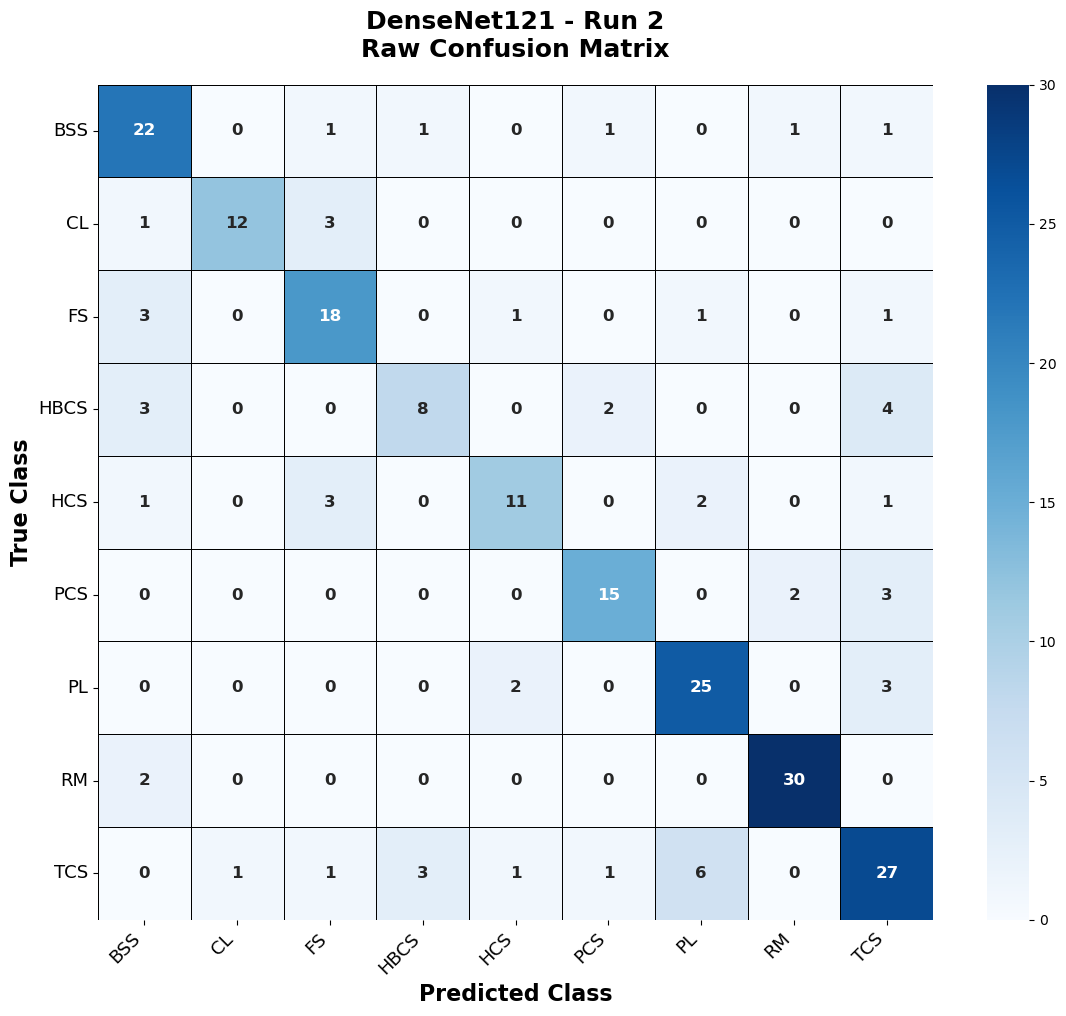

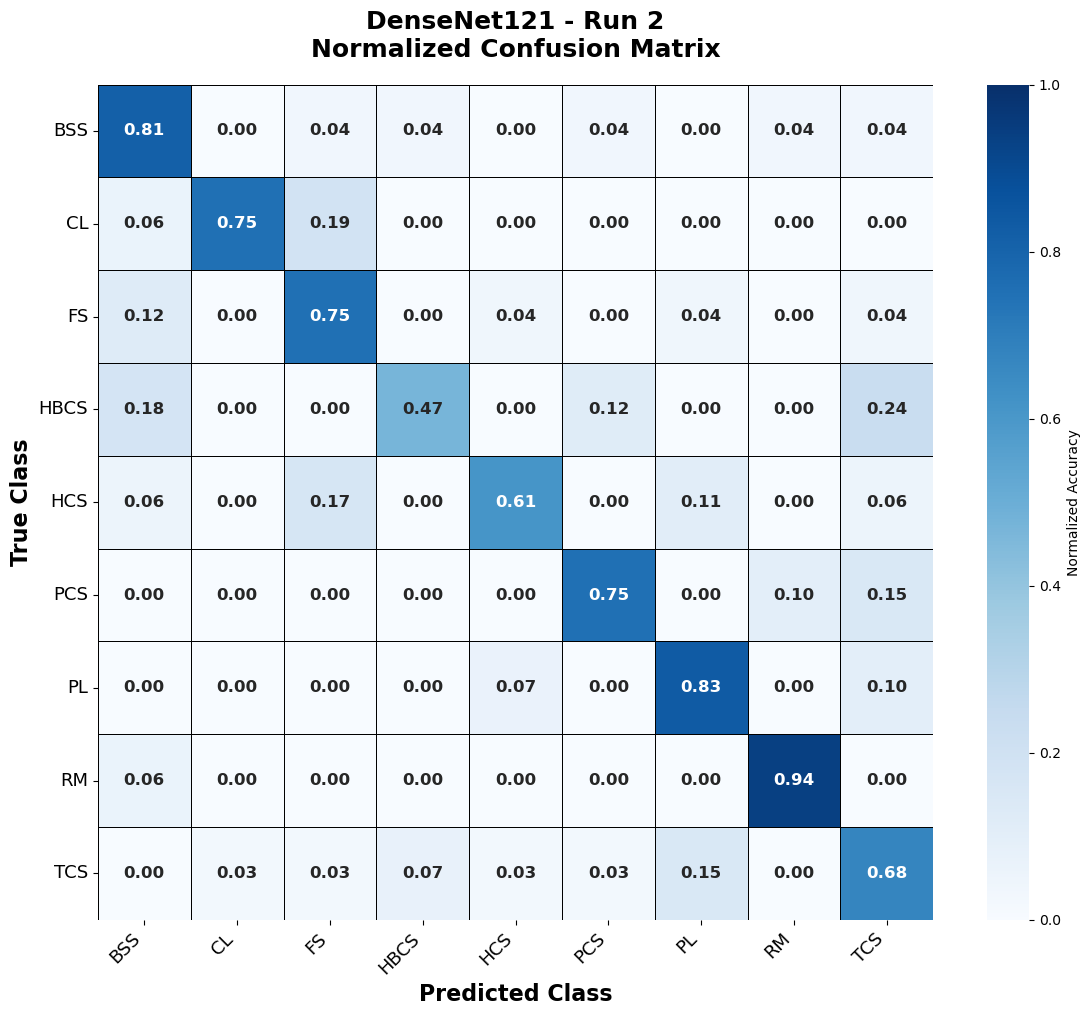


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run2_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run2_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run2_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run2_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN

In [54]:
# ============================================================
# TEST SECTION 6 : CONFUSION MATRIX
# ============================================================

result = plot_confusion_matrix(result)

print("\n" + "="*80)
print("SECTION 6 TEST PASSED")
print("="*80)

print(f"Raw CSV               : {result['raw_confusion_csv']}")
print(f"Normalized CSV        : {result['normalized_confusion_csv']}")
print(f"Raw PNG               : {result['raw_confusion_png']}")
print(f"Normalized PNG        : {result['normalized_confusion_png']}")
print(f"Misclassified CSV     : {result['misclassified_csv']}")

In [55]:
# ============================================================
# STEP 7 : BUILD PREDICTION TABLE
# ============================================================

def build_prediction_table(result):

    print("=" * 80)
    print(f"Prediction Table : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Extract prediction results
    # --------------------------------------------------------

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    y_prob = result["y_prob"]

    classes = result["classes"]

    image_names = result["test_files"]
    image_paths = result["test_paths"]

    model_name = result["model_name"]
    run_number = result["run"]

    # --------------------------------------------------------
    # Initialize prediction table
    # --------------------------------------------------------

    prediction_rows = []

    # --------------------------------------------------------
    # Process every test image
    # --------------------------------------------------------

    for i in range(len(y_true)):

        probs = y_prob[i]

        # Top-1 prediction
        top1_idx = np.argmax(probs)
        top1_prob = probs[top1_idx]

        # Top-2 prediction
        sorted_idx = np.argsort(probs)[::-1]

        top2_idx = sorted_idx[1]
        top2_prob = probs[top2_idx]

        # True class probability
        true_prob = probs[y_true[i]]

        # Confidence margin
        margin = top1_prob - top2_prob

        prediction_rows.append({

            "Model": model_name,

            "Run": run_number,

            "Image_Name": image_names[i],

            "Image_Path": image_paths[i],

            "True_Index": int(y_true[i]),

            "Predicted_Index": int(y_pred[i]),

            "True_Class": classes[y_true[i]],

            "Predicted_Class": classes[y_pred[i]],

            "Correct": y_true[i] == y_pred[i],

            "Prediction_Probability": float(top1_prob),

            "True_Class_Probability": float(true_prob),

            "Second_Best_Class": classes[top2_idx],

            "Second_Best_Probability": float(top2_prob),

            "Confidence_Margin": float(margin)

        })

    # --------------------------------------------------------
    # Create DataFrame
    # --------------------------------------------------------

    prediction_df = pd.DataFrame(prediction_rows)

    # --------------------------------------------------------
    # Confidence Category
    # --------------------------------------------------------
    
    prediction_df["Confidence_Category"] = np.select(
    
        [
    
            prediction_df["Prediction_Probability"] >= 0.90,
    
            prediction_df["Prediction_Probability"] >= 0.75,
    
            prediction_df["Prediction_Probability"] >= 0.50
    
        ],
    
        [
    
            "Very High",
    
            "High",
    
            "Moderate"
    
        ],
    
        default="Low"
    
    )    
        
    # --------------------------------------------------------
    # Rank by confidence
    # --------------------------------------------------------

    prediction_df = prediction_df.sort_values(
        by="Prediction_Probability",
        ascending=False
    ).reset_index(drop=True)

    prediction_df.insert(
        0,
        "Confidence_Rank",
        np.arange(1, len(prediction_df) + 1)
    )

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store in Result Dictionary
    # --------------------------------------------------------
    
    result["prediction_table"] = prediction_df
    
    # --------------------------------------------------------
    # Save Prediction Table
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        prediction_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Prediction_Table.csv"
        )
    
        prediction_df.to_csv(
            prediction_file,
            index=False
        )
    
        result["prediction_table_file"] = prediction_file
    
    print("\nPrediction Table Created Successfully")
    print(f"Total Predictions : {len(prediction_df)}")
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-"*60)
        print(f"Prediction Table CSV : {prediction_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Prediction table was not saved.")
    
    return result

print("=" * 80)
print("STEP 7 READY")
print("=" * 80)

STEP 7 READY


In [56]:
# ============================================================
# TEST SECTION 7 : BUILD PREDICTION TABLE
# ============================================================

result = build_prediction_table(result)

print("\n" + "="*80)
print("SECTION 7 TEST PASSED")
print("="*80)

print(f"Prediction Table Shape : {result['prediction_table'].shape}")

if SAVE_PREDICTIONS:
    print(f"Prediction CSV : {result['prediction_table_file']}")

Prediction Table : DenseNet121 | Run 2

Prediction Table Created Successfully
Total Predictions : 224

Files Saved Successfully
------------------------------------------------------------
Prediction Table CSV : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Predictions\DenseNet121_Run2_Prediction_Table.csv

SECTION 7 TEST PASSED
Prediction Table Shape : (224, 16)
Prediction CSV : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Predictions\DenseNet121_Run2_Prediction_Table.csv


In [57]:
# ============================================================
# TEST SECTION 7 : PREDICTION SUMMARY
# ============================================================

def prediction_summary(result):

    print("=" * 80)
    print(f"Prediction Summary : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"]

    # --------------------------------------------------------
    # Basic Statistics
    # --------------------------------------------------------

    total_images = len(prediction_df)

    correct_predictions = prediction_df["Correct"].sum()

    incorrect_predictions = total_images - correct_predictions

    accuracy = (correct_predictions / total_images) * 100

    # --------------------------------------------------------
    # Confidence Statistics
    # --------------------------------------------------------

    avg_confidence = (
        prediction_df["Prediction_Probability"].mean() * 100
    )

    avg_true_probability = (
        prediction_df["True_Class_Probability"].mean() * 100
    )

    avg_margin = (
        prediction_df["Confidence_Margin"].mean() * 100
    )

    # --------------------------------------------------------
    # Correct / Incorrect Confidence
    # --------------------------------------------------------

    correct_df = prediction_df[prediction_df["Correct"]]

    incorrect_df = prediction_df[~prediction_df["Correct"]]

    correct_confidence = (
        correct_df["Prediction_Probability"].mean() * 100
        if len(correct_df) > 0 else 0
    )

    incorrect_confidence = (
        incorrect_df["Prediction_Probability"].mean() * 100
        if len(incorrect_df) > 0 else 0
    )

    # --------------------------------------------------------
    # Build Summary
    # --------------------------------------------------------

    summary = {

        "Model": result["model_name"],

        "Run": result["run"],

        "Total Images": total_images,

        "Correct Predictions": int(correct_predictions),

        "Incorrect Predictions": int(incorrect_predictions),

        "Accuracy ": round(accuracy, 2),

        "Average Prediction Confidence (%)":
            round(avg_confidence, 2),

        "Average True-Class Probability (%)":
            round(avg_true_probability, 2),

        "Average Confidence Margin (%)":
            round(avg_margin, 2),

        "Correct Prediction Confidence (%)":
            round(correct_confidence, 2),

        "Incorrect Prediction Confidence (%)":
            round(incorrect_confidence, 2)

    }

    summary_df = pd.DataFrame([summary])

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["prediction_summary"] = summary_df
    
    # --------------------------------------------------------
    # Save Prediction Summary
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        summary_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Prediction_Summary.csv"
        )
    
        summary_df.to_csv(
            summary_file,
            index=False
        )
    
        result["prediction_summary_file"] = summary_file
    
    # --------------------------------------------------------
    # Display Summary
    # --------------------------------------------------------
    
    print(f"Model                          : {result['model_name']}")
    print(f"Run                            : {result['run']}")
    print("-" * 80)
    print(f"Total Images                   : {total_images}")
    print(f"Correct Predictions            : {correct_predictions}")
    print(f"Incorrect Predictions          : {incorrect_predictions}")
    print(f"Accuracy                   : {accuracy:.2f}")
    print("-" * 80)
    print(f"Average Prediction Confidence  : {avg_confidence:.2f}%")
    print(f"Average True-Class Probability : {avg_true_probability:.2f}%")
    print(f"Average Confidence Margin      : {avg_margin:.2f}%")
    print("-" * 80)
    print(f"Correct Prediction Confidence  : {correct_confidence:.2f}%")
    print(f"Incorrect Prediction Confidence: {incorrect_confidence:.2f}%")
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"Prediction Summary CSV : {summary_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Prediction summary was not saved.")
    
    return result


print("=" * 80)
print("TEST SECTION 7 : PREDICTION SUMMARY")
print("=" * 80)

TEST SECTION 7 : PREDICTION SUMMARY


In [58]:
# ============================================================
# TEST SECTION 7 : PREDICTION SUMMARY
# ============================================================

result = prediction_summary(result)

print("\n" + "=" * 80)
print("SECTION 7 TEST PASSED")
print("=" * 80)

print(result["prediction_summary"])

if SAVE_PREDICTIONS:
    print(f"\nPrediction Summary CSV : {result['prediction_summary_file']}")

Prediction Summary : DenseNet121 | Run 2
Model                          : DenseNet121
Run                            : 2
--------------------------------------------------------------------------------
Total Images                   : 224
Correct Predictions            : 168
Incorrect Predictions          : 56
Accuracy                   : 75.00
--------------------------------------------------------------------------------
Average Prediction Confidence  : 83.23%
Average True-Class Probability : 69.30%
Average Confidence Margin      : 72.52%
--------------------------------------------------------------------------------
Correct Prediction Confidence  : 88.33%
Incorrect Prediction Confidence: 67.93%

Files Saved Successfully
------------------------------------------------------------
Prediction Summary CSV : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Predictions\DenseNet121_Run2_Prediction_Summary.csv

SECTION 7 TES

In [59]:
# ============================================================
# STEP 7C : BEST & WORST PREDICTIONS
# ============================================================

def analyze_predictions(result):

    print("=" * 80)
    print(f"Prediction Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"]

    # --------------------------------------------------------
    # Separate Correct and Incorrect Predictions
    # --------------------------------------------------------

    correct_df = prediction_df[
        prediction_df["Correct"] == True
    ].copy()

    incorrect_df = prediction_df[
        prediction_df["Correct"] == False
    ].copy()

    # --------------------------------------------------------
    # Highest Confidence Correct Predictions
    # --------------------------------------------------------

    best_predictions = correct_df.sort_values(
        by="Prediction_Probability",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Lowest Confidence Correct Predictions
    # --------------------------------------------------------

    weakest_correct = correct_df.sort_values(
        by="Prediction_Probability",
        ascending=True
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Highest Confidence Incorrect Predictions
    # --------------------------------------------------------

    dangerous_predictions = incorrect_df.sort_values(
        by="Prediction_Probability",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Lowest Confidence Incorrect Predictions
    # --------------------------------------------------------

    uncertain_predictions = incorrect_df.sort_values(
        by="Prediction_Probability",
        ascending=True
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["best_predictions"] = best_predictions
    result["weakest_correct_predictions"] = weakest_correct
    result["dangerous_predictions"] = dangerous_predictions
    result["uncertain_predictions"] = uncertain_predictions
    
    # --------------------------------------------------------
    # Save Analysis Tables
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        best_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Best_Predictions.csv"
        )
    
        weakest_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Weakest_Correct_Predictions.csv"
        )
    
        dangerous_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Dangerous_Predictions.csv"
        )
    
        uncertain_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Uncertain_Predictions.csv"
        )
    
        best_predictions.to_csv(best_file, index=False)
        weakest_correct.to_csv(weakest_file, index=False)
        dangerous_predictions.to_csv(dangerous_file, index=False)
        uncertain_predictions.to_csv(uncertain_file, index=False)
    
        result["best_predictions_file"] = best_file
        result["weakest_correct_predictions_file"] = weakest_file
        result["dangerous_predictions_file"] = dangerous_file
        result["uncertain_predictions_file"] = uncertain_file
    
    # --------------------------------------------------------
    # Display Summary
    # --------------------------------------------------------
    
    print(f"Best Correct Predictions          : {len(best_predictions)}")
    print(f"Weakest Correct Predictions       : {len(weakest_correct)}")
    print(f"High Confidence Wrong Predictions : {len(dangerous_predictions)}")
    print(f"Low Confidence Wrong Predictions  : {len(uncertain_predictions)}")
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"Best Predictions CSV             : {best_file.resolve()}")
        print(f"Weakest Correct CSV              : {weakest_file.resolve()}")
        print(f"Dangerous Predictions CSV        : {dangerous_file.resolve()}")
        print(f"Uncertain Predictions CSV        : {uncertain_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Prediction analysis tables were not saved.")
    
    return result

print("=" * 80)
print("STEP 7C READY")
print("=" * 80)

STEP 7C READY


In [60]:
# ============================================================
# TEST SECTION 7C : PREDICTION ANALYSIS
# ============================================================

result = analyze_predictions(result)

print("\n" + "=" * 80)
print("SECTION 7 TEST PASSED")
print("=" * 80)

print(f"Best Predictions           : {len(result['best_predictions'])}")
print(f"Weakest Correct            : {len(result['weakest_correct_predictions'])}")
print(f"Dangerous Predictions      : {len(result['dangerous_predictions'])}")
print(f"Uncertain Predictions      : {len(result['uncertain_predictions'])}")

if SAVE_PREDICTIONS:
    print(f"\nBest Predictions CSV       : {result['best_predictions_file']}")
    print(f"Weakest Correct CSV        : {result['weakest_correct_predictions_file']}")
    print(f"Dangerous Predictions CSV  : {result['dangerous_predictions_file']}")
    print(f"Uncertain Predictions CSV  : {result['uncertain_predictions_file']}")

Prediction Analysis : DenseNet121 | Run 2
Best Correct Predictions          : 168
Weakest Correct Predictions       : 168
High Confidence Wrong Predictions : 56
Low Confidence Wrong Predictions  : 56

Files Saved Successfully
------------------------------------------------------------
Best Predictions CSV             : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Predictions\DenseNet121_Run2_Best_Predictions.csv
Weakest Correct CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Predictions\DenseNet121_Run2_Weakest_Correct_Predictions.csv
Dangerous Predictions CSV        : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Predictions\DenseNet121_Run2_Dangerous_Predictions.csv
Uncertain Predictions CSV        : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark

In [61]:
# ============================================================
# STEP 8 : CONFIDENCE CATEGORIZATION
# ============================================================

def confidence_analysis(result):

    print("=" * 80)
    print(f"Confidence Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    # --------------------------------------------------------
    # Confidence Categorization Function
    # --------------------------------------------------------

    def classify_confidence(prob):

        if prob >= 0.90:
            return "Excellent", "Very High Confidence"

        elif prob >= 0.70:
            return "Good", "High Confidence"

        elif prob >= 0.50:
            return "Average", "Moderate Confidence"

        else:
            return "Poor", "Low Confidence"

    # --------------------------------------------------------
    # Assign Categories
    # --------------------------------------------------------

    categories = prediction_df["Prediction_Probability"].apply(
        classify_confidence
    )

    prediction_df["Confidence_Category"] = [
        c[0] for c in categories
    ]

    prediction_df["Confidence_Level"] = [
        c[1] for c in categories
    ]

    # --------------------------------------------------------
    # Store Updated Table
    # --------------------------------------------------------

    result["prediction_table"] = prediction_df

    # --------------------------------------------------------
    # Category Statistics
    # --------------------------------------------------------

    confidence_summary = (
        prediction_df["Confidence_Category"]
        .value_counts()
        .reindex(
            ["Excellent", "Good", "Average", "Poor"],
            fill_value=0
        )
    )

    confidence_df = confidence_summary.reset_index()

    confidence_df.columns = [
        "Confidence_Category",
        "Number_of_Images"
    ]

    confidence_df["Percentage"] = (
        confidence_df["Number_of_Images"]
        / len(prediction_df)
        * 100
    ).round(2)

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["confidence_summary"] = confidence_df
    
    # --------------------------------------------------------
    # Save Confidence Summary
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        confidence_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Confidence_Summary.csv"
        )
    
        confidence_df.to_csv(
            confidence_file,
            index=False
        )
    
        result["confidence_summary_file"] = confidence_file
    
    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------
    
    print("\nConfidence Category Distribution")
    print("-" * 80)
    print(confidence_df)
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"Confidence Summary CSV : {confidence_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Confidence summary was not saved.")
    
    return result


print("=" * 80)
print("STEP 8 READY")
print("=" * 80)

STEP 8 READY


In [62]:
# ============================================================
# TEST SECTION 8 : CONFIDENCE CATEGORIZATION
# ============================================================

result = confidence_analysis(result)

print("\n" + "=" * 80)
print("SECTION 8 TEST PASSED")
print("=" * 80)

print(result["confidence_summary"])

if SAVE_PREDICTIONS:
    print(f"\nConfidence Summary CSV : {result['confidence_summary_file']}")

Confidence Analysis : DenseNet121 | Run 2

Confidence Category Distribution
--------------------------------------------------------------------------------
  Confidence_Category  Number_of_Images  Percentage
0           Excellent               125       55.80
1                Good                42       18.75
2             Average                36       16.07
3                Poor                21        9.38

Files Saved Successfully
------------------------------------------------------------
Confidence Summary CSV : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Predictions\DenseNet121_Run2_Confidence_Summary.csv

SECTION 8 TEST PASSED
  Confidence_Category  Number_of_Images  Percentage
0           Excellent               125       55.80
1                Good                42       18.75
2             Average                36       16.07
3                Poor                21        9.38

Confidence Summary CSV

In [63]:
# ============================================================
# STEP 8B : CONFIDENCE vs CORRECTNESS ANALYSIS
# ============================================================

def confidence_correctness_analysis(result):

    print("=" * 80)
    print(f"Confidence vs Correctness : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    confidence_order = [
        "Excellent",
        "Good",
        "Average",
        "Poor"
    ]

    # --------------------------------------------------------
    # Confidence vs Correctness
    # --------------------------------------------------------

    summary = []

    for category in confidence_order:

        subset = prediction_df[
            prediction_df["Confidence_Category"] == category
        ]

        total = len(subset)

        correct = subset["Correct"].sum()

        incorrect = total - correct

        accuracy = (
            (correct / total) * 100
            if total > 0 else 0
        )

        mean_confidence = (
            subset["Prediction_Probability"].mean() * 100
            if total > 0 else 0
        )

        summary.append({

            "Confidence_Category": category,

            "Total_Images": total,

            "Correct": int(correct),

            "Incorrect": int(incorrect),

            "Accuracy": round(accuracy, 2),

            "Mean_Confidence (%)": round(mean_confidence, 2)

        })

    confidence_correctness_df = pd.DataFrame(summary)

    # --------------------------------------------------------
    # High Confidence Wrong Predictions
    # --------------------------------------------------------

    high_conf_wrong = prediction_df[
        (prediction_df["Correct"] == False) &
        (prediction_df["Confidence_Category"].isin(
            ["Excellent", "Good"]
        ))
    ].copy()

    high_conf_wrong = high_conf_wrong.sort_values(
        by="Prediction_Probability",
        ascending=False
    )

    # --------------------------------------------------------
    # Low Confidence Correct Predictions
    # --------------------------------------------------------

    low_conf_correct = prediction_df[
        (prediction_df["Correct"] == True) &
        (prediction_df["Confidence_Category"].isin(
            ["Average", "Poor"]
        ))
    ].copy()

    low_conf_correct = low_conf_correct.sort_values(
        by="Prediction_Probability",
        ascending=True
    )

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["confidence_correctness"] = confidence_correctness_df
    result["high_confidence_wrong"] = high_conf_wrong
    result["low_confidence_correct"] = low_conf_correct
    
    # --------------------------------------------------------
    # Save Results
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        summary_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Confidence_Correctness_Summary.csv"
        )
    
        high_wrong_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_High_Confidence_Wrong.csv"
        )
    
        low_correct_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Low_Confidence_Correct.csv"
        )
    
        confidence_correctness_df.to_csv(summary_file, index=False)
        high_conf_wrong.to_csv(high_wrong_file, index=False)
        low_conf_correct.to_csv(low_correct_file, index=False)
    
        result["confidence_correctness_file"] = summary_file
        result["high_confidence_wrong_file"] = high_wrong_file
        result["low_confidence_correct_file"] = low_correct_file
    
    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------
    
    print("\nConfidence vs Correctness Summary")
    print("-" * 80)
    print(confidence_correctness_df)
    
    print(f"\nHigh Confidence Wrong Predictions : {len(high_conf_wrong)}")
    print(f"Low Confidence Correct Predictions: {len(low_conf_correct)}")
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"Confidence Summary CSV     : {summary_file.resolve()}")
        print(f"High Confidence Wrong CSV  : {high_wrong_file.resolve()}")
        print(f"Low Confidence Correct CSV : {low_correct_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Confidence analysis files were not saved.")
    
    return result


print("=" * 80)
print("STEP 8B READY")
print("=" * 80)

STEP 8B READY


In [64]:
# ============================================================
# TEST SECTION 8B : CONFIDENCE vs CORRECTNESS ANALYSIS
# ============================================================

result = confidence_correctness_analysis(result)

print("\n" + "=" * 80)
print("SECTION 8 TEST PASSED")
print("=" * 80)

print(result["confidence_correctness"])

if SAVE_PREDICTIONS:
    print(f"\nSummary CSV              : {result['confidence_correctness_file']}")
    print(f"High Wrong CSV           : {result['high_confidence_wrong_file']}")
    print(f"Low Correct CSV          : {result['low_confidence_correct_file']}")

Confidence vs Correctness : DenseNet121 | Run 2

Confidence vs Correctness Summary
--------------------------------------------------------------------------------
  Confidence_Category  Total_Images  Correct  Incorrect  Accuracy  \
0           Excellent           125      113         12     90.40   
1                Good            42       29         13     69.05   
2             Average            36       19         17     52.78   
3                Poor            21        7         14     33.33   

   Mean_Confidence (%)  
0                97.76  
1                79.77  
2                60.49  
3                42.63  

High Confidence Wrong Predictions : 25
Low Confidence Correct Predictions: 26

Files Saved Successfully
------------------------------------------------------------
Confidence Summary CSV     : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Predictions\DenseNet121_Run2_Confidence_Correctness_Summa

In [65]:
# ============================================================
# STEP 8C : CLASS-WISE CONFIDENCE ANALYSIS
# ============================================================

def classwise_confidence_analysis(result):

    print("=" * 80)
    print(f"Class-wise Confidence Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    classes = result["classes"]

    confidence_order = [
        "Excellent",
        "Good",
        "Average",
        "Poor"
    ]

    # --------------------------------------------------------
    # Class-wise Analysis
    # --------------------------------------------------------

    class_summary = []

    for cls in classes:

        class_df = prediction_df[
            prediction_df["True_Class"] == cls
        ]

        total = len(class_df)

        if total == 0:
            continue

        correct = class_df["Correct"].sum()

        incorrect = total - correct

        accuracy = (correct / total) * 100

        mean_conf = (
            class_df["Prediction_Probability"].mean() * 100
        )

        median_conf = (
            class_df["Prediction_Probability"].median() * 100
        )

        min_conf = (
            class_df["Prediction_Probability"].min() * 100
        )

        max_conf = (
            class_df["Prediction_Probability"].max() * 100
        )

        std_conf = (
            class_df["Prediction_Probability"].std() * 100
        )

        row = {

            "Class": cls,

            "Total Images": total,

            "Correct": int(correct),

            "Incorrect": int(incorrect),

            "Accuracy": round(accuracy,2),

            "Mean Confidence (%)": round(mean_conf,2),

            "Median Confidence (%)": round(median_conf,2),

            "Std Confidence (%)": round(std_conf,2),

            "Min Confidence (%)": round(min_conf,2),

            "Max Confidence (%)": round(max_conf,2)

        }

        # --------------------------------------------
        # Confidence Category Counts
        # --------------------------------------------

        for category in confidence_order:

            row[category] = int(
                (class_df["Confidence_Category"] == category).sum()
            )

        class_summary.append(row)

    classwise_df = pd.DataFrame(class_summary)

    # --------------------------------------------------------
    # Sort by Accuracy
    # --------------------------------------------------------

    classwise_df = classwise_df.sort_values(
        by="Accuracy",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["classwise_confidence"] = classwise_df
    
    # --------------------------------------------------------
    # Save Results
    # --------------------------------------------------------
    
    if SAVE_PREDICTIONS:
    
        classwise_file = (
            PREDICTIONS_DIR /
            f"{result['model_name']}_Run{result['run']}_Classwise_Confidence_Analysis.csv"
        )
    
        classwise_df.to_csv(
            classwise_file,
            index=False
        )
    
        result["classwise_confidence"] = classwise_file
    
    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------
    
    print("\nClass-wise Confidence Summary")
    print("-" * 80)
    print(classwise_df)
    
    if SAVE_PREDICTIONS:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"Class-wise Confidence CSV : {classwise_file.resolve()}")
    
    else:
    
        print("\nSAVE_PREDICTIONS = False")
        print("Class-wise confidence analysis was not saved.")
    
    return result


print("=" * 80)
print("STEP 8C READY")
print("=" * 80)

STEP 8C READY


In [66]:
# ============================================================
# TEST SECTION 8 : CLASS-WISE CONFIDENCE ANALYSIS
# ============================================================

result = classwise_confidence_analysis(result)

print("\n" + "=" * 80)
print("SECTION 8 TEST PASSED")
print("=" * 80)

print(result["classwise_confidence"])

if SAVE_PREDICTIONS:
    print(f"\nClass-wise Confidence CSV : {result['classwise_confidence']}")

Class-wise Confidence Analysis : DenseNet121 | Run 2

Class-wise Confidence Summary
--------------------------------------------------------------------------------
  Class  Total Images  Correct  Incorrect  Accuracy  Mean Confidence (%)  \
0    RM            32       30          2     93.75                93.81   
1    PL            30       25          5     83.33                90.95   
2   BSS            27       22          5     81.48                81.90   
3    CL            16       12          4     75.00                90.55   
4    FS            24       18          6     75.00                84.10   
5   PCS            20       15          5     75.00                80.70   
6   TCS            40       27         13     67.50                75.70   
7   HCS            18       11          7     61.11                77.48   
8  HBCS            17        8          9     47.06                70.47   

   Median Confidence (%)  Std Confidence (%)  Min Confidence (%)  \
0     

In [67]:
# ============================================================
# STEP 9 : MULTI-CLASS ROC CURVES & AUC ANALYSIS
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_multiclass_roc(result):

    print("=" * 80)
    print(f"ROC Curve : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Data
    # --------------------------------------------------------

    y_true = result["y_true"]
    y_prob = result["y_prob"]
    classes = result["classes"]

    n_classes = len(classes)

    # --------------------------------------------------------
    # Binarize Labels
    # --------------------------------------------------------

    y_true_bin = label_binarize(
        y_true,
        classes=np.arange(n_classes)
    )

    fpr = {}
    tpr = {}
    roc_auc = {}

    # --------------------------------------------------------
    # Per-Class ROC
    # --------------------------------------------------------

    for i in range(n_classes):

        fpr[i], tpr[i], _ = roc_curve(
            y_true_bin[:, i],
            y_prob[:, i]
        )

        roc_auc[i] = auc(
            fpr[i],
            tpr[i]
        )

    # --------------------------------------------------------
    # Micro Average
    # --------------------------------------------------------

    fpr["micro"], tpr["micro"], _ = roc_curve(
        y_true_bin.ravel(),
        y_prob.ravel()
    )

    roc_auc["micro"] = auc(
        fpr["micro"],
        tpr["micro"]
    )

    # --------------------------------------------------------
    # Macro Average
    # --------------------------------------------------------

    roc_auc["macro"] = np.mean(
        [roc_auc[i] for i in range(n_classes)]
    )

    # --------------------------------------------------------
    # Weighted Average
    # --------------------------------------------------------

    class_counts = np.bincount(y_true)

    roc_auc["weighted"] = np.average(
        [roc_auc[i] for i in range(n_classes)],
        weights=class_counts
    )

    # --------------------------------------------------------
    # Plot ROC Curves
    # --------------------------------------------------------

    plt.figure(figsize=(10,8))

    # --------------------------------------------------------
    # Plot ROC Curves (Sorted by AUC)
    # --------------------------------------------------------
    
    sorted_classes = sorted(
        range(n_classes),
        key=lambda x: roc_auc[x],
        reverse=True
    )
    
    colors = plt.cm.tab10(np.linspace(0,1,n_classes))
    
    for color, i in zip(colors, sorted_classes):
    
        plt.plot(
            fpr[i],
            tpr[i],
            lw=2,
            color=color,
            label=f"{classes[i]} (AUC={roc_auc[i]:.3f})"
        )
    plt.plot(
        fpr["micro"],
        tpr["micro"],
        color="black",
        linestyle="--",
        linewidth=4,
        label=f"Micro Average (AUC={roc_auc['micro']:.3f})"
    )

    plt.plot(
        [0,1],
        [0,1],
        linestyle=":",
        color="gray"
    )

    plt.xlabel(
        "False Positive Rate",
        fontsize=16,
        fontweight="bold"
    )

    plt.ylabel(
        "True Positive Rate",
        fontsize=16,
        fontweight="bold"
    )

    plt.title(
        f"{result['model_name']} | Run {result['run']}\nMulti-Class ROC Curve (One-vs-Rest)",
        fontsize=18,
        fontweight="bold"
    )

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.legend(
        fontsize=9,
        loc="lower right",
        frameon=True
    )
    plt.grid(alpha=0.3)
    
    plt.xlim([0,1])
    plt.ylim([0,1.02])
    
    plt.tight_layout()

    # --------------------------------------------------------
    # Save Figure
    # --------------------------------------------------------

    save_png = (
        ROC_DIR /
        f"{result['model_name']}_Run{result['run']}_ROC.png"
    )


    
    if SAVE_ROC:
    
        plt.savefig(
            save_png,
            dpi=300,
            bbox_inches="tight"
        )
    
    plt.show()


    # --------------------------------------------------------
    # --------------------------------------------------------
    # AUC Interpretation Function
    # --------------------------------------------------------
    
    def auc_interpretation(x):
    
        if x >= 0.99:
            return "Outstanding"
    
        elif x >= 0.90:
            return "Excellent"
    
        elif x >= 0.80:
            return "Good"
    
        elif x >= 0.70:
            return "Fair"
    
        elif x >= 0.60:
            return "Poor"
    
        else:
            return "Fail"
    
     
    # --------------------------------------------------------
    # --------------------------------------------------------
    # Create Class-wise AUC Table
    # --------------------------------------------------------
    
    class_auc_df = pd.DataFrame({
    
        "Class": classes,
    
        "AUC": [roc_auc[i] for i in range(n_classes)]
    
    })
    
    class_auc_df["Performance"] = (
        class_auc_df["AUC"]
        .apply(auc_interpretation)
    )
    
    class_auc_df = class_auc_df.sort_values(
        by="AUC",
        ascending=False
    ).reset_index(drop=True)
    
    # --------------------------------------------------------
    # Best & Worst AUC Classes
    # --------------------------------------------------------
    
    result["best_auc_class"] = class_auc_df.iloc[0].to_dict()
    result["worst_auc_class"] = class_auc_df.iloc[-1].to_dict()
    
    # --------------------------------------------------------
    # Overall ROC Summary
    # --------------------------------------------------------
    
    excellent_classes = int(
        (class_auc_df["AUC"] >= 0.90).sum()
    )
    
    result["excellent_auc_classes"] = excellent_classes
    result["n_classes"] = n_classes
    
    summary_df = pd.DataFrame({
    
        "Class": [
            "Micro Average",
            "Macro Average",
            "Weighted Average"
        ],
    
        "AUC": [
            roc_auc["micro"],
            roc_auc["macro"],
            roc_auc["weighted"]
        ],
    
        "Performance": [
            "Summary",
            "Summary",
            "Summary"
        ]
    
    })
    
    # --------------------------------------------------------
    # Final AUC Table
    # --------------------------------------------------------
    
    auc_df = pd.concat(
        [class_auc_df, summary_df],
        ignore_index=True
    )    
    # --------------------------------------------------------
    # Save CSV
    # --------------------------------------------------------

    auc_csv = (
        ROC_DIR /
        f"{result['model_name']}_Run{result['run']}_AUC.csv"
    )

    if SAVE_ROC:
    
        auc_df.to_csv(
            auc_csv,
            index=False
        )

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    result["roc_fpr"] = fpr
    result["roc_tpr"] = tpr
    result["roc_auc"] = roc_auc
    result["auc_table"] = auc_df
    result["n_classes"] = n_classes
    
    result["roc_curve_png"] = save_png
    result["auc_csv"] = auc_csv
    
    result["auc_summary"] = {
    
        "Micro AUC": round(roc_auc["micro"], 4),
        "Macro AUC": round(roc_auc["macro"], 4),
        "Weighted AUC": round(roc_auc["weighted"], 4)
    
    }
    # ============================================================
    # Save ROC Coordinates
    # ============================================================
    
    roc_rows = []
    
    for i in range(n_classes):
    
        for x, y in zip(fpr[i], tpr[i]):
    
            roc_rows.append({
    
                "Model": result["model_name"],
                "Run": result["run"],                
                "Class": classes[i],
                "AUC": roc_auc[i],
                "FPR": x,
                "TPR": y
    
            })
    
    roc_df = pd.DataFrame(roc_rows)
    
    roc_csv = (
        ROC_DIR /
        f"{result['model_name']}_Run{result['run']}_ROC.csv"
    )
    
    if SAVE_ROC:
    
        roc_df.to_csv(
            roc_csv,
            index=False
        )
    
    result["roc_csv"] = roc_csv
    
    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------
    
    print("\nAUC Values")
    print("-" * 80)
    
    print(auc_df)
    
    print("\nROC Summary")
    print("-" * 80)
    
    excellent_classes = (
        class_auc_df["AUC"] >= 0.90
    ).sum()
    
    result["excellent_auc_classes"] = int(excellent_classes)
    
    print(f"Number of Classes           : {n_classes}")
    print(f"Excellent ROC (AUC ≥ 0.90)  : {excellent_classes}/{n_classes}")
    
    print()
    
    best = result["best_auc_class"]
    worst = result["worst_auc_class"]
    
    print(f"Best Class                  : {best['Class']} ({best['Performance']})")
    print(f"Best AUC                    : {best['AUC']:.4f}")
    
    print()
    
    print(f"Worst Class                 : {worst['Class']} ({worst['Performance']})")
    print(f"Worst AUC                   : {worst['AUC']:.4f}")
    
    print()
    
    print(f"Micro Average               : {roc_auc['micro']:.4f}")
    print(f"Macro Average               : {roc_auc['macro']:.4f}")
    print(f"Weighted Average            : {roc_auc['weighted']:.4f}")
    
    # --------------------------------------------------------
    # Saved Files
    # --------------------------------------------------------
    
    if SAVE_ROC:
    
        print("\nFiles Saved Successfully")
        print("-" * 60)
        print(f"ROC Curve PNG : {save_png.resolve()}")
        print(f"AUC Table CSV : {auc_csv.resolve()}")
    
    else:
    
        print("\nSAVE_ROC = False")
        print("ROC outputs were not saved.")
    
    return result


ROC Curve : DenseNet121 | Run 2


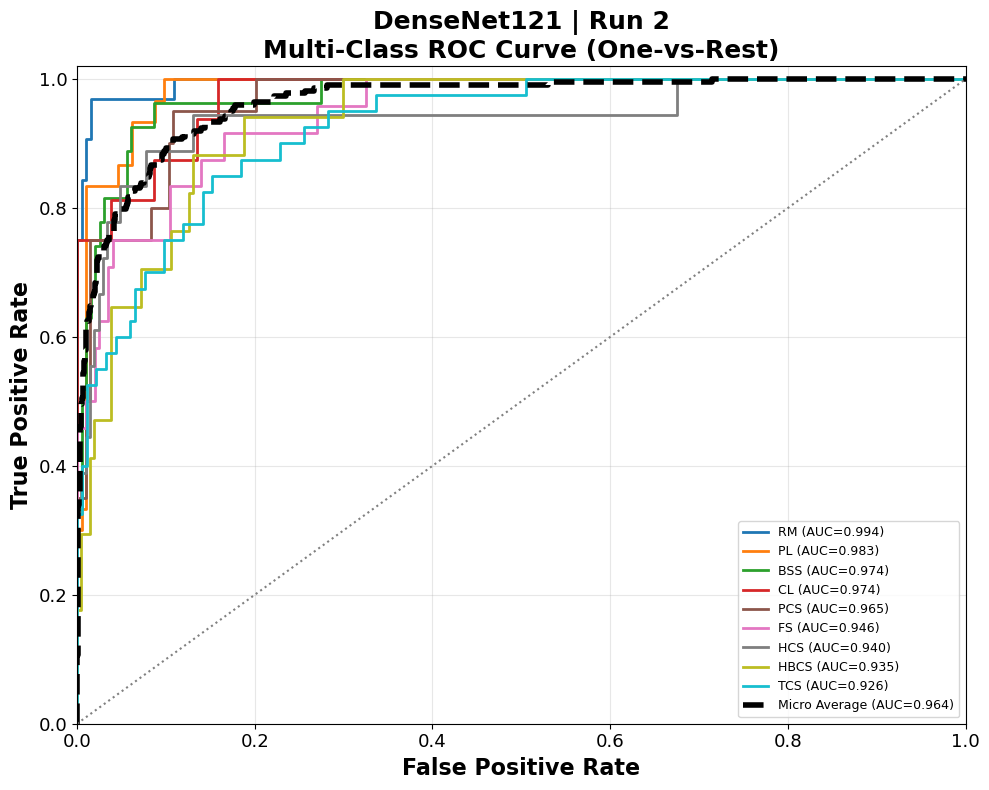


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.994466  Outstanding
1                 PL  0.982818    Excellent
2                BSS  0.974055    Excellent
3                 CL  0.973858    Excellent
4                PCS  0.964951    Excellent
5                 FS  0.946042    Excellent
6                HCS  0.939860    Excellent
7               HBCS  0.935493    Excellent
8                TCS  0.925543    Excellent
9      Micro Average  0.963513      Summary
10     Macro Average  0.959676      Summary
11  Weighted Average  0.959979      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9945

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9255

Micro

In [68]:
# ============================================================
# TEST SECTION 9 : ROC CURVE & AUC ANALYSIS
# ============================================================

result = plot_multiclass_roc(result)

print("\n" + "=" * 80)
print("SECTION 9 TEST PASSED")
print("=" * 80)

print(result["auc_table"])

if SAVE_ROC:
    print(f"\nROC Curve PNG : {result['roc_curve_png']}")
    print(f"AUC Table CSV : {result['auc_csv']}")

In [69]:
# Section 10 Misclassification analysis
def misclassification_analysis(result):

    print("=" * 80)
    print(f"Misclassification Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    # --------------------------------------------------------
    # Keep Only Incorrect Predictions
    # --------------------------------------------------------

    misclassified_df = prediction_df[
        prediction_df["Correct"] == False
    ].copy()

    total_errors = len(misclassified_df)

    if total_errors == 0:

        print("\nNo misclassified samples found.")

        result["misclassification_analysis"] = pd.DataFrame()

        return result

    # --------------------------------------------------------
    # Support (Total Images per True Class)
    # --------------------------------------------------------

    class_support = (
        prediction_df
        .groupby("True_Class")
        .size()
        .to_dict()
    )

    # --------------------------------------------------------
    # Group by Confused Class Pairs
    # --------------------------------------------------------

    summary_df = (

        misclassified_df

        .groupby(
            ["True_Class", "Predicted_Class"],
            as_index=False
        )

        .agg(

            Count=("Correct", "count"),

            Mean_Confidence=(
                "Prediction_Probability",
                lambda x: round(x.mean() * 100, 2)
            ),

            Max_Confidence=(
                "Prediction_Probability",
                lambda x: round(x.max() * 100, 2)
            ),

            Min_Confidence=(
                "Prediction_Probability",
                lambda x: round(x.min() * 100, 2)
            )

        )

    )

    # --------------------------------------------------------
    # Add Support
    # --------------------------------------------------------

    summary_df["Support"] = summary_df["True_Class"].map(class_support)

    # --------------------------------------------------------
    # Overall Error Percentage
    # --------------------------------------------------------

    summary_df["Overall Error (%)"] = (
        summary_df["Count"] /
        total_errors *
        100
    ).round(2)

    # --------------------------------------------------------
    # Class Error Percentage
    # --------------------------------------------------------

    summary_df["Class Error (%)"] = (
        summary_df["Count"] /
        summary_df["Support"] *
        100
    ).round(2)

    # --------------------------------------------------------
    # Sort by Count
    # --------------------------------------------------------

    summary_df = summary_df.sort_values(
        by="Count",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Add Rank
    # --------------------------------------------------------

    summary_df.insert(
        0,
        "Rank",
        np.arange(1, len(summary_df) + 1)
    )

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result["misclassification_analysis"] = summary_df

    # --------------------------------------------------------
    # Save CSV
    # --------------------------------------------------------

    if SAVE_PREDICTIONS:

        misclassification_file = (

            PREDICTIONS_DIR /

            f"{result['model_name']}_Run{result['run']}_Misclassification_Analysis.csv"

        )

        summary_df.to_csv(
            misclassification_file,
            index=False
        )

        result["misclassification_analysis_file"] = misclassification_file

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    print(f"\nTotal Misclassified Images : {total_errors}")

    print("-" * 80)

    print(summary_df)

    if SAVE_PREDICTIONS:

        print("\nFiles Saved Successfully")

        print("-" * 60)

        print(
            f"Misclassification CSV : "
            f"{misclassification_file.resolve()}"
        )

    else:

        print("\nSAVE_PREDICTIONS = False")

        print("Misclassification analysis was not saved.")

    return result

In [70]:
# ============================================================
# TEST SECTION 10 : MISCLASSIFICATION ANALYSIS
# ============================================================

result = misclassification_analysis(result)

print("\n" + "=" * 80)
print("SECTION 10 TEST PASSED")
print("=" * 80)

print(result["misclassification_analysis"])

if SAVE_PREDICTIONS:

    print(
        f"\nCSV : {result['misclassification_analysis_file']}"
    )

Misclassification Analysis : DenseNet121 | Run 2

Total Misclassified Images : 56
--------------------------------------------------------------------------------
    Rank True_Class Predicted_Class  Count  Mean_Confidence  Max_Confidence  \
0      1        TCS              PL      6            61.00           99.91   
1      2       HBCS             TCS      4            68.76           84.40   
2      3       HBCS             BSS      3            44.60           55.16   
3      4         FS             BSS      3            74.60           82.25   
4      5         CL              FS      3            88.97           98.05   
5      6        HCS              FS      3            92.02           97.84   
6      7        PCS             TCS      3            67.09           73.92   
7      8        TCS            HBCS      3            76.87           91.12   
8      9         PL             TCS      3            54.06           65.38   
9     10        HCS              PL      2     

In [71]:
# ============================================================
# SECTION 11 : BENCHMARK SUMMARY
# ============================================================

def benchmark_summary(result):

    print("=" * 80)
    print(f"Benchmark Summary : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Results
    # --------------------------------------------------------

    metrics = result["metrics"]

    roc = result["auc_summary"]

    benchmark = {
    
        "Model": result["model_name"],
    
        "Run": result["run"],
    
        "Total Images": result["total_images"],
    
        "Accuracy": round(metrics["Accuracy"], 4),
    
        "Precision Macro": round(metrics["Precision_Macro"], 4),
    
        "Recall Macro": round(metrics["Recall_Macro"], 4),
    
        "F1 Macro": round(metrics["F1_Macro"], 4),
    
        "Precision Weighted": round(metrics["Precision_Weighted"], 4),
    
        "Recall Weighted": round(metrics["Recall_Weighted"], 4),
    
        "F1 Weighted": round(metrics["F1_Weighted"], 4),
    
        "Balanced Accuracy": round(metrics["Balanced_Accuracy"], 4),
    
        "Cohen Kappa": round(metrics["Cohen_Kappa"], 4),
    
        "MCC": round(metrics["MCC"], 4),
    
        "Log Loss": round(metrics["Log_Loss"], 4),
    
        "Parameters": metrics["Parameters"],
    
        "Trainable Parameters": metrics["Trainable_Parameters"],
    
        "Inference Time (Total, s)": round(
            metrics["Inference_Time_Total"], 4
        ),
    
        "Inference Time/Image (ms)": round(
            metrics["Inference_Time_Per_Image"] * 1000,
            4
        ),
    
        "Micro AUC": roc["Micro AUC"],
    
        "Macro AUC": roc["Macro AUC"],
    
        "Weighted AUC": roc["Weighted AUC"]
    
    }
    benchmark_df = pd.DataFrame([benchmark])

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result["benchmark_summary"] = benchmark_df

    # --------------------------------------------------------
    # Save Results
    # --------------------------------------------------------

    if SAVE_BENCHMARK:

        benchmark_file = (

            BENCHMARK_DIR /

            f"{result['model_name']}_Run{result['run']}_Benchmark_Summary.csv"

        )

        benchmark_df.to_csv(
            benchmark_file,
            index=False
        )

        result["benchmark_summary_file"] = benchmark_file

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    print(benchmark_df)

    if SAVE_BENCHMARK:

        print("\nFiles Saved Successfully")

        print("-" * 60)

        print(
            f"Benchmark Summary CSV : "
            f"{benchmark_file.resolve()}"
        )

    else:

        print("\nSAVE_BENCHMARK = False")

        print("Benchmark summary was not saved.")

    return result


print("=" * 80)
print("SECTION 11 READY")
print("=" * 80)

SECTION 11 READY


In [72]:
# ============================================================
# TEST SECTION 11 : BENCHMARK SUMMARY
# ============================================================

result = benchmark_summary(result)

print("\n" + "=" * 80)
print("SECTION 11 TEST PASSED")
print("=" * 80)

print(result["benchmark_summary"])

if SAVE_BENCHMARK:

    print(
        f"\nBenchmark CSV : "
        f"{result['benchmark_summary_file']}"
    )

Benchmark Summary : DenseNet121 | Run 2
         Model  Run  Total Images  Accuracy  Precision Macro  Recall Macro  \
0  DenseNet121    2           224      0.75           0.7569        0.7325   

   F1 Macro  Precision Weighted  Recall Weighted  F1 Weighted  ...  \
0      0.74              0.7519             0.75       0.7473  ...   

   Cohen Kappa     MCC  Log Loss  Parameters  Trainable Parameters  \
0       0.7146  0.7153    0.8288     8012160               8012160   

   Inference Time (Total, s)  Inference Time/Image (ms)  Micro AUC  Macro AUC  \
0                    12.1565                      54.27     0.9635     0.9597   

   Weighted AUC  
0          0.96  

[1 rows x 21 columns]

Files Saved Successfully
------------------------------------------------------------
Benchmark Summary CSV : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Benchmark\DenseNet121_Run2_Benchmark_Summary.csv

SECTION 11 TEST PASSED
  

In [73]:
# ============================================================
# SECTION 12 : EVALUATION SUMMARY
# ============================================================

def evaluation_summary(result):

    print("=" * 80)
    print(f"Evaluation Summary : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    metrics = result["metrics"]
    benchmark = result["benchmark_summary"]

    print("\nModel Information")
    print("-" * 80)

    print(f"Model                 : {result['model_name']}")
    print(f"Run                   : {result['run']}")
    print(f"Total Images          : {result['total_images']}")

    print("\nPerformance Metrics")
    print("-" * 80)

    print(f"Accuracy              : {metrics['Accuracy']:.4f}")
    print(f"Precision (Macro)     : {metrics['Precision_Macro']:.4f}")
    print(f"Recall (Macro)        : {metrics['Recall_Macro']:.4f}")
    print(f"F1 Score (Macro)      : {metrics['F1_Macro']:.4f}")

    print(f"Precision (Weighted)  : {metrics['Precision_Weighted']:.4f}")
    print(f"Recall (Weighted)     : {metrics['Recall_Weighted']:.4f}")
    print(f"F1 Score (Weighted)   : {metrics['F1_Weighted']:.4f}")

    print(f"Balanced Accuracy     : {metrics['Balanced_Accuracy']:.4f}")
    print(f"Cohen Kappa           : {metrics['Cohen_Kappa']:.4f}")
    print(f"MCC                   : {metrics['MCC']:.4f}")
    print(f"Log Loss              : {metrics['Log_Loss']:.4f}")

    print("\nModel Complexity")
    print("-" * 80)

    print(f"Parameters            : {metrics['Parameters']:,}")
    print(f"Trainable Parameters  : {metrics['Trainable_Parameters']:,}")

    print("\nInference Speed")
    print("-" * 80)

    print(f"Total Time (s)        : {metrics['Inference_Time_Total']:.4f}")
    print(f"Time/Image (ms)       : {metrics['Inference_Time_Per_Image']*1000:.4f}")

    print("\nROC-AUC")
    print("-" * 80)

    print(f"Micro AUC             : {benchmark['Micro AUC'].iloc[0]:.4f}")
    print(f"Macro AUC             : {benchmark['Macro AUC'].iloc[0]:.4f}")
    print(f"Weighted AUC          : {benchmark['Weighted AUC'].iloc[0]:.4f}")

    print("\nGenerated Outputs")
    print("-" * 80)

    print("✓ Metrics")
    print("✓ Classification Report")
    print("✓ Confusion Matrix")
    print("✓ Prediction Table")
    print("✓ Prediction Summary")
    print("✓ Confidence Analysis")
    print("✓ ROC Curve")
    print("✓ Misclassification Analysis")
    print("✓ Benchmark Summary")

    print("\nEvaluation Completed Successfully.")

    return result


print("=" * 80)
print("SECTION 12 READY")
print("=" * 80)

SECTION 12 READY


In [74]:
# ============================================================
# TEST SECTION 12
# ============================================================

result = evaluation_summary(result)

print("\n" + "=" * 80)
print("SECTION 12 TEST PASSED")
print("=" * 80)

Evaluation Summary : DenseNet121 | Run 2

Model Information
--------------------------------------------------------------------------------
Model                 : DenseNet121
Run                   : 2
Total Images          : 224

Performance Metrics
--------------------------------------------------------------------------------
Accuracy              : 0.7500
Precision (Macro)     : 0.7569
Recall (Macro)        : 0.7325
F1 Score (Macro)      : 0.7400
Precision (Weighted)  : 0.7519
Recall (Weighted)     : 0.7500
F1 Score (Weighted)   : 0.7473
Balanced Accuracy     : 0.7325
Cohen Kappa           : 0.7146
MCC                   : 0.7153
Log Loss              : 0.8288

Model Complexity
--------------------------------------------------------------------------------
Parameters            : 8,012,160
Trainable Parameters  : 8,012,160

Inference Speed
--------------------------------------------------------------------------------
Total Time (s)        : 12.1565
Time/Image (ms)       : 54.27

SECTION 13 : BATCH EVALUATION OF ALL CNN MODELS

MODEL : ResNet50

--------------------------------------------------------------------------------
[1/25] Evaluating ResNet50 | Run 1
--------------------------------------------------------------------------------
Evaluating : ResNet50 | Run 1

Loading Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Saved_Models\ResNet50_Run1.pkl
Number of Classes : 9
Classes           : ['BSS', 'CL', 'FS', 'HBCS', 'HCS', 'PCS', 'PL', 'RM', 'TCS']
Loaded Model      : ResNet50_Run1.pkl



Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 11.018 sec
Time / Image     : 0.049186 sec
Computing Metrics : ResNet50 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.8125
Precision (Macro)     : 0.8368
Recall (Macro)        : 0.7987
F1 Score (Macro)      : 0.8139
Precision (Weighted)  : 0.8223
Recall (Weighted)     : 0.8125
F1 Score (Weighted)   : 0.8136
Balanced Accuracy     : 0.7987
Cohen Kappa           : 0.7854
MCC                   : 0.7867
Log Loss              : 0.7394

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\ResNet50_Run1_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\ResNet

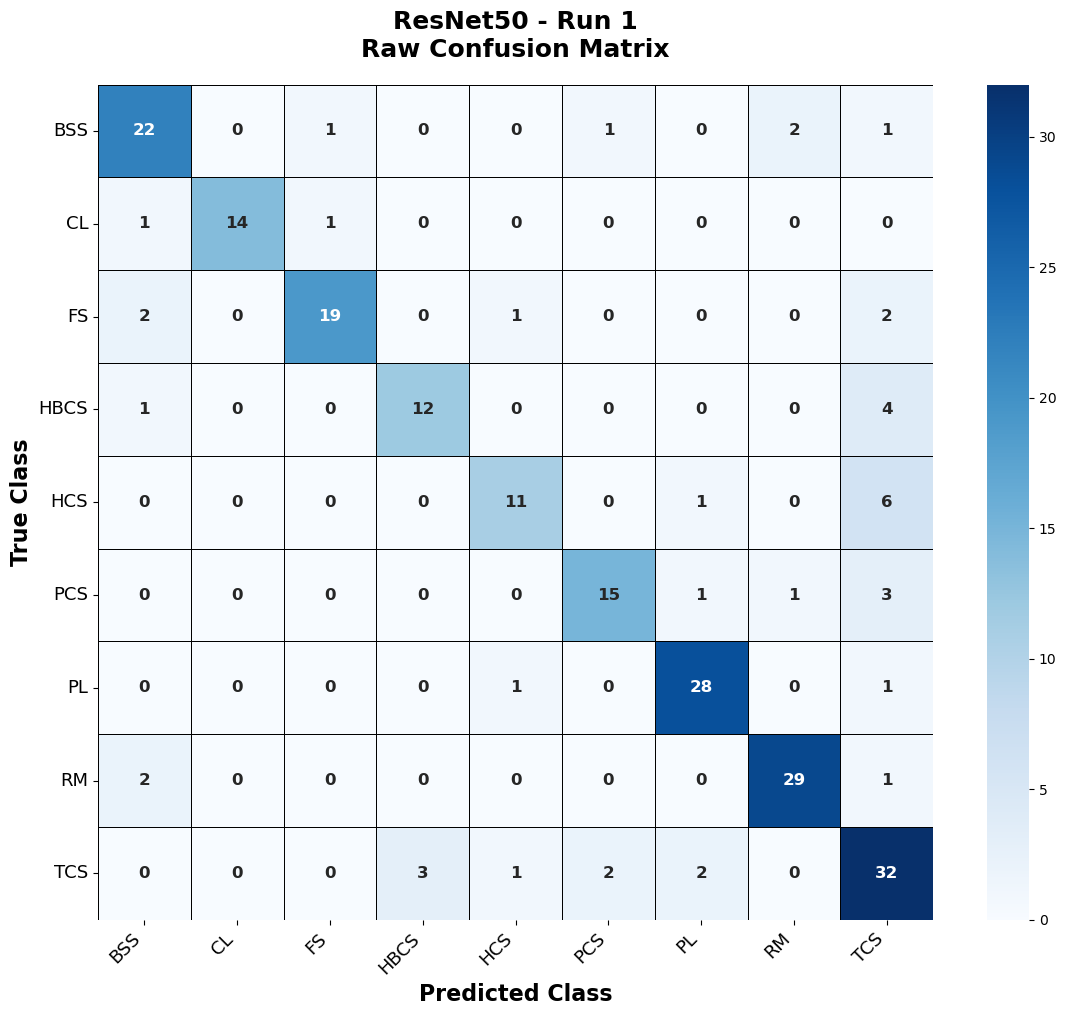

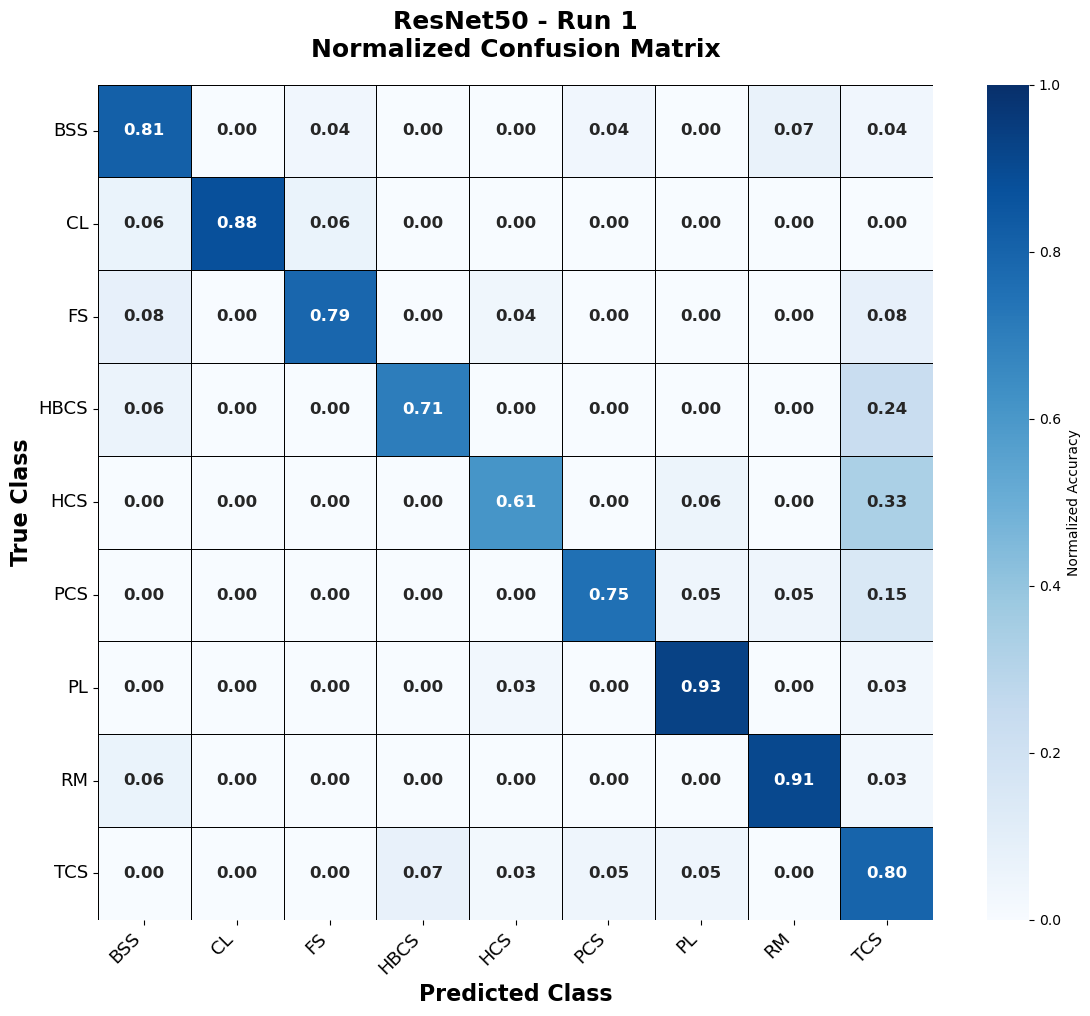


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run1_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run1_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run1_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run1_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Eva

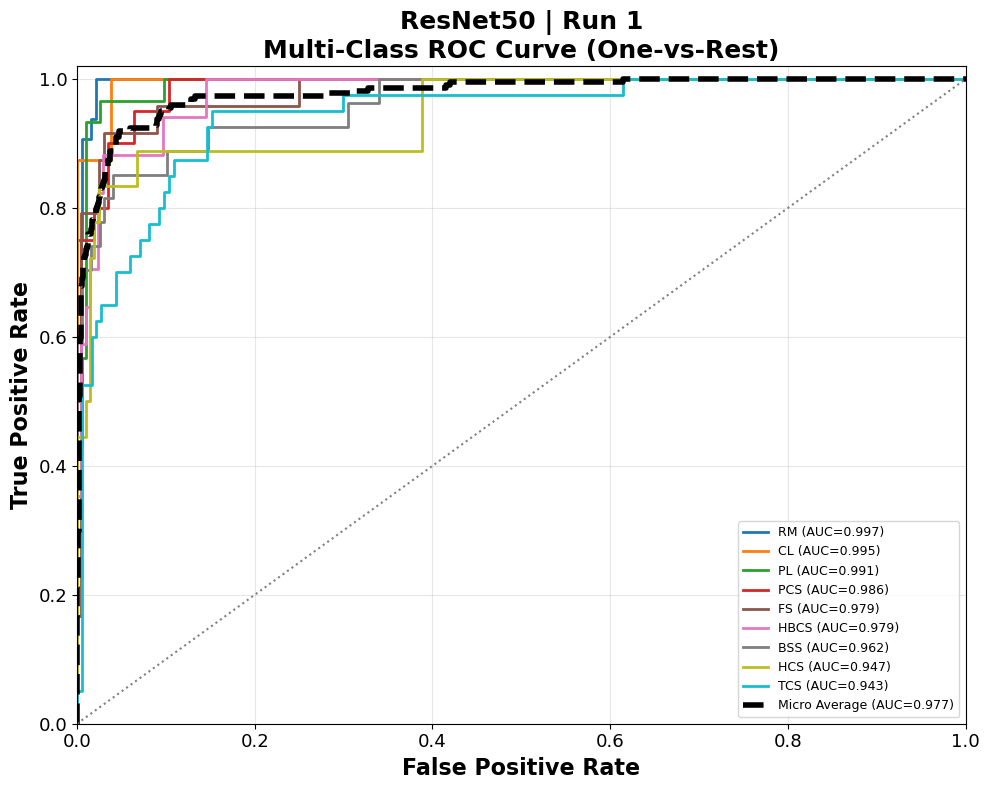


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.997396  Outstanding
1                 CL  0.995192  Outstanding
2                 PL  0.991409  Outstanding
3                PCS  0.986029    Excellent
4                 FS  0.979375    Excellent
5               HBCS  0.978687    Excellent
6                BSS  0.962211    Excellent
7                HCS  0.946872    Excellent
8                TCS  0.943478    Excellent
9      Micro Average  0.977360      Summary
10     Macro Average  0.975628      Summary
11  Weighted Average  0.974142      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9974

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9435

Micro


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 9.767 sec
Time / Image     : 0.043603 sec
Computing Metrics : ResNet50 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.7589
Precision (Macro)     : 0.7706
Recall (Macro)        : 0.7387
F1 Score (Macro)      : 0.7492
Precision (Weighted)  : 0.7654
Recall (Weighted)     : 0.7589
F1 Score (Weighted)   : 0.7565
Balanced Accuracy     : 0.7387
Cohen Kappa           : 0.7241
MCC                   : 0.7257
Log Loss              : 0.8651

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\ResNet50_Run2_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\ResNet5

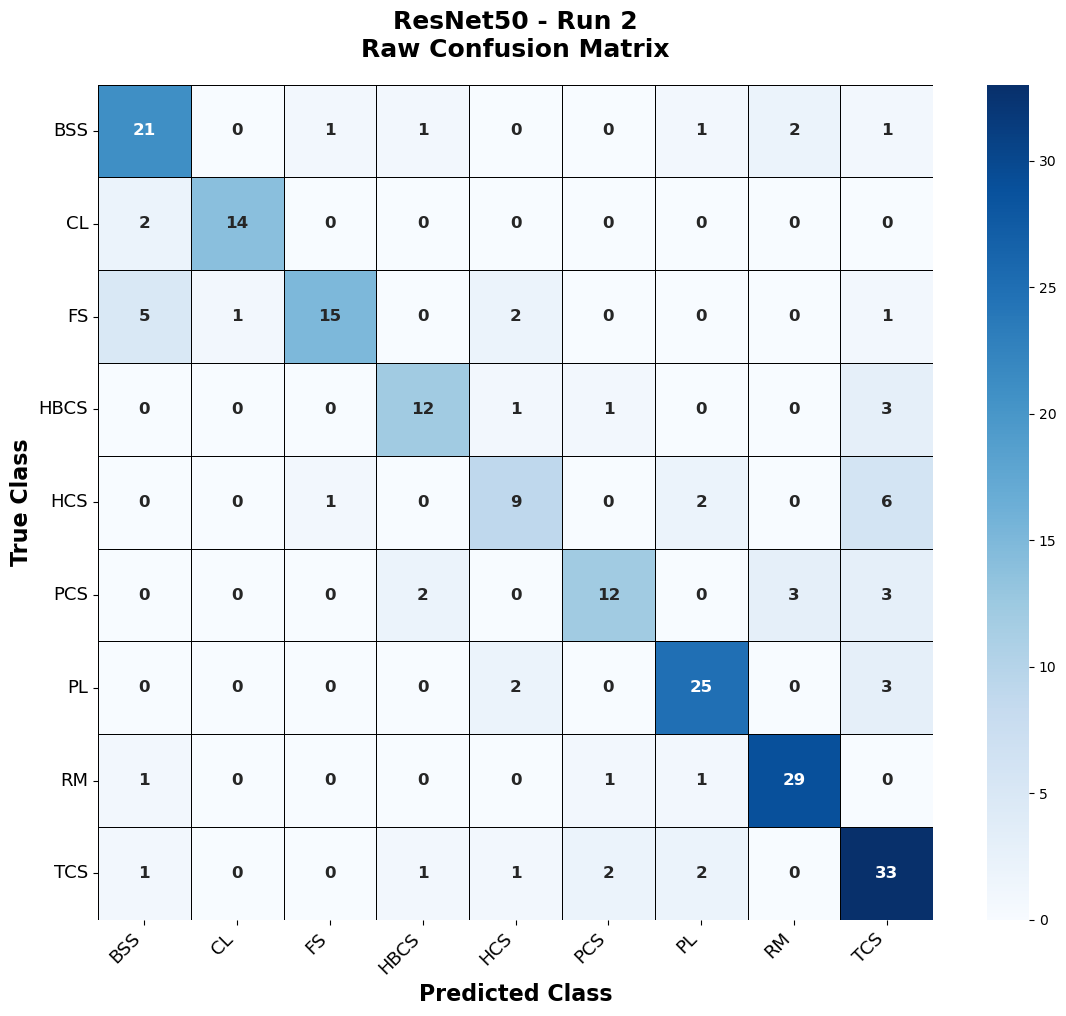

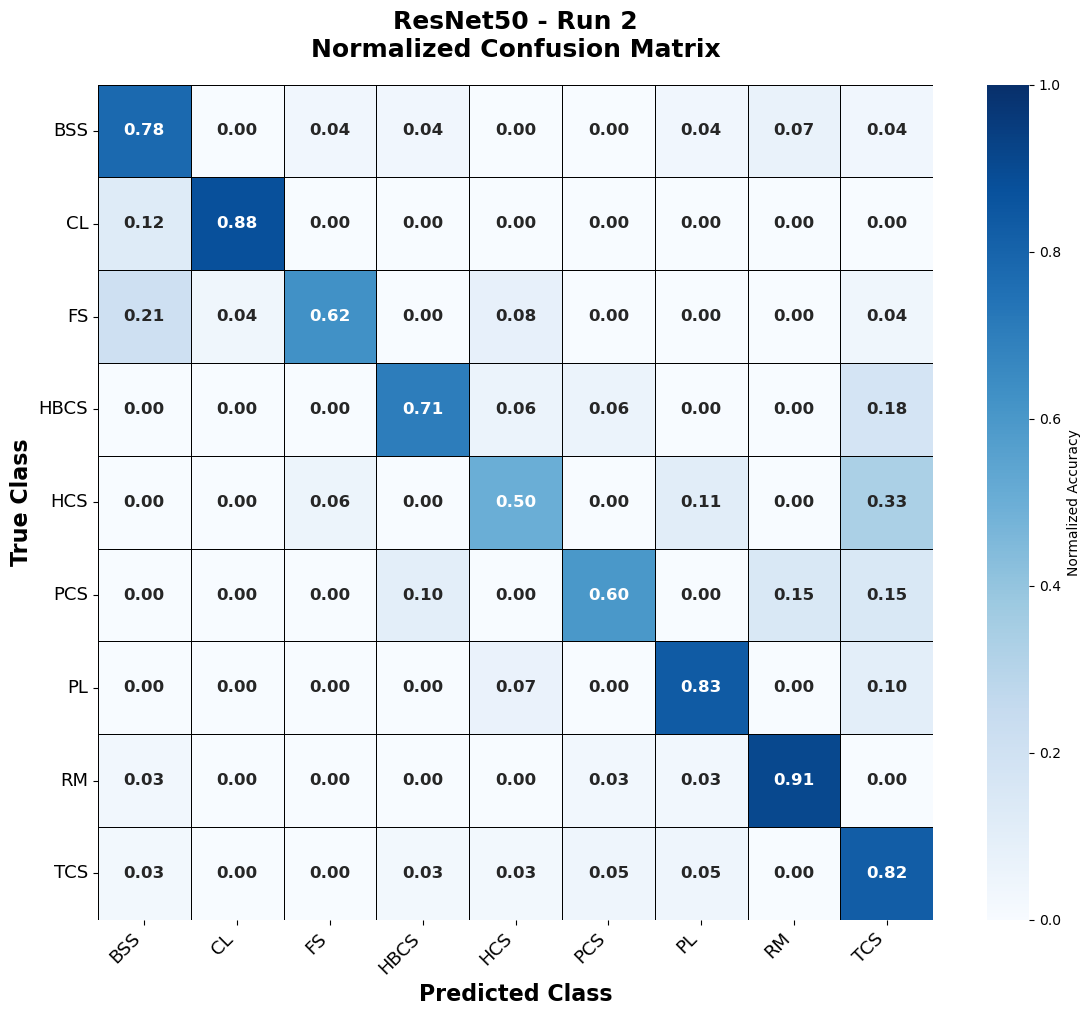


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run2_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run2_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run2_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run2_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Eva

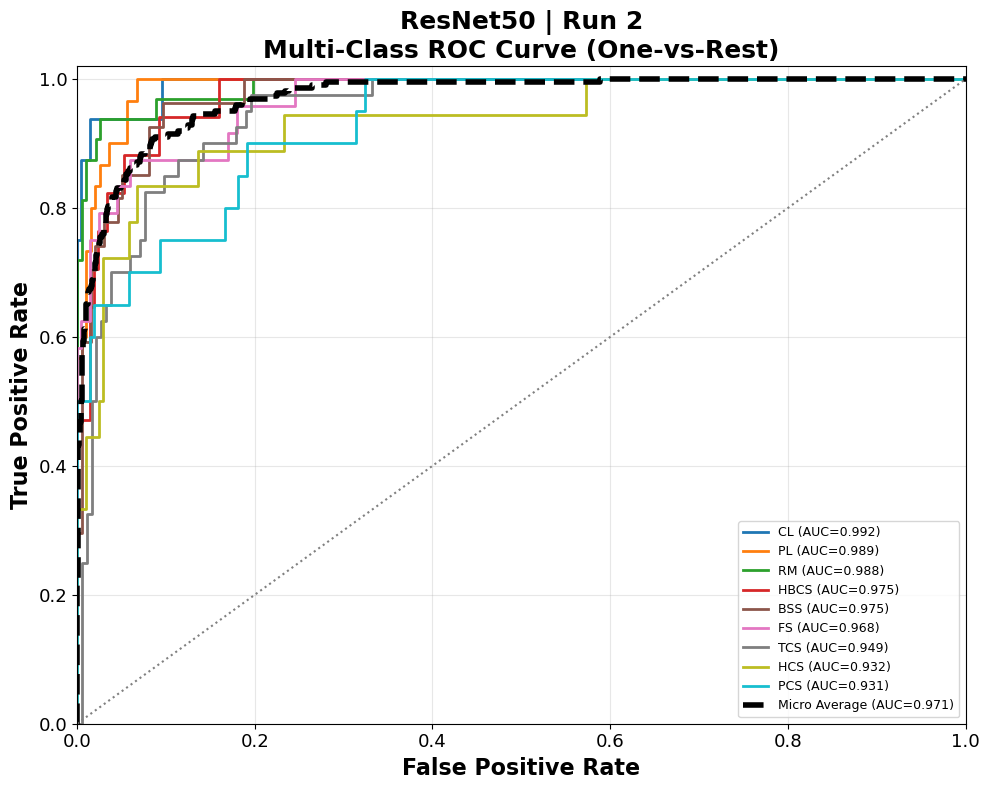


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 CL  0.992488  Outstanding
1                 PL  0.988660    Excellent
2                 RM  0.988444    Excellent
3               HBCS  0.974993    Excellent
4                BSS  0.974807    Excellent
5                 FS  0.967708    Excellent
6                TCS  0.949185    Excellent
7                HCS  0.931769    Excellent
8                PCS  0.931127    Excellent
9      Micro Average  0.970830      Summary
10     Macro Average  0.966576      Summary
11  Weighted Average  0.967193      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : CL (Outstanding)
Best AUC                    : 0.9925

Worst Class                 : PCS (Excellent)
Worst AUC                   : 0.9311

Micro


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 10.551 sec
Time / Image     : 0.047103 sec
Computing Metrics : ResNet50 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.7098
Precision (Macro)     : 0.7030
Recall (Macro)        : 0.6953
F1 Score (Macro)      : 0.6964
Precision (Weighted)  : 0.7088
Recall (Weighted)     : 0.7098
F1 Score (Weighted)   : 0.7064
Balanced Accuracy     : 0.6953
Cohen Kappa           : 0.6690
MCC                   : 0.6697
Log Loss              : 0.8547

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\ResNet50_Run3_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\ResNet

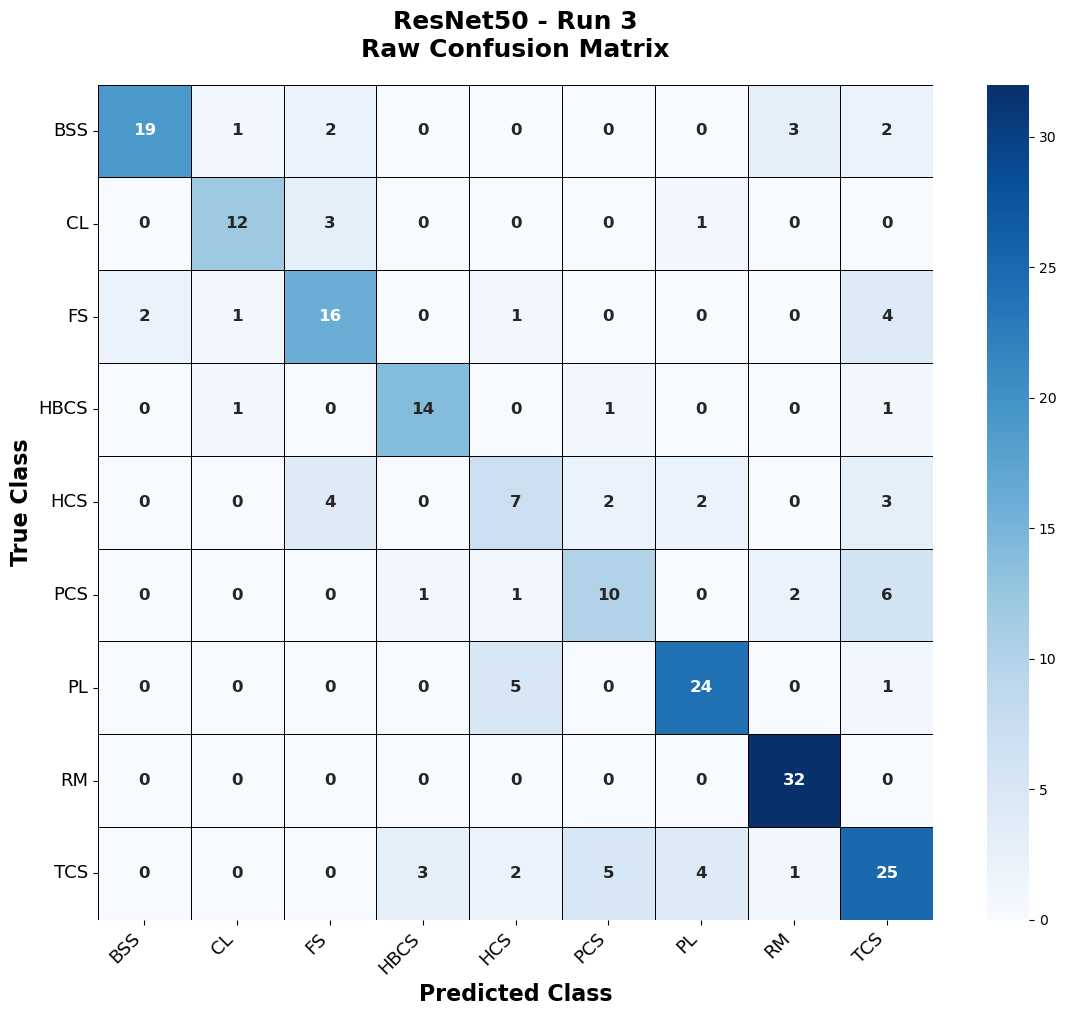

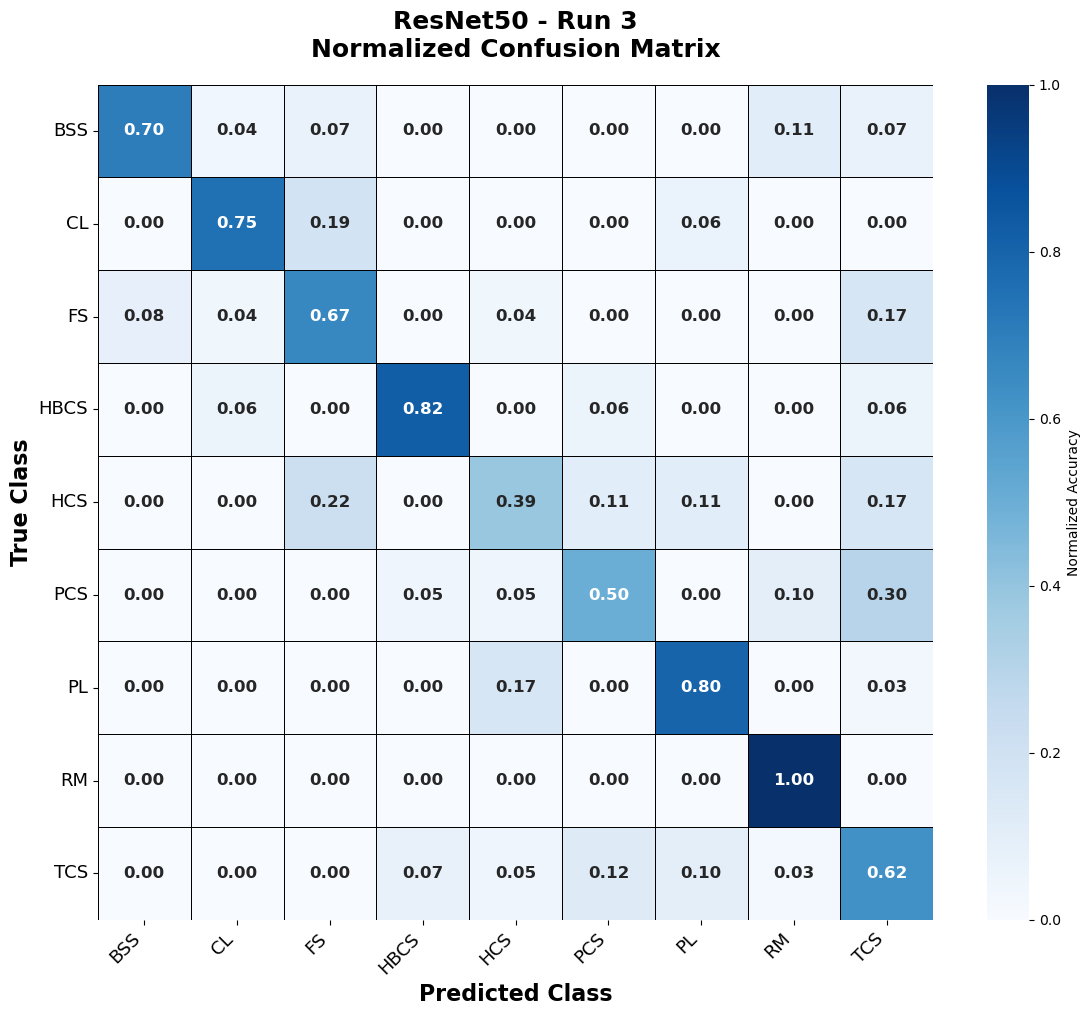


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run3_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run3_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run3_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run3_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Eva

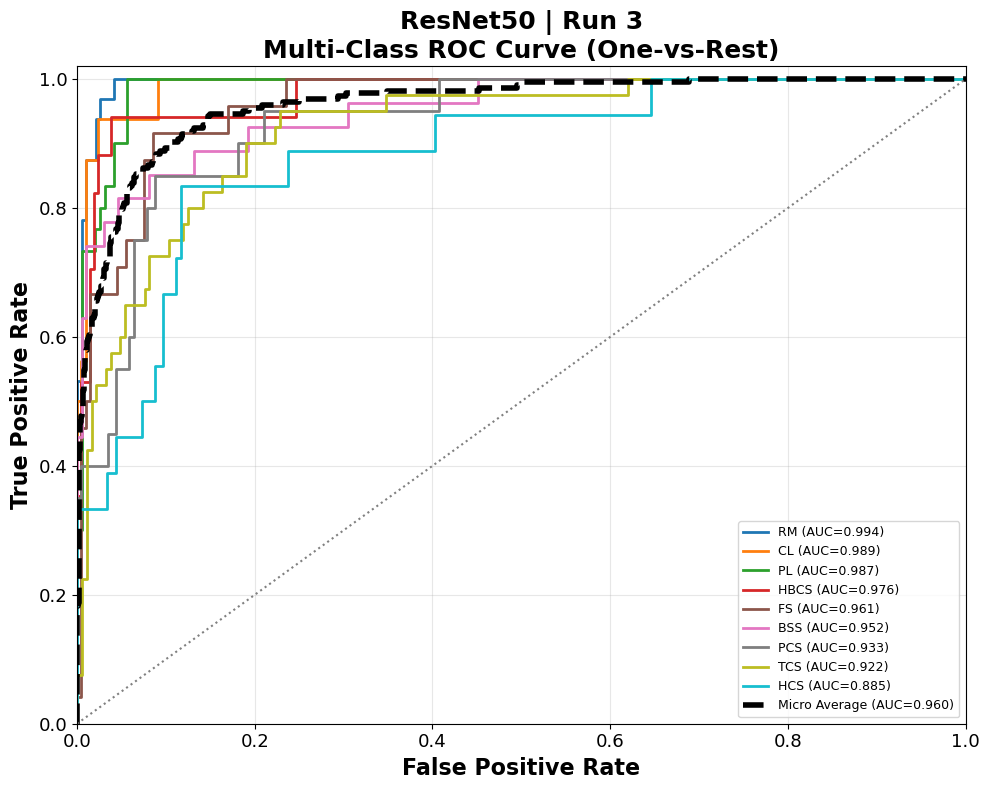


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.994303  Outstanding
1                 CL  0.989483    Excellent
2                 PL  0.986770    Excellent
3               HBCS  0.976130    Excellent
4                 FS  0.961042    Excellent
5                BSS  0.952059    Excellent
6                PCS  0.932843    Excellent
7                TCS  0.922283    Excellent
8                HCS  0.885383         Good
9      Micro Average  0.960071      Summary
10     Macro Average  0.955588      Summary
11  Weighted Average  0.955814      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 8/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9943

Worst Class                 : HCS (Good)
Worst AUC                   : 0.8854

Micro Aver


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 10.555 sec
Time / Image     : 0.047121 sec
Computing Metrics : ResNet50 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.7679
Precision (Macro)     : 0.7754
Recall (Macro)        : 0.7420
F1 Score (Macro)      : 0.7537
Precision (Weighted)  : 0.7712
Recall (Weighted)     : 0.7679
F1 Score (Weighted)   : 0.7652
Balanced Accuracy     : 0.7420
Cohen Kappa           : 0.7344
MCC                   : 0.7355
Log Loss              : 0.8043

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\ResNet50_Run4_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\ResNet

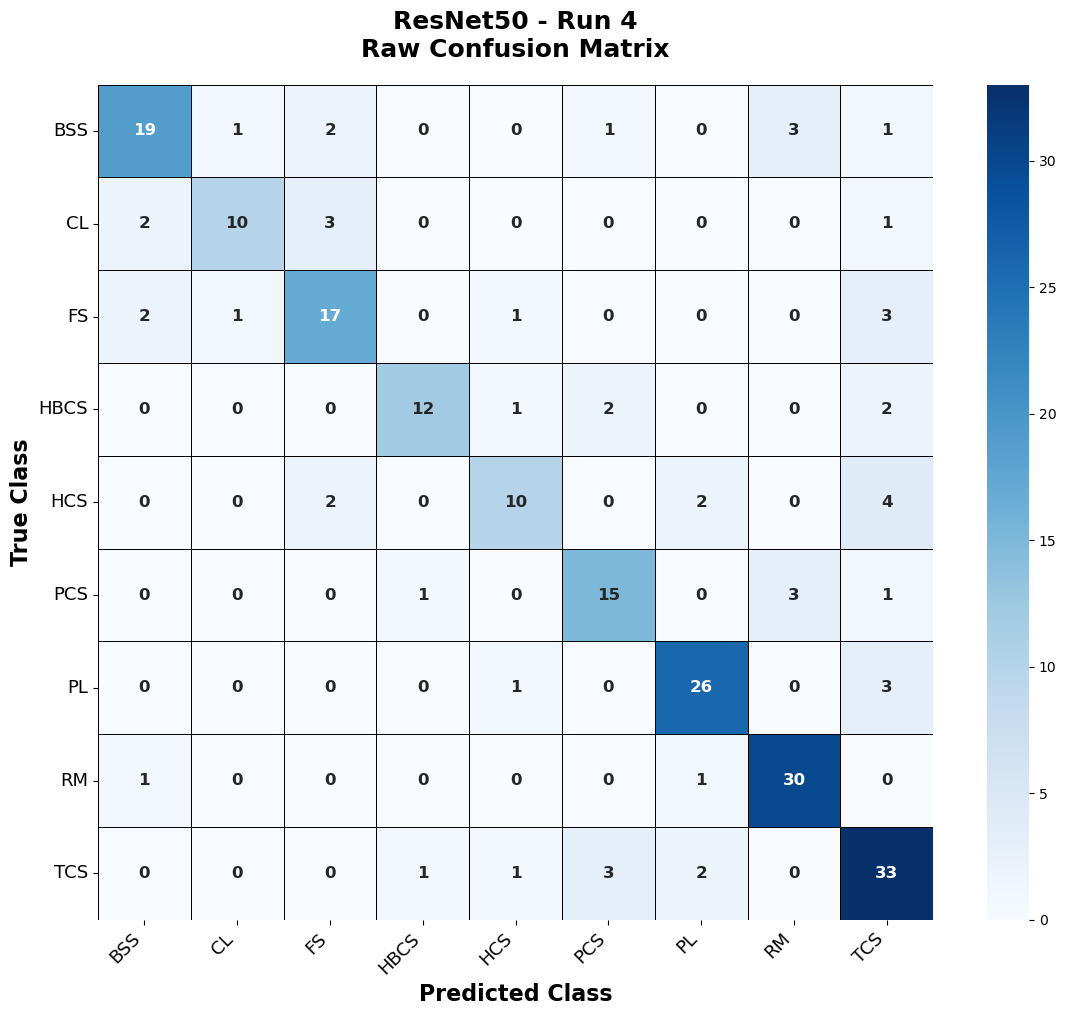

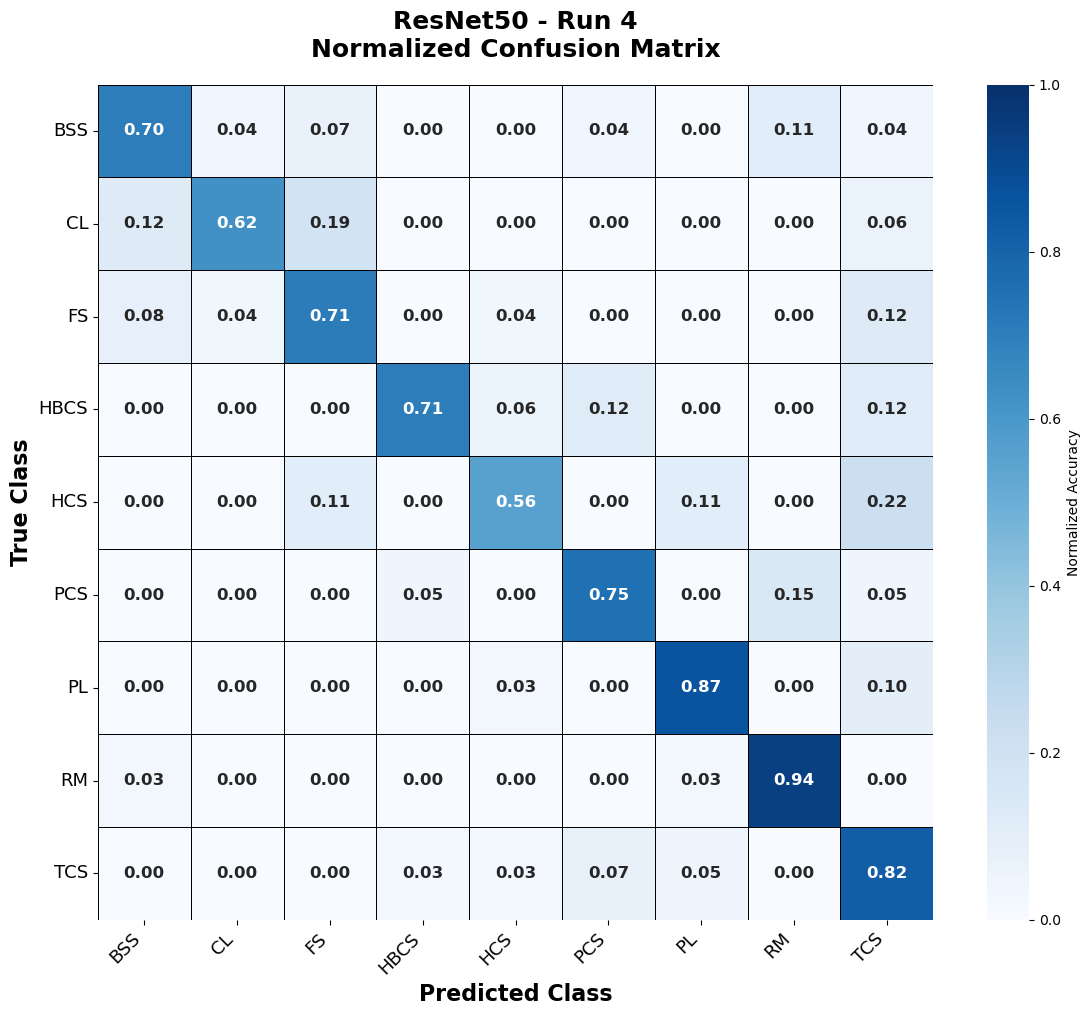


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run4_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run4_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run4_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run4_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Eva

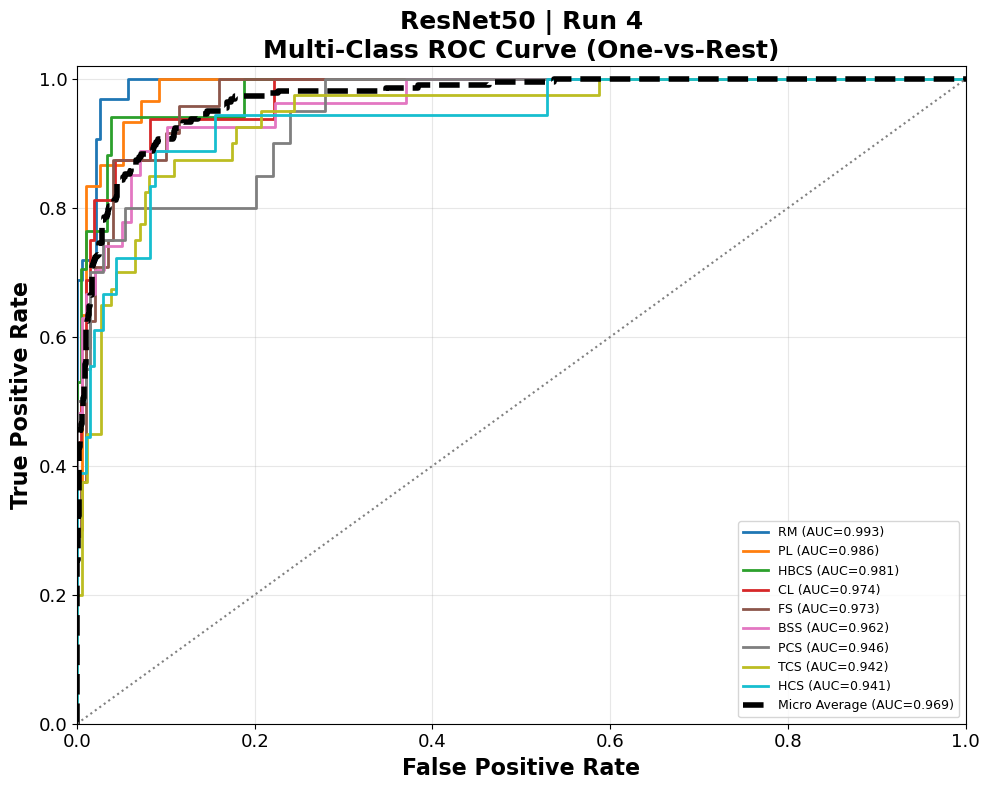


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.992513  Outstanding
1                 PL  0.986426    Excellent
2               HBCS  0.981245    Excellent
3                 CL  0.974159    Excellent
4                 FS  0.973125    Excellent
5                BSS  0.962211    Excellent
6                PCS  0.946078    Excellent
7                TCS  0.942391    Excellent
8                HCS  0.940669    Excellent
9      Micro Average  0.969111      Summary
10     Macro Average  0.966535      Summary
11  Weighted Average  0.966540      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9925

Worst Class                 : HCS (Excellent)
Worst AUC                   : 0.9407

Micro


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 9.643 sec
Time / Image     : 0.043049 sec
Computing Metrics : ResNet50 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.7723
Precision (Macro)     : 0.7731
Recall (Macro)        : 0.7597
F1 Score (Macro)      : 0.7626
Precision (Weighted)  : 0.7702
Recall (Weighted)     : 0.7723
F1 Score (Weighted)   : 0.7682
Balanced Accuracy     : 0.7597
Cohen Kappa           : 0.7403
MCC                   : 0.7408
Log Loss              : 0.8158

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\ResNet50_Run5_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\ResNet5

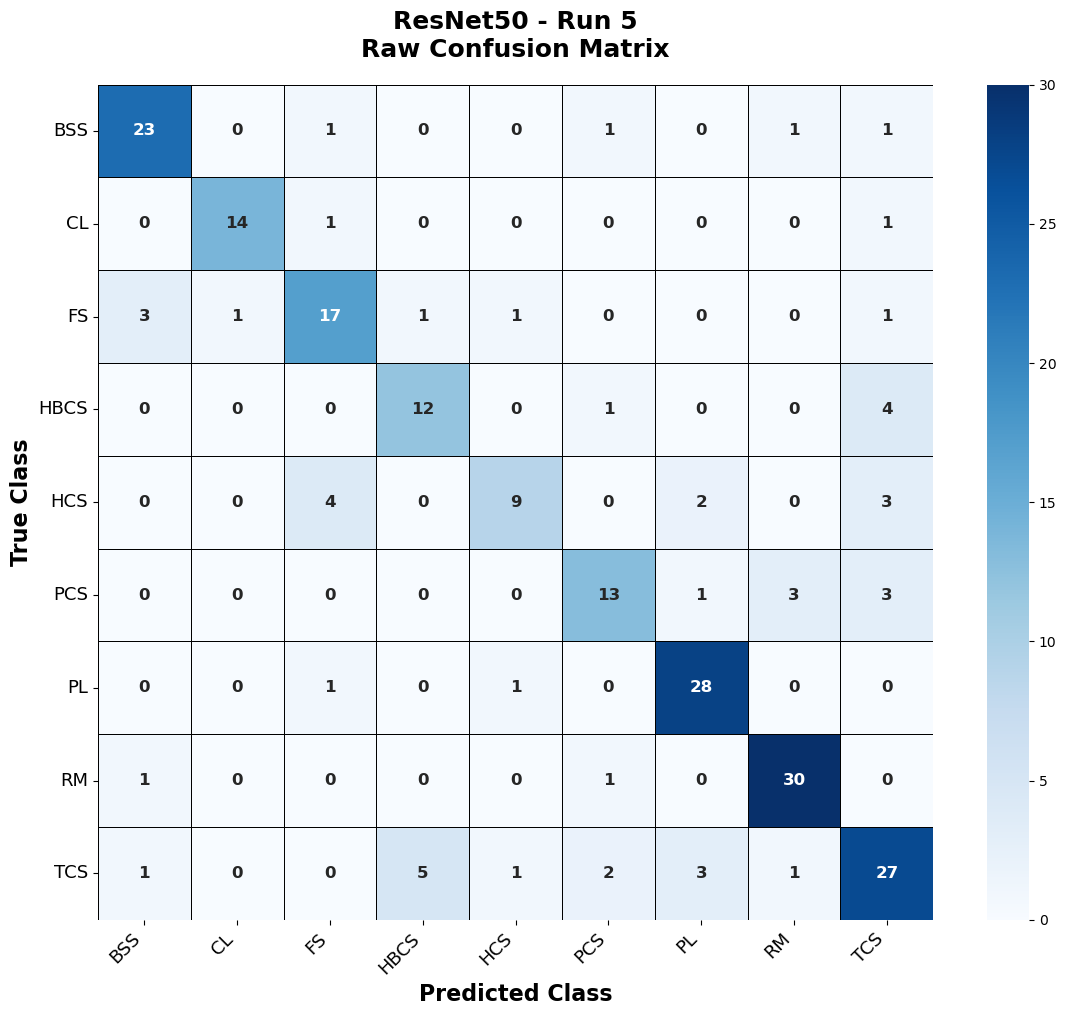

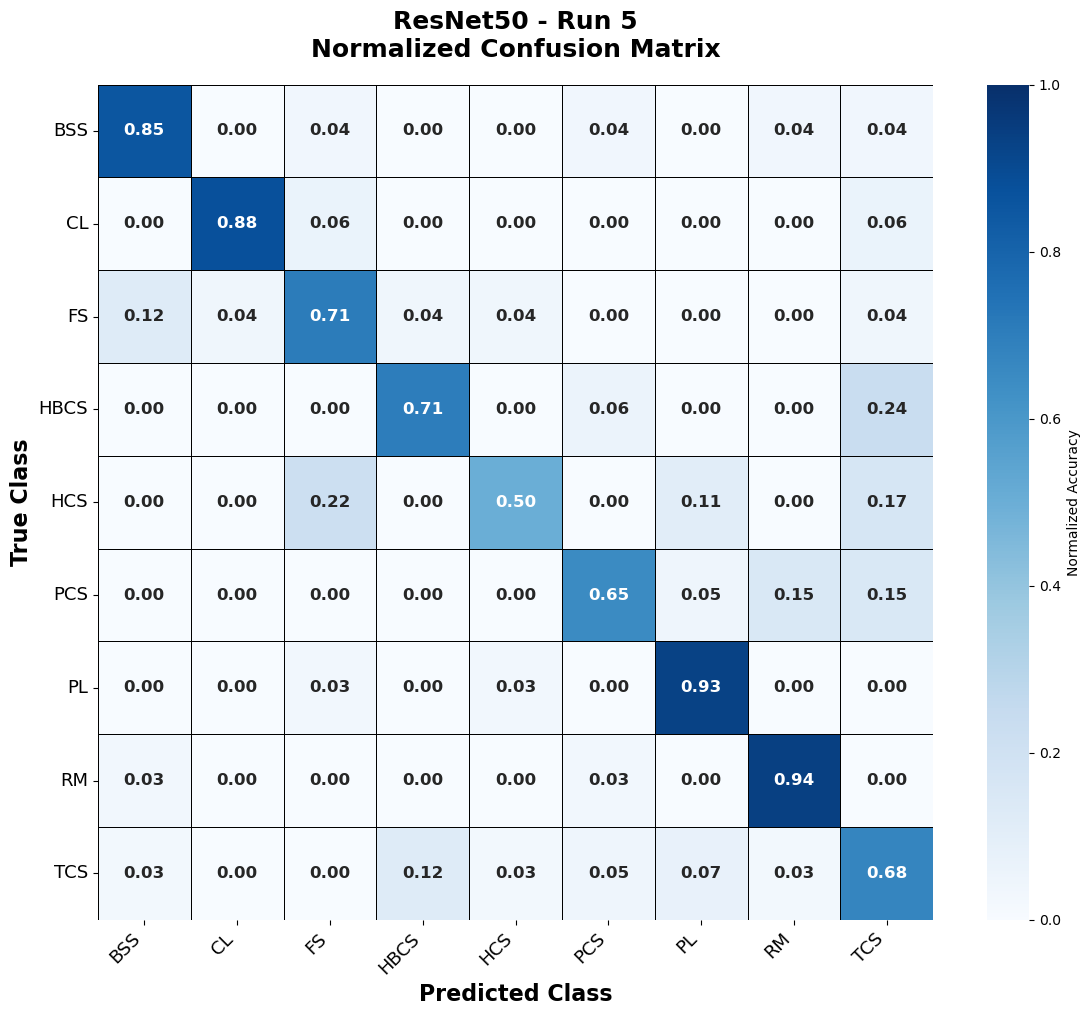


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run5_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run5_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run5_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\ResNet50_Run5_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Eva

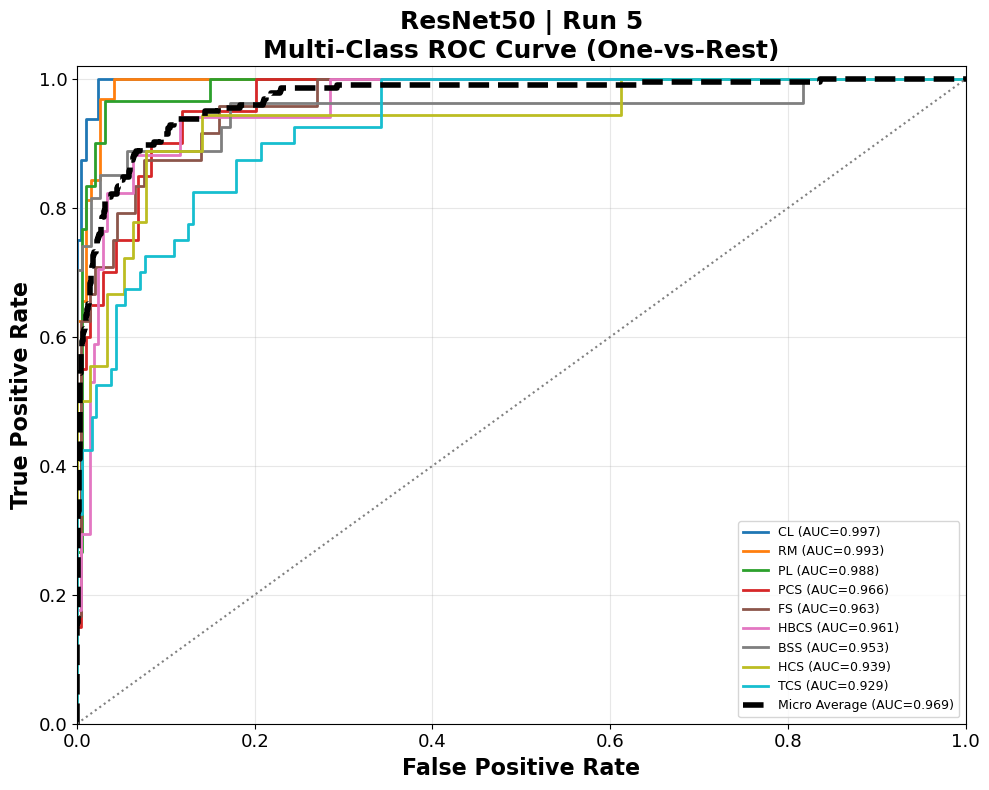


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 CL  0.997296  Outstanding
1                 RM  0.993164  Outstanding
2                 PL  0.988316    Excellent
3                PCS  0.966176    Excellent
4                 FS  0.963125    Excellent
5               HBCS  0.961068    Excellent
6                BSS  0.952999    Excellent
7                HCS  0.938511    Excellent
8                TCS  0.928940    Excellent
9      Micro Average  0.968984      Summary
10     Macro Average  0.965511      Summary
11  Weighted Average  0.964044      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : CL (Outstanding)
Best AUC                    : 0.9973

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9289

Micro


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 10.545 sec
Time / Image     : 0.047077 sec
Computing Metrics : DenseNet121 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.8080
Precision (Macro)     : 0.8194
Recall (Macro)        : 0.7841
F1 Score (Macro)      : 0.7928
Precision (Weighted)  : 0.8132
Recall (Weighted)     : 0.8080
F1 Score (Weighted)   : 0.8036
Balanced Accuracy     : 0.7841
Cohen Kappa           : 0.7803
MCC                   : 0.7819
Log Loss              : 0.7734

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\DenseNet121_Run1_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\

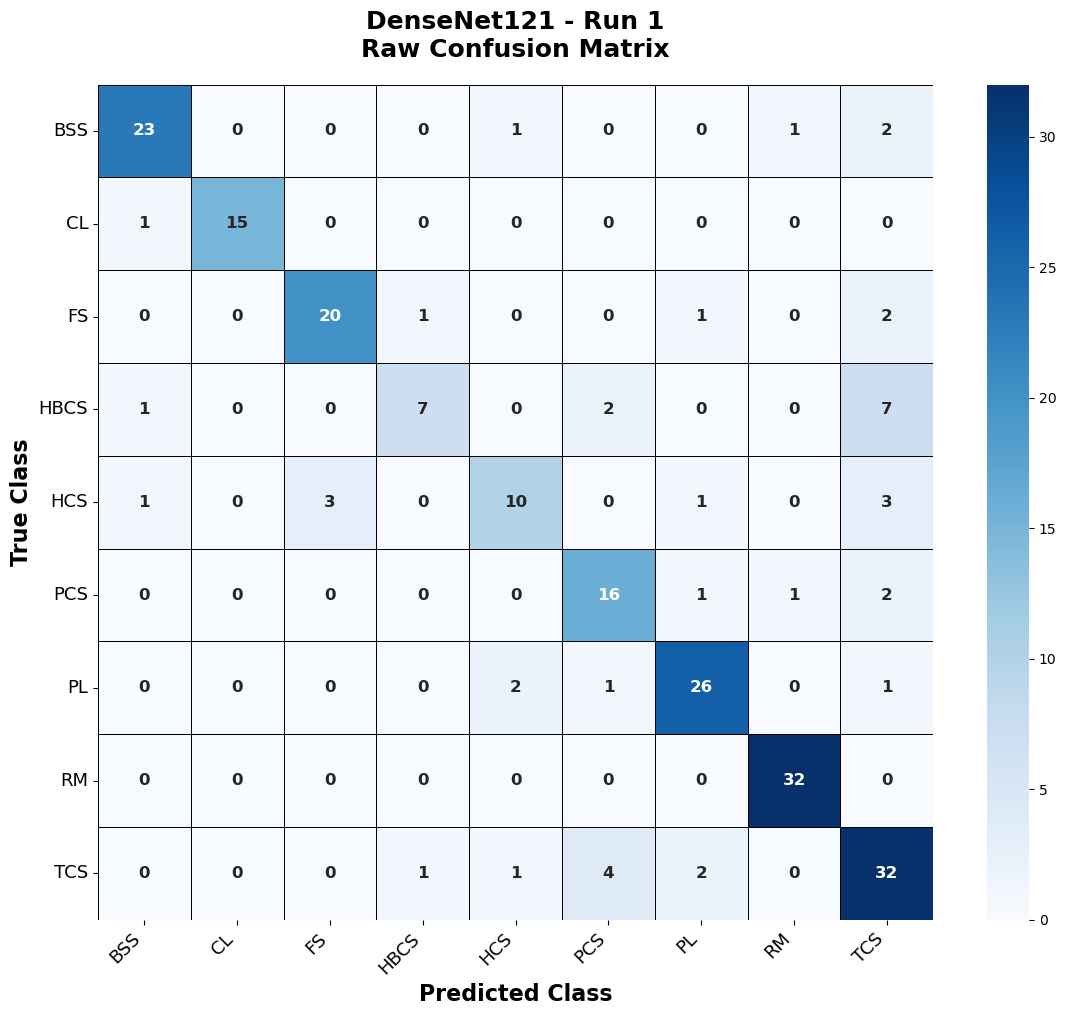

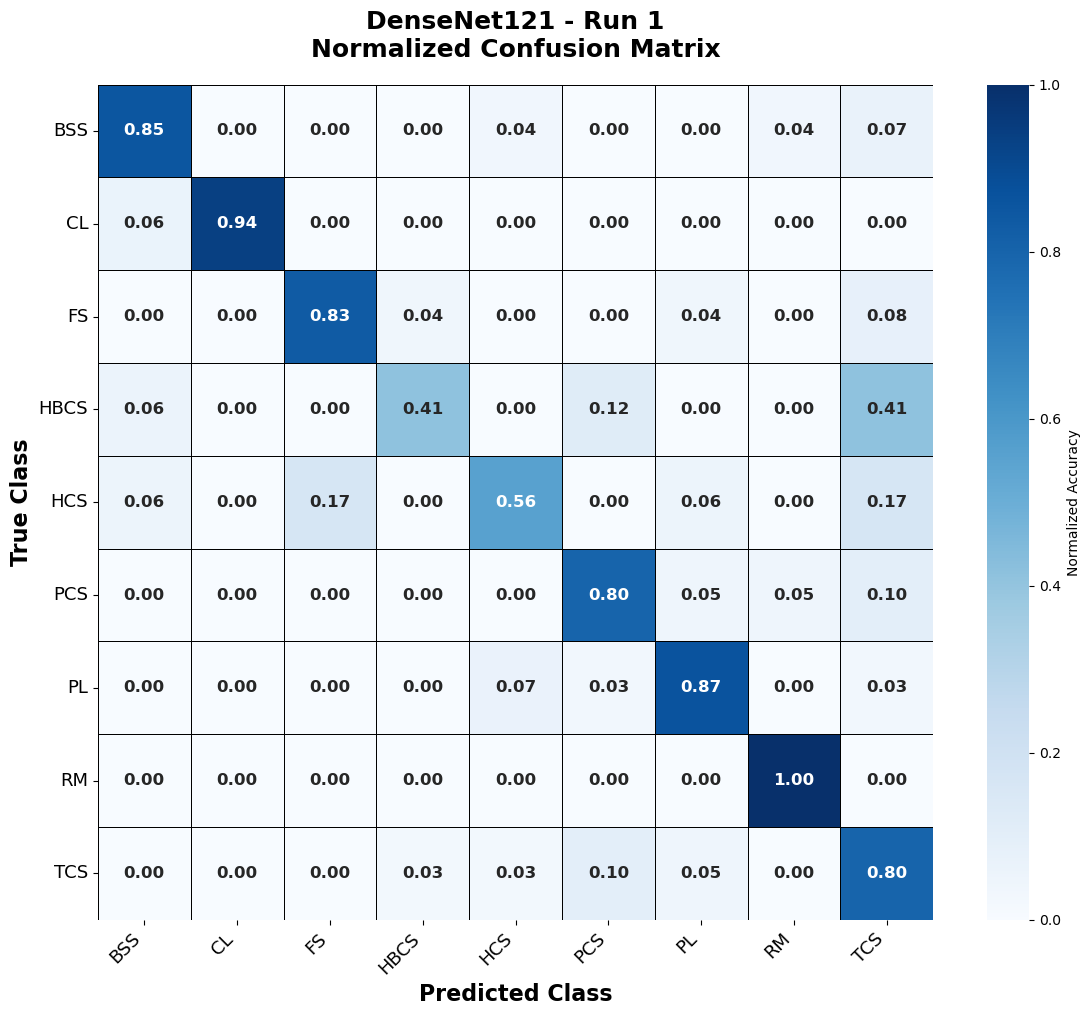


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run1_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run1_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run1_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run1_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN

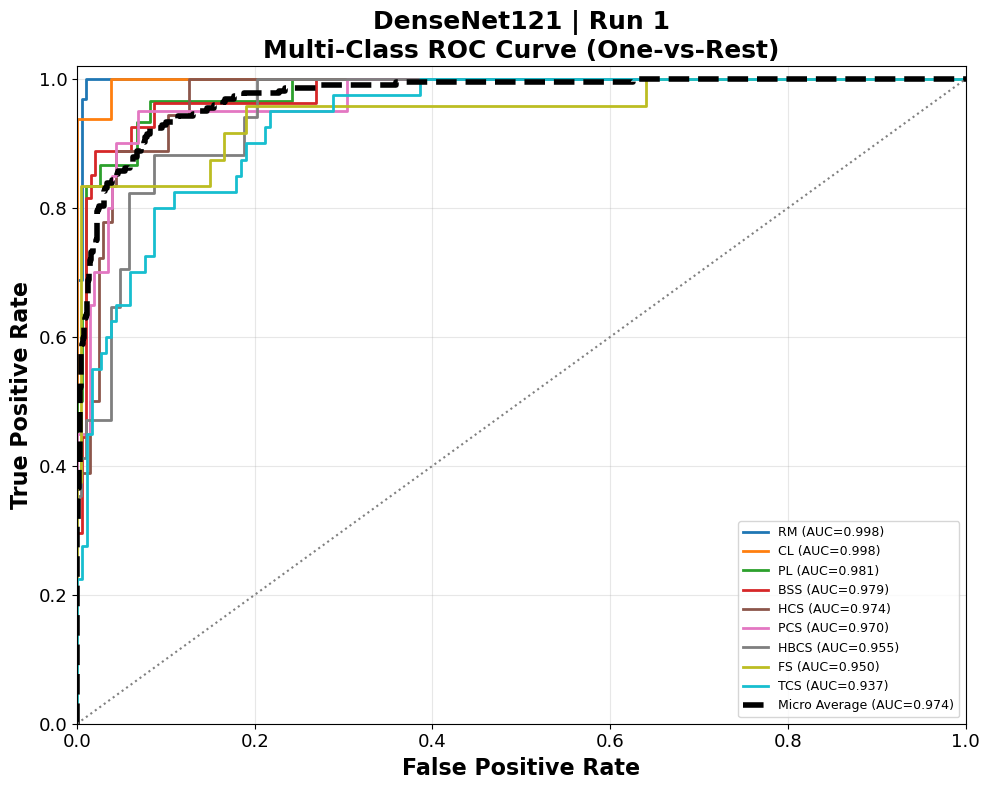


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.998210  Outstanding
1                 CL  0.997596  Outstanding
2                 PL  0.981100    Excellent
3                BSS  0.978755    Excellent
4                HCS  0.974110    Excellent
5                PCS  0.969853    Excellent
6               HBCS  0.954533    Excellent
7                 FS  0.950000    Excellent
8                TCS  0.937092    Excellent
9      Micro Average  0.974091      Summary
10     Macro Average  0.971250      Summary
11  Weighted Average  0.969667      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9982

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9371

Micro


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 10.311 sec
Time / Image     : 0.046032 sec
Computing Metrics : DenseNet121 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.7500
Precision (Macro)     : 0.7569
Recall (Macro)        : 0.7325
F1 Score (Macro)      : 0.7400
Precision (Weighted)  : 0.7519
Recall (Weighted)     : 0.7500
F1 Score (Weighted)   : 0.7473
Balanced Accuracy     : 0.7325
Cohen Kappa           : 0.7146
MCC                   : 0.7153
Log Loss              : 0.8288

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\DenseNet121_Run2_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\

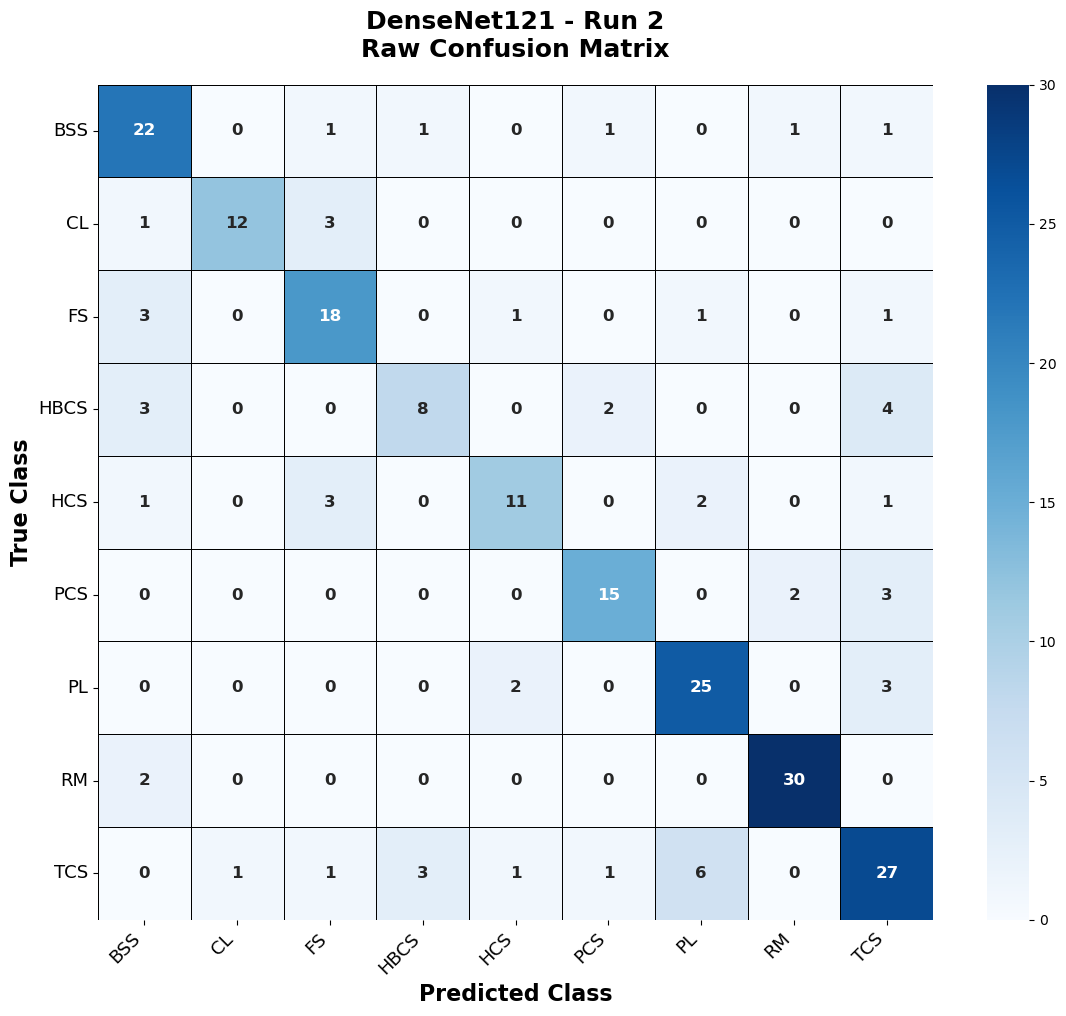

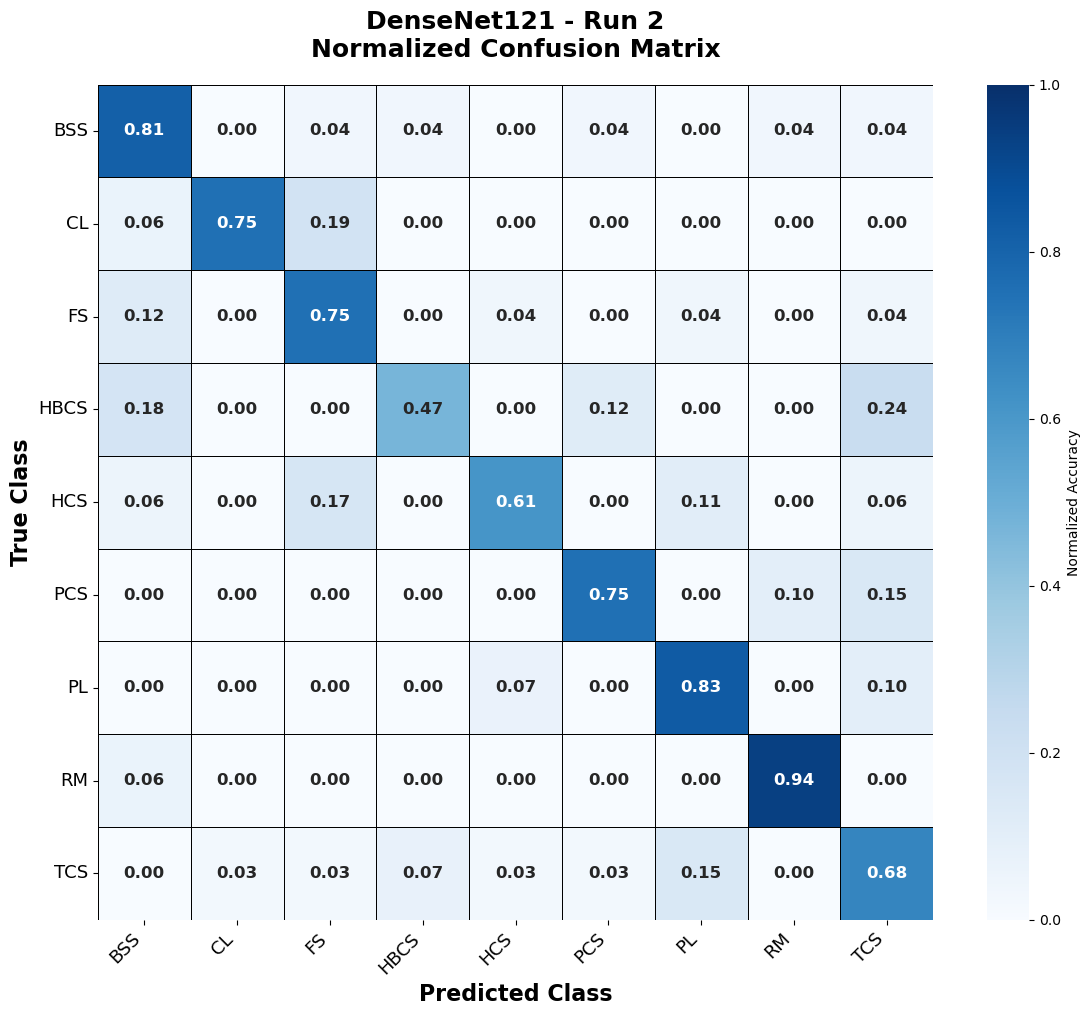


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run2_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run2_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run2_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run2_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN

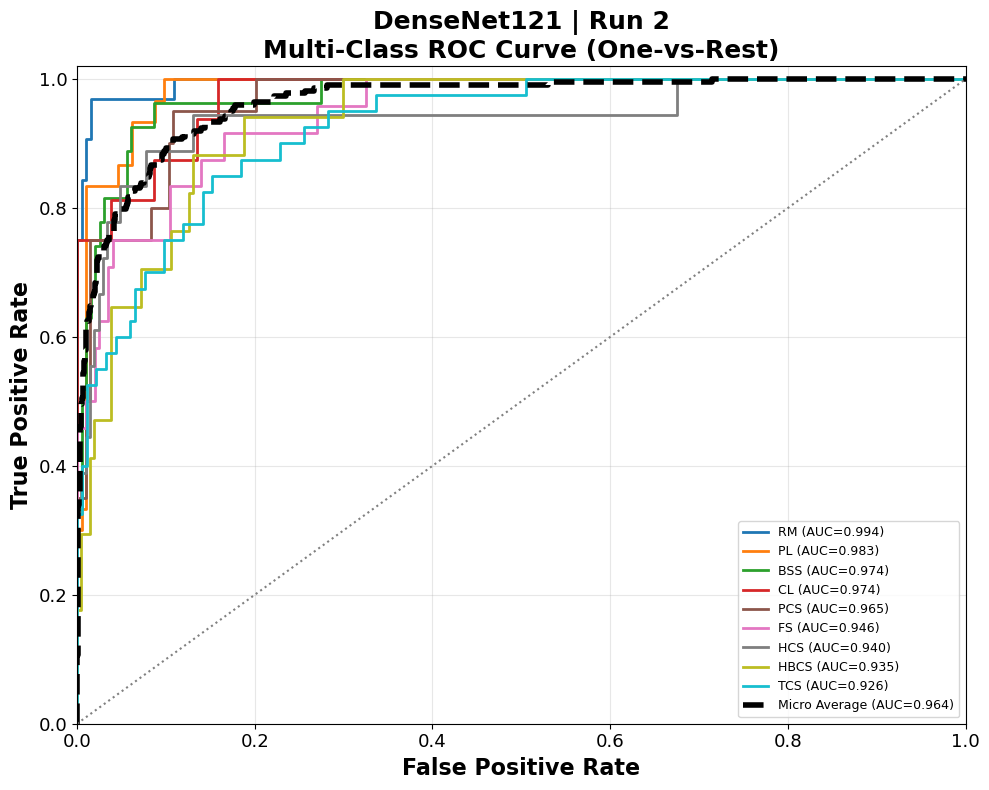


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.994466  Outstanding
1                 PL  0.982818    Excellent
2                BSS  0.974055    Excellent
3                 CL  0.973858    Excellent
4                PCS  0.964951    Excellent
5                 FS  0.946042    Excellent
6                HCS  0.939860    Excellent
7               HBCS  0.935493    Excellent
8                TCS  0.925543    Excellent
9      Micro Average  0.963513      Summary
10     Macro Average  0.959676      Summary
11  Weighted Average  0.959979      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9945

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9255

Micro


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 10.392 sec
Time / Image     : 0.046391 sec
Computing Metrics : DenseNet121 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.7991
Precision (Macro)     : 0.7969
Recall (Macro)        : 0.7850
F1 Score (Macro)      : 0.7885
Precision (Weighted)  : 0.7978
Recall (Weighted)     : 0.7991
F1 Score (Weighted)   : 0.7965
Balanced Accuracy     : 0.7850
Cohen Kappa           : 0.7710
MCC                   : 0.7715
Log Loss              : 0.7030

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\DenseNet121_Run3_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\

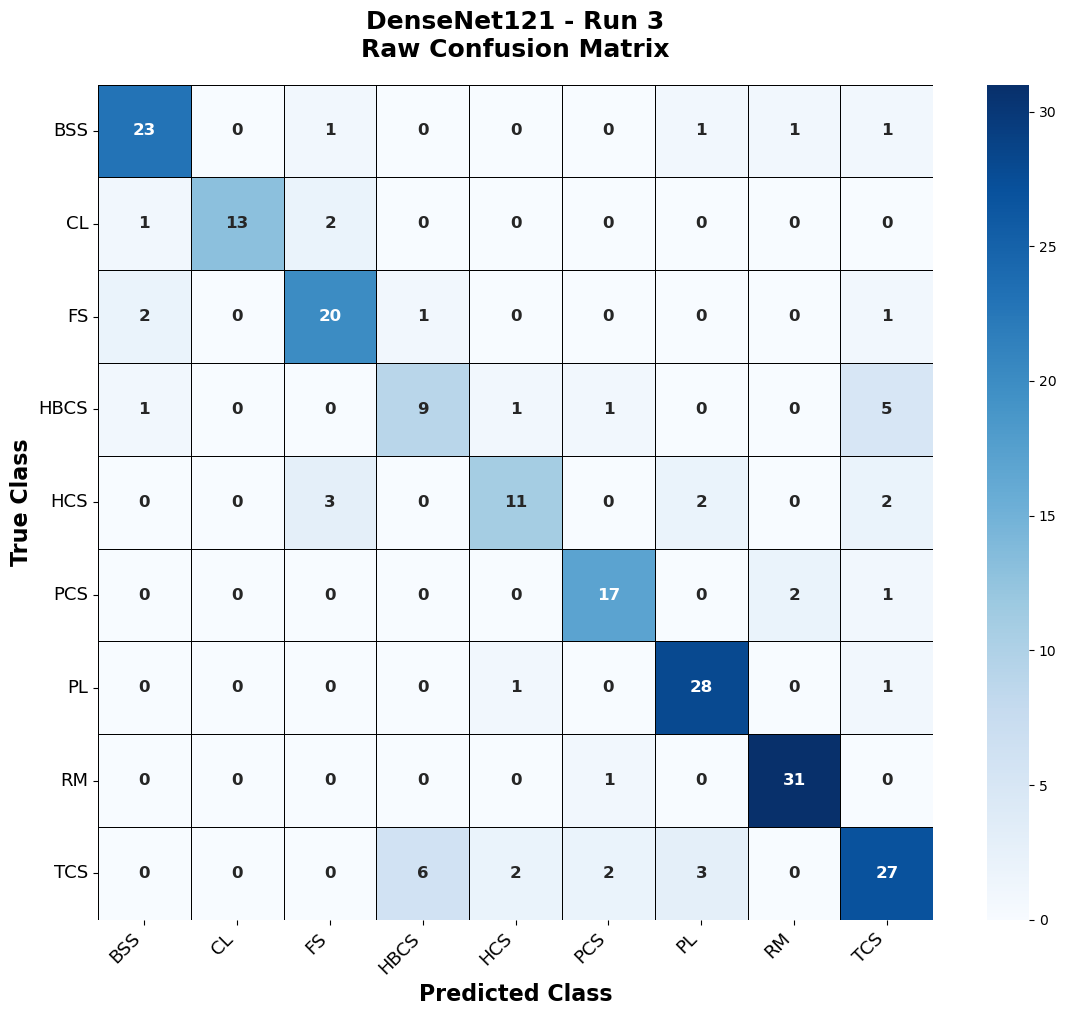

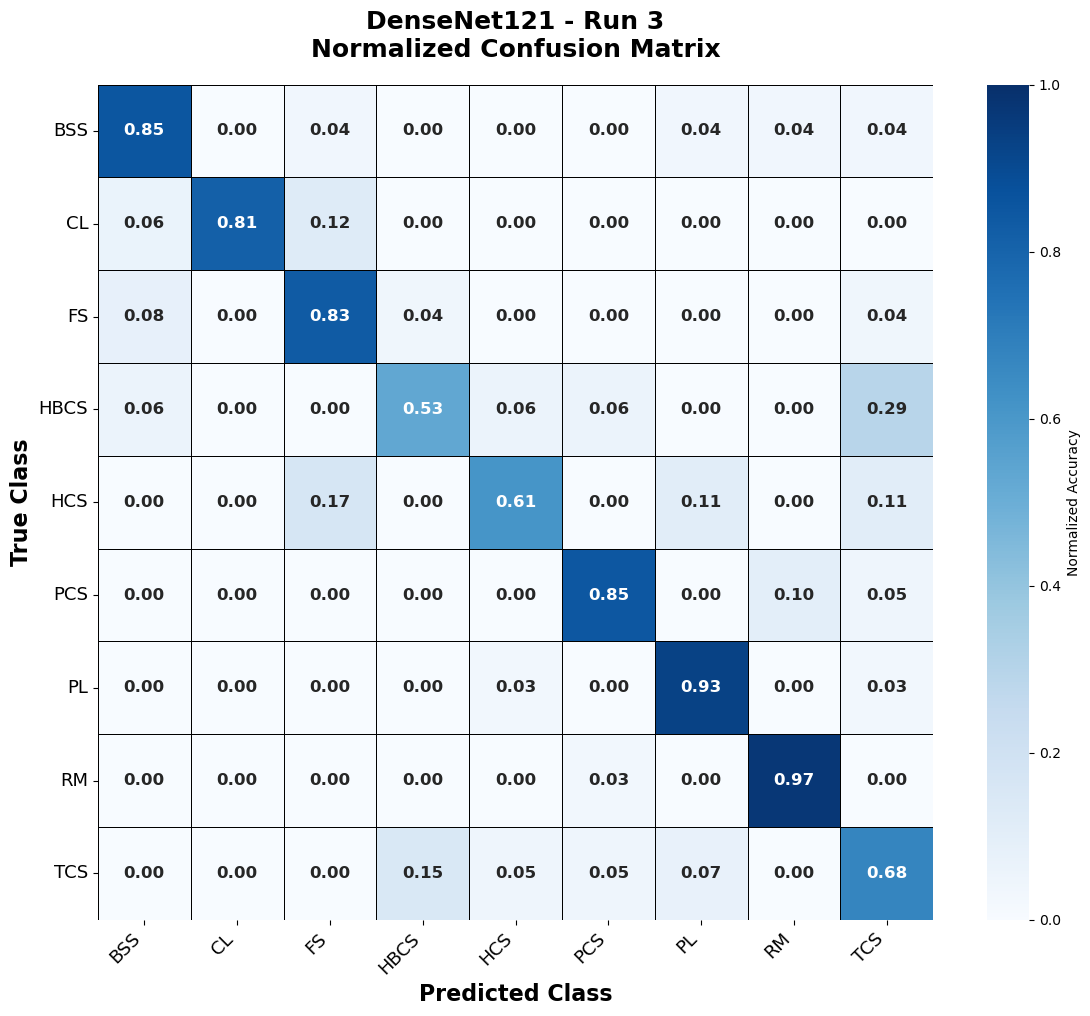


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run3_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run3_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run3_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run3_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN

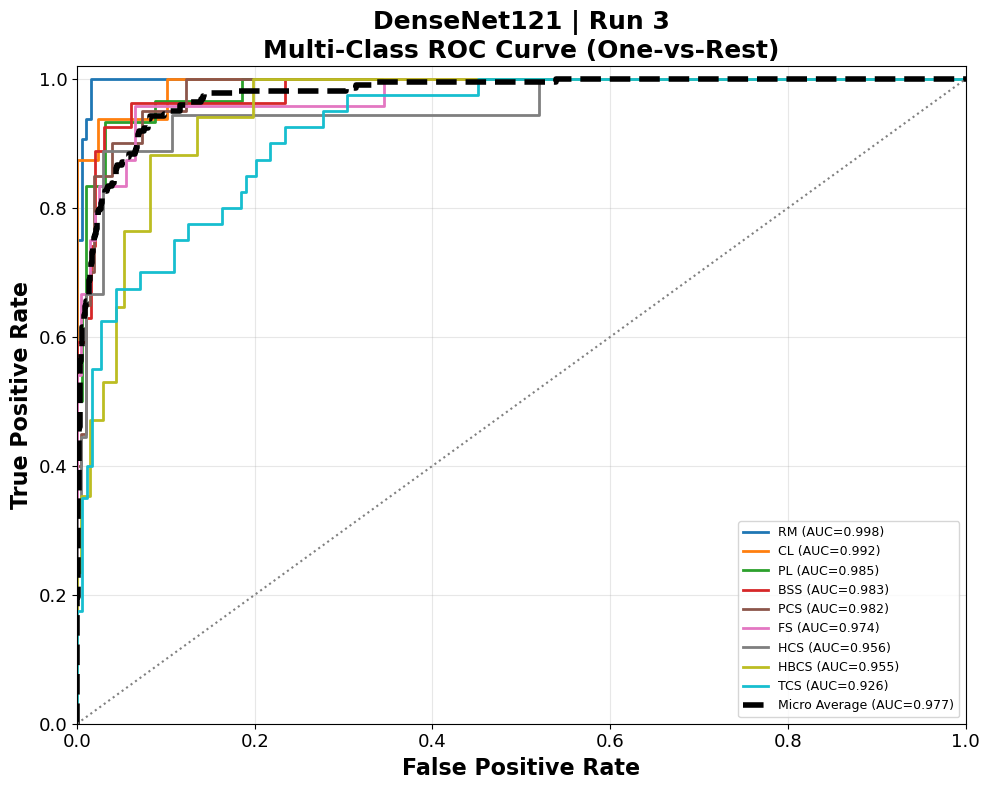


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.997884  Outstanding
1                 CL  0.992188  Outstanding
2                 PL  0.985052    Excellent
3                BSS  0.982892    Excellent
4                PCS  0.982353    Excellent
5                 FS  0.974167    Excellent
6                HCS  0.956041    Excellent
7               HBCS  0.955385    Excellent
8                TCS  0.925951    Excellent
9      Micro Average  0.976774      Summary
10     Macro Average  0.972435      Summary
11  Weighted Average  0.970591      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9979

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9260

Micro


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 11.330 sec
Time / Image     : 0.050581 sec
Computing Metrics : DenseNet121 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.7589
Precision (Macro)     : 0.8197
Recall (Macro)        : 0.7201
F1 Score (Macro)      : 0.7378
Precision (Weighted)  : 0.7922
Recall (Weighted)     : 0.7589
F1 Score (Weighted)   : 0.7515
Balanced Accuracy     : 0.7201
Cohen Kappa           : 0.7228
MCC                   : 0.7267
Log Loss              : 0.8994

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\DenseNet121_Run4_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\

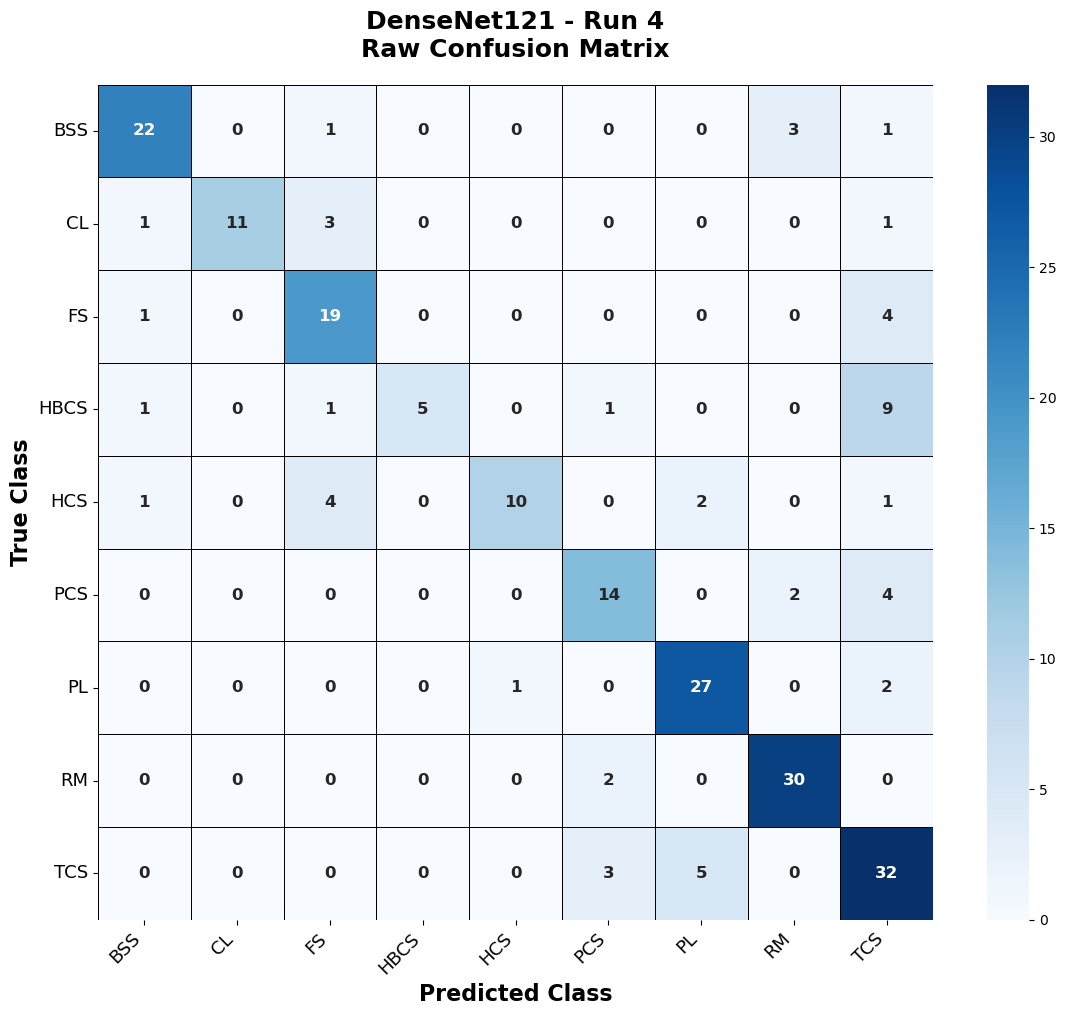

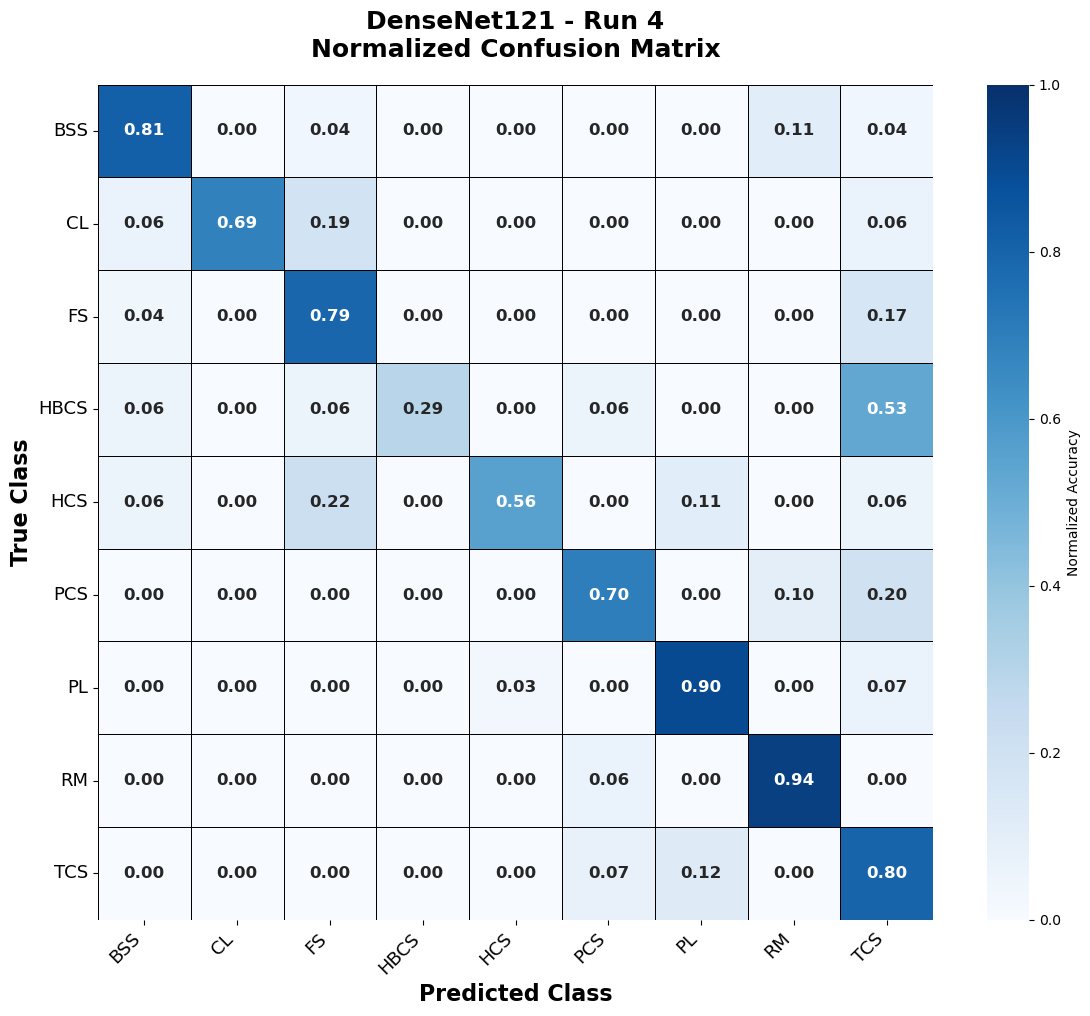


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run4_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run4_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run4_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run4_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN

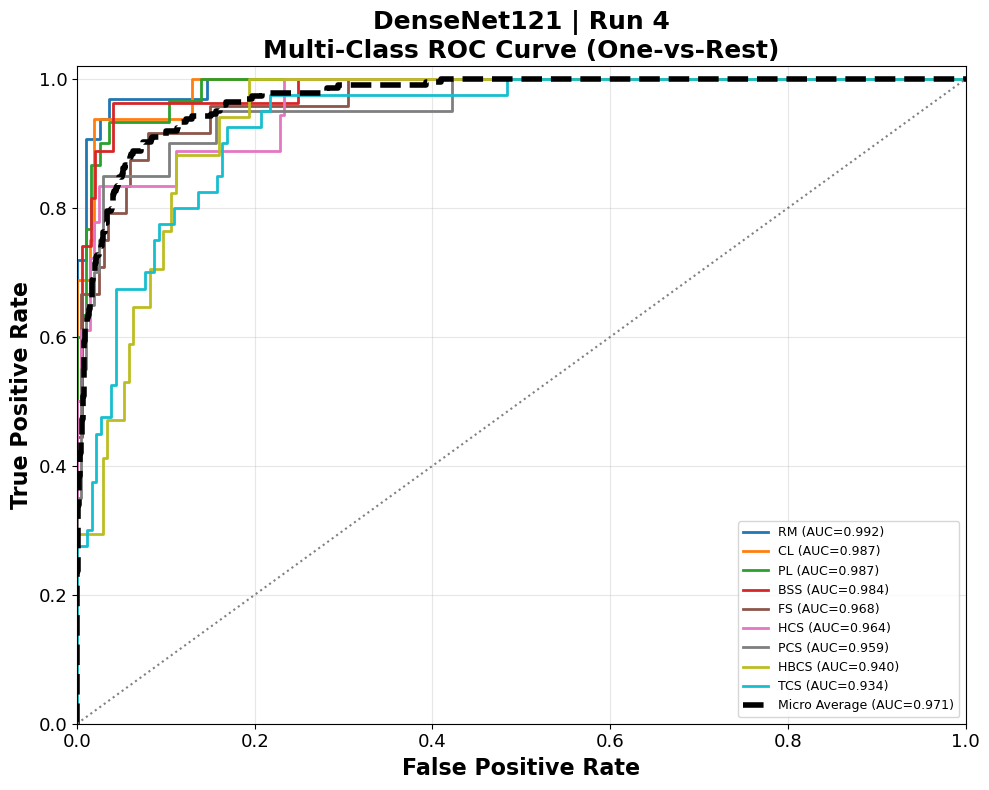


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.991536  Outstanding
1                 CL  0.987380    Excellent
2                 PL  0.986770    Excellent
3                BSS  0.983644    Excellent
4                 FS  0.968333    Excellent
5                HCS  0.963592    Excellent
6                PCS  0.958824    Excellent
7               HBCS  0.940324    Excellent
8                TCS  0.934103    Excellent
9      Micro Average  0.970967      Summary
10     Macro Average  0.968278      Summary
11  Weighted Average  0.967855      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9915

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9341

Micro


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 11.156 sec
Time / Image     : 0.049805 sec
Computing Metrics : DenseNet121 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.7411
Precision (Macro)     : 0.7362
Recall (Macro)        : 0.7258
F1 Score (Macro)      : 0.7276
Precision (Weighted)  : 0.7415
Recall (Weighted)     : 0.7411
F1 Score (Weighted)   : 0.7386
Balanced Accuracy     : 0.7258
Cohen Kappa           : 0.7048
MCC                   : 0.7053
Log Loss              : 0.7467

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\DenseNet121_Run5_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\

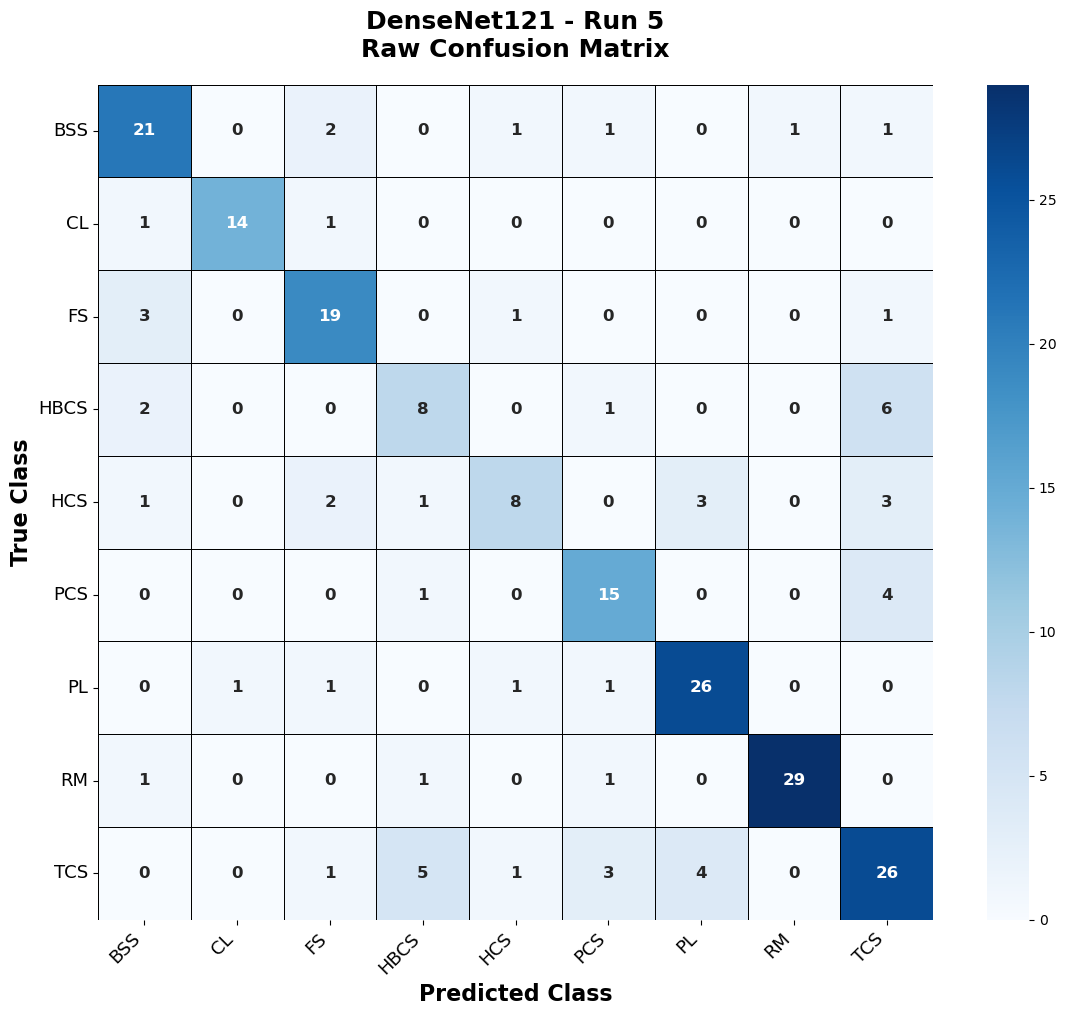

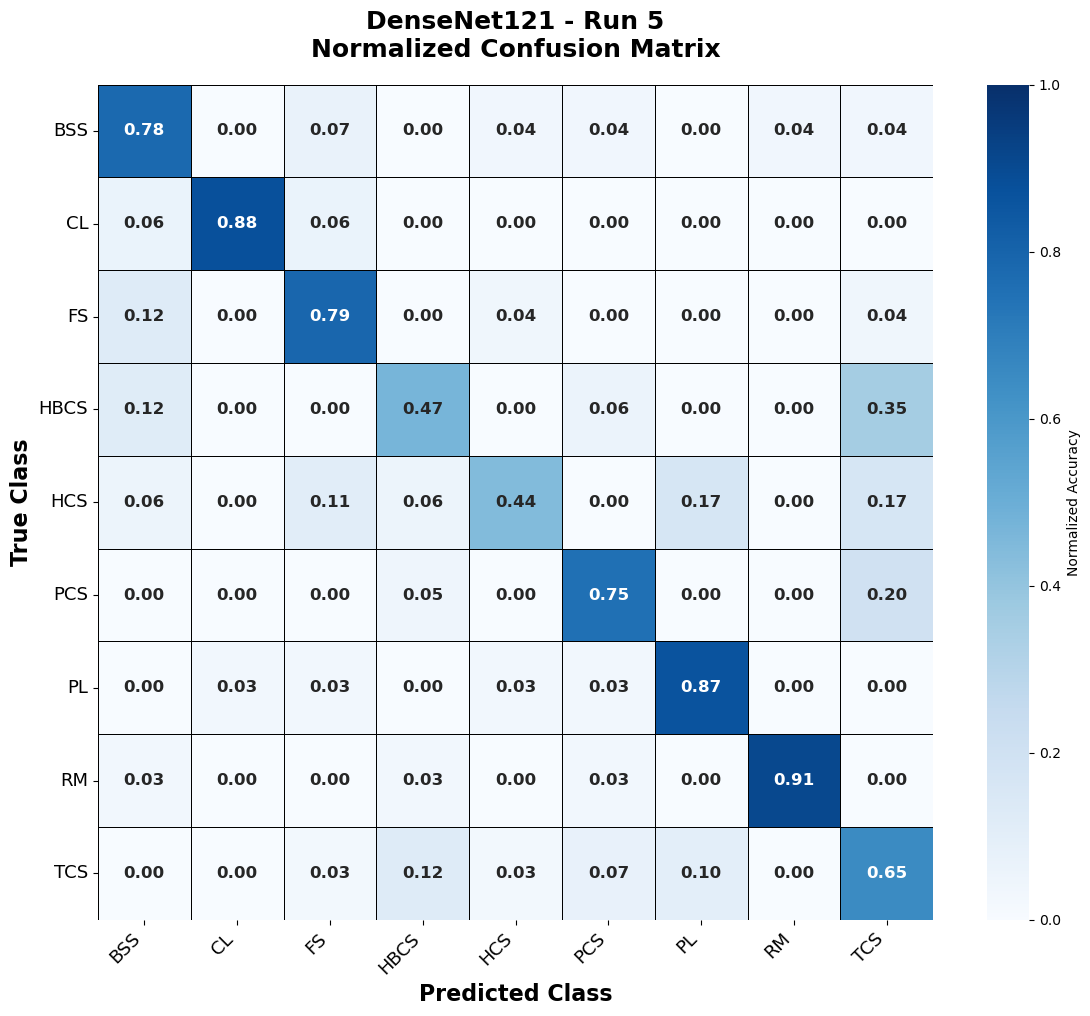


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run5_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run5_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run5_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\DenseNet121_Run5_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN

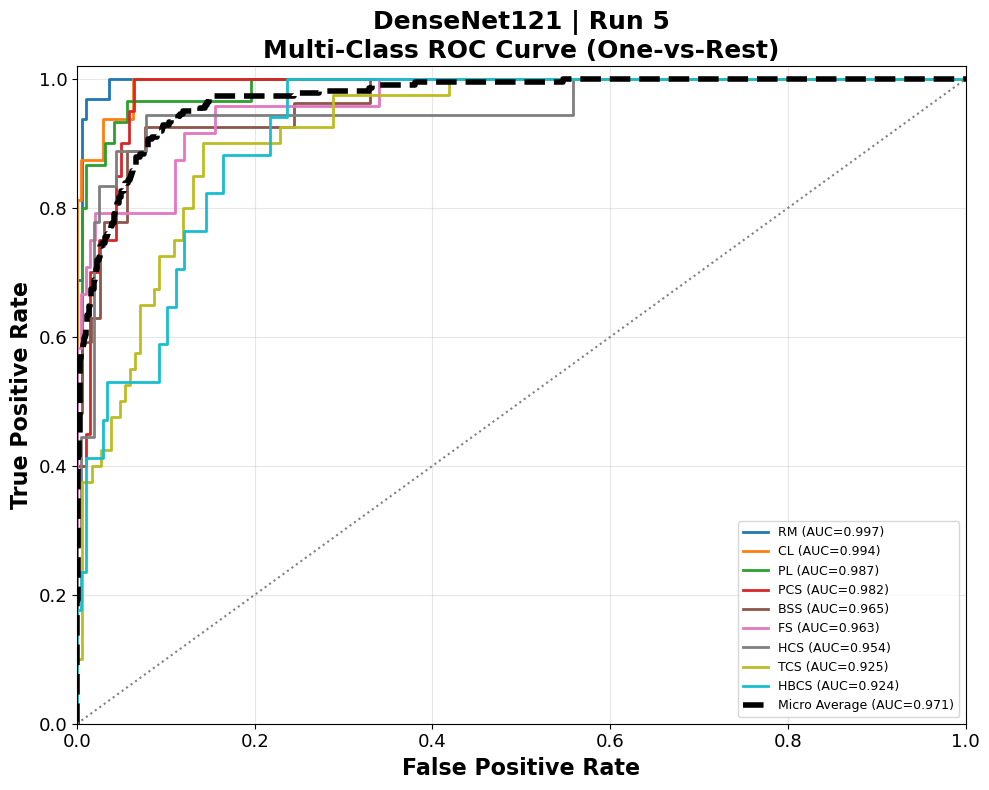


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.997233  Outstanding
1                 CL  0.993990  Outstanding
2                 PL  0.986942    Excellent
3                PCS  0.981618    Excellent
4                BSS  0.964655    Excellent
5                 FS  0.962917    Excellent
6                HCS  0.953614    Excellent
7                TCS  0.924864    Excellent
8               HBCS  0.924410    Excellent
9      Micro Average  0.970760      Summary
10     Macro Average  0.965583      Summary
11  Weighted Average  0.964670      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9972

Worst Class                 : HBCS (Excellent)
Worst AUC                   : 0.9244

Micr


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 3.422 sec
Time / Image     : 0.015276 sec
Computing Metrics : MobileNetV3 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.7098
Precision (Macro)     : 0.7191
Recall (Macro)        : 0.7056
F1 Score (Macro)      : 0.7036
Precision (Weighted)  : 0.7225
Recall (Weighted)     : 0.7098
F1 Score (Weighted)   : 0.7087
Balanced Accuracy     : 0.7056
Cohen Kappa           : 0.6702
MCC                   : 0.6722
Log Loss              : 0.9046

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\MobileNetV3_Run1_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\M

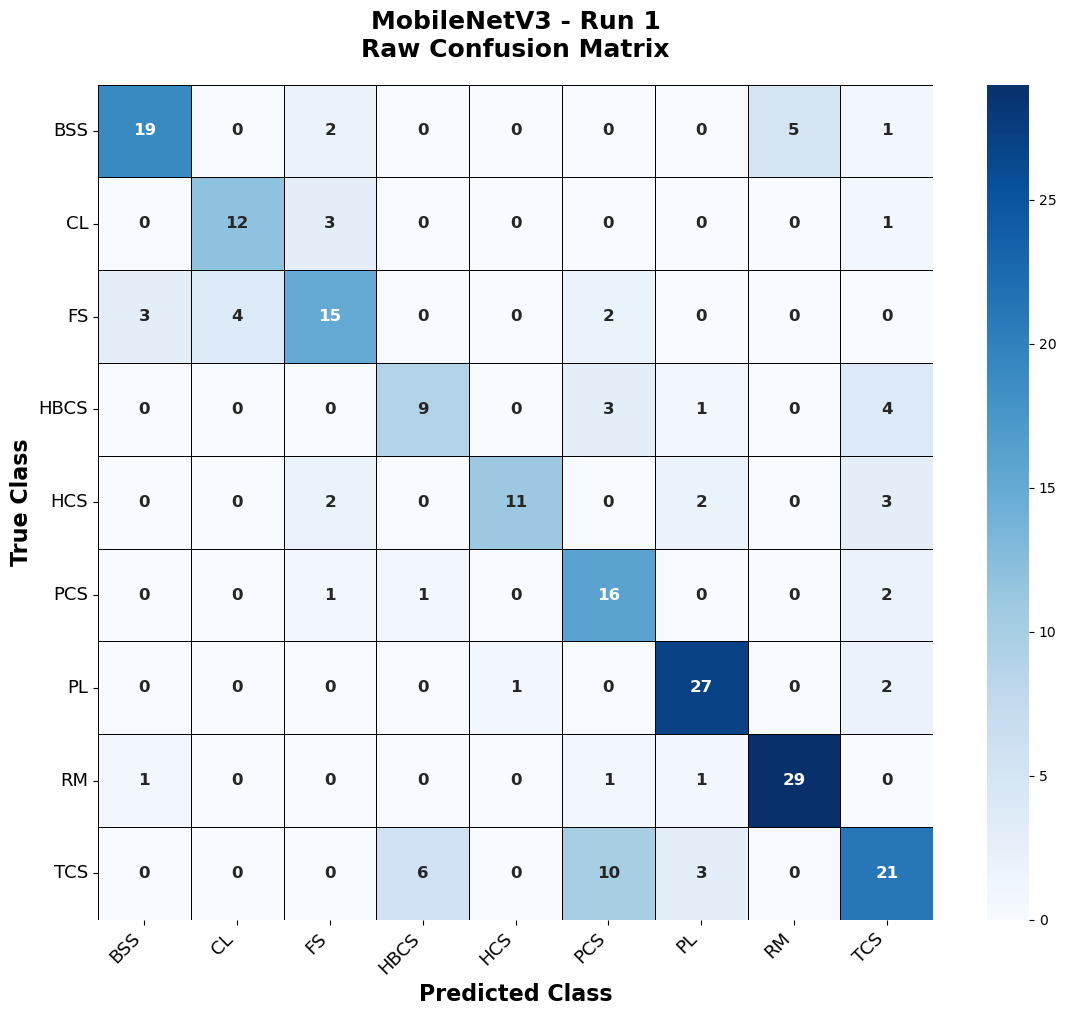

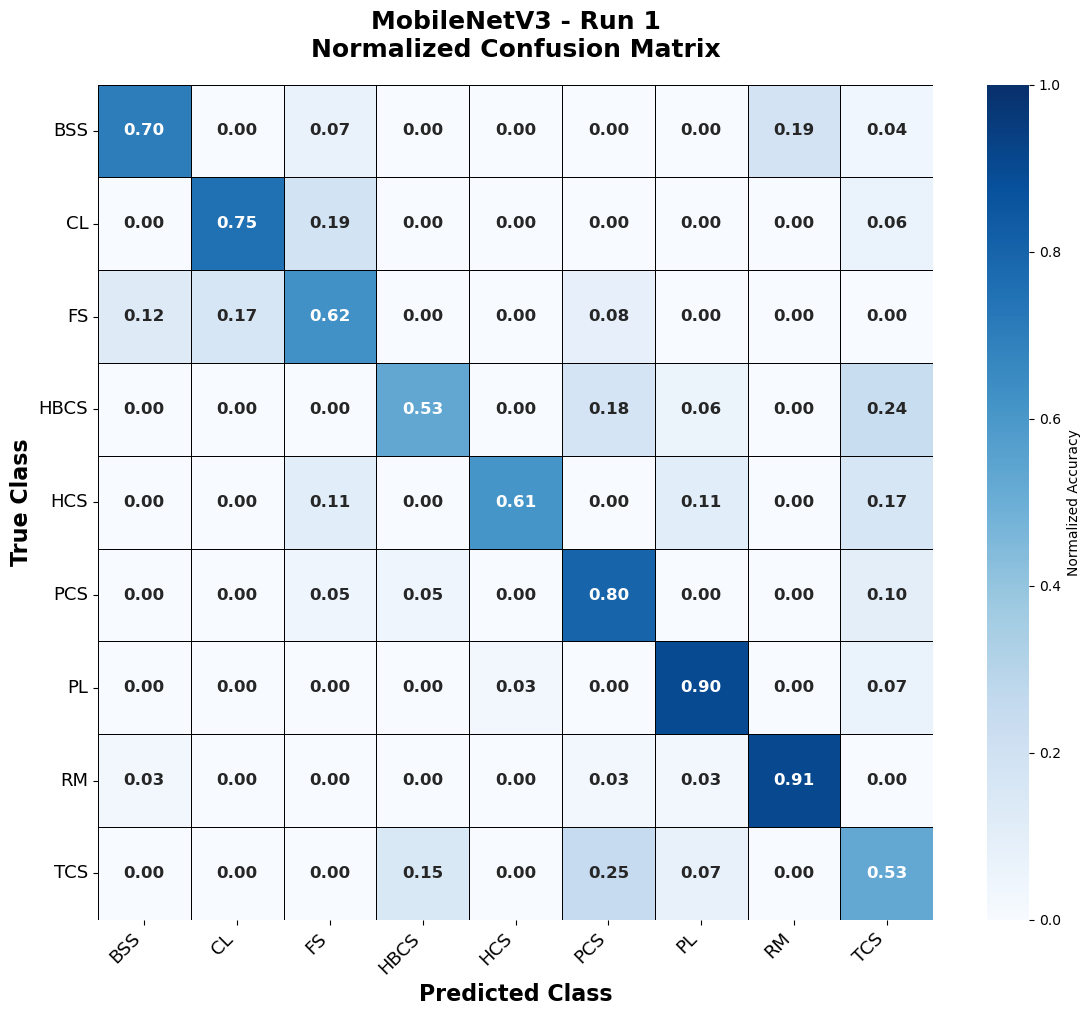


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run1_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run1_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run1_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run1_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN

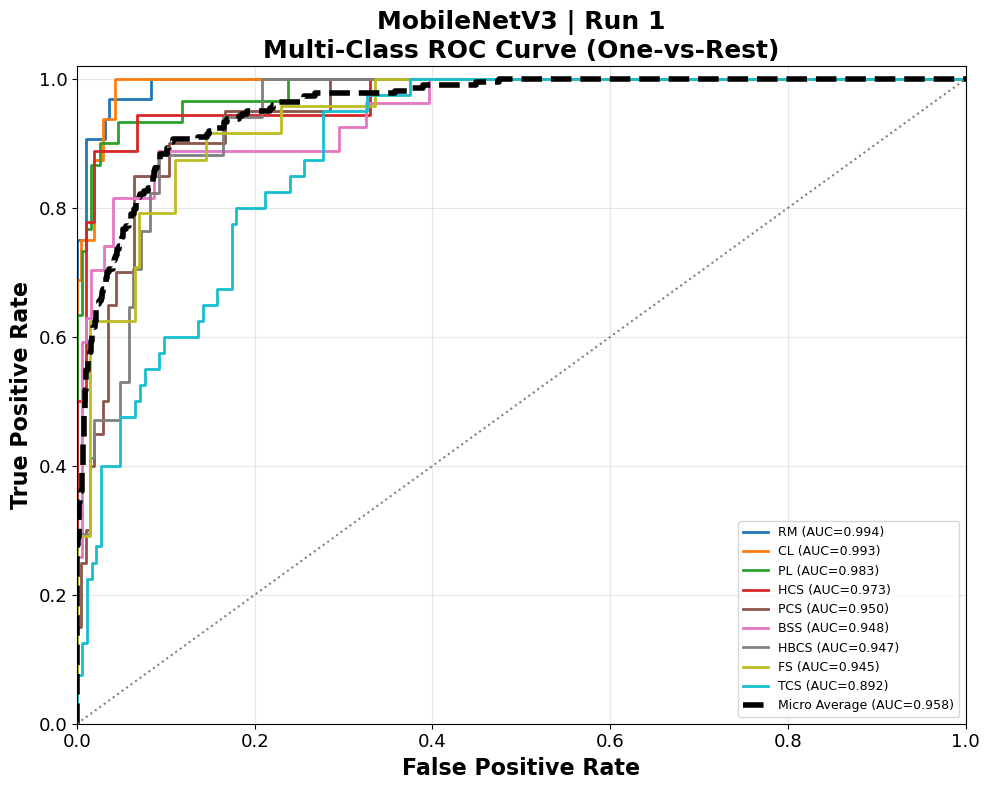


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.993652  Outstanding
1                 CL  0.992788  Outstanding
2                 PL  0.983333    Excellent
3                HCS  0.973031    Excellent
4                PCS  0.950490    Excellent
5                BSS  0.948487    Excellent
6               HBCS  0.947428    Excellent
7                 FS  0.945000    Excellent
8                TCS  0.891848         Good
9      Micro Average  0.957941      Summary
10     Macro Average  0.958451      Summary
11  Weighted Average  0.954354      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 8/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9937

Worst Class                 : TCS (Good)
Worst AUC                   : 0.8918

Micro Aver


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 3.643 sec
Time / Image     : 0.016261 sec
Computing Metrics : MobileNetV3 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.6964
Precision (Macro)     : 0.7376
Recall (Macro)        : 0.6900
F1 Score (Macro)      : 0.6787
Precision (Weighted)  : 0.7368
Recall (Weighted)     : 0.6964
F1 Score (Weighted)   : 0.6849
Balanced Accuracy     : 0.6900
Cohen Kappa           : 0.6553
MCC                   : 0.6636
Log Loss              : 0.9485

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\MobileNetV3_Run2_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\M

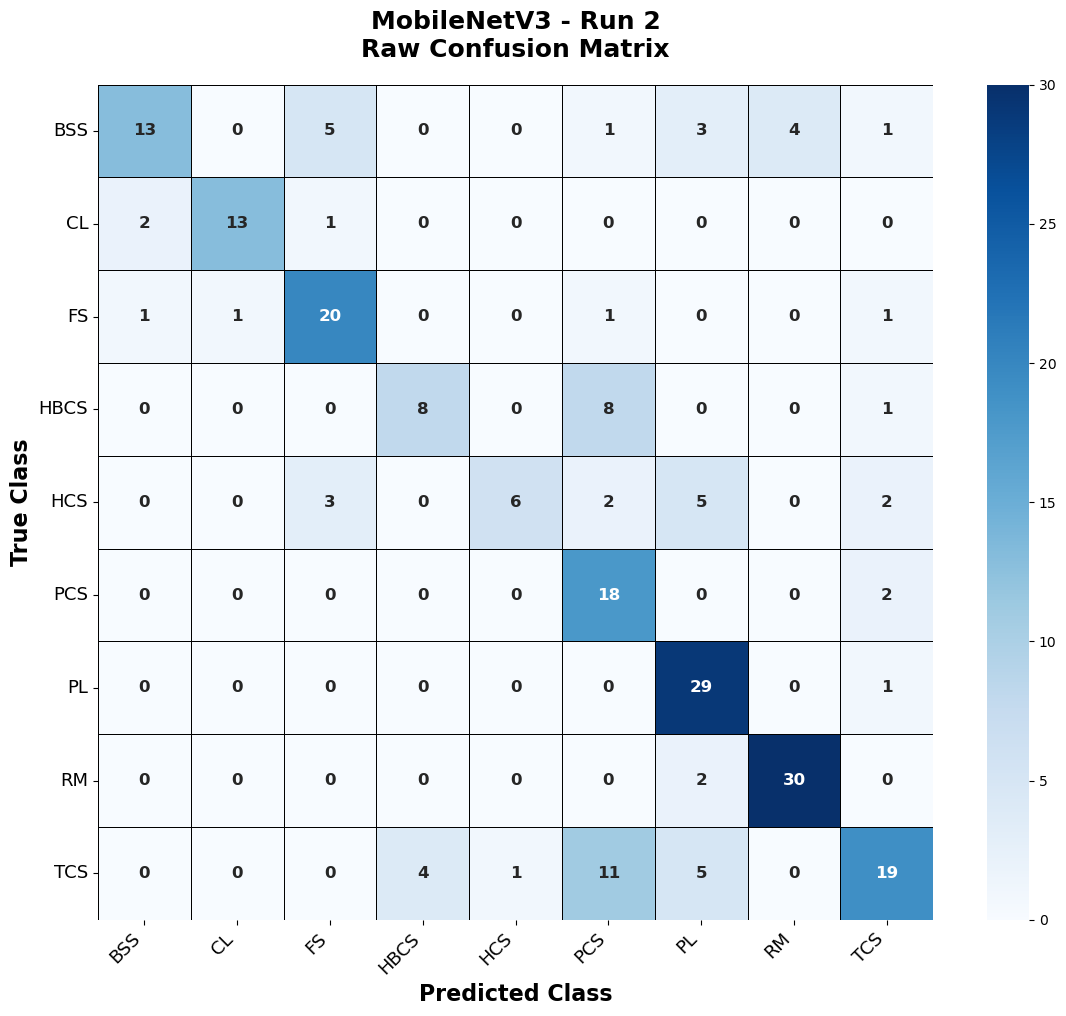

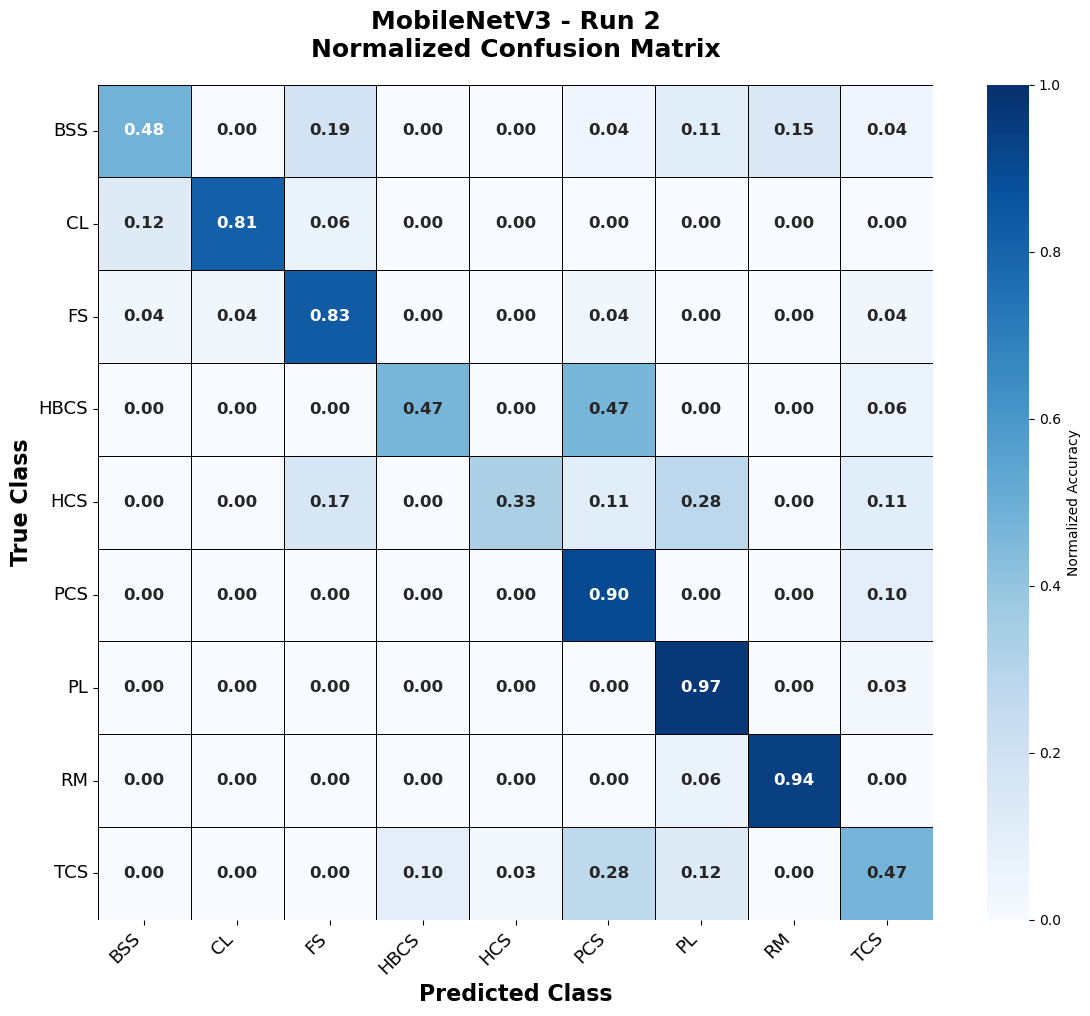


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run2_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run2_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run2_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run2_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN

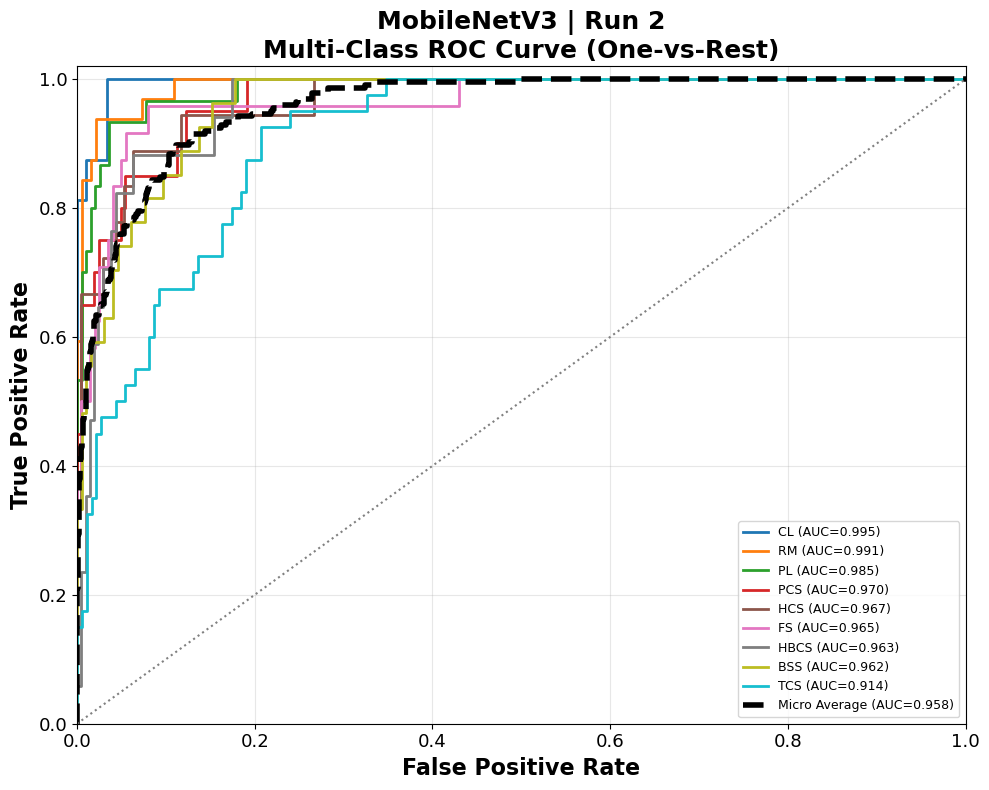


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 CL  0.995192  Outstanding
1                 RM  0.991211  Outstanding
2                 PL  0.985223    Excellent
3                PCS  0.970343    Excellent
4                HCS  0.966559    Excellent
5                 FS  0.964792    Excellent
6               HBCS  0.963058    Excellent
7                BSS  0.961835    Excellent
8                TCS  0.913723    Excellent
9      Micro Average  0.958142      Summary
10     Macro Average  0.967993      Summary
11  Weighted Average  0.964504      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : CL (Outstanding)
Best AUC                    : 0.9952

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9137

Micro


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 3.314 sec
Time / Image     : 0.014796 sec
Computing Metrics : MobileNetV3 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.6696
Precision (Macro)     : 0.6931
Recall (Macro)        : 0.6701
F1 Score (Macro)      : 0.6690
Precision (Weighted)  : 0.6867
Recall (Weighted)     : 0.6696
F1 Score (Weighted)   : 0.6668
Balanced Accuracy     : 0.6701
Cohen Kappa           : 0.6237
MCC                   : 0.6259
Log Loss              : 0.8997

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\MobileNetV3_Run3_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\M

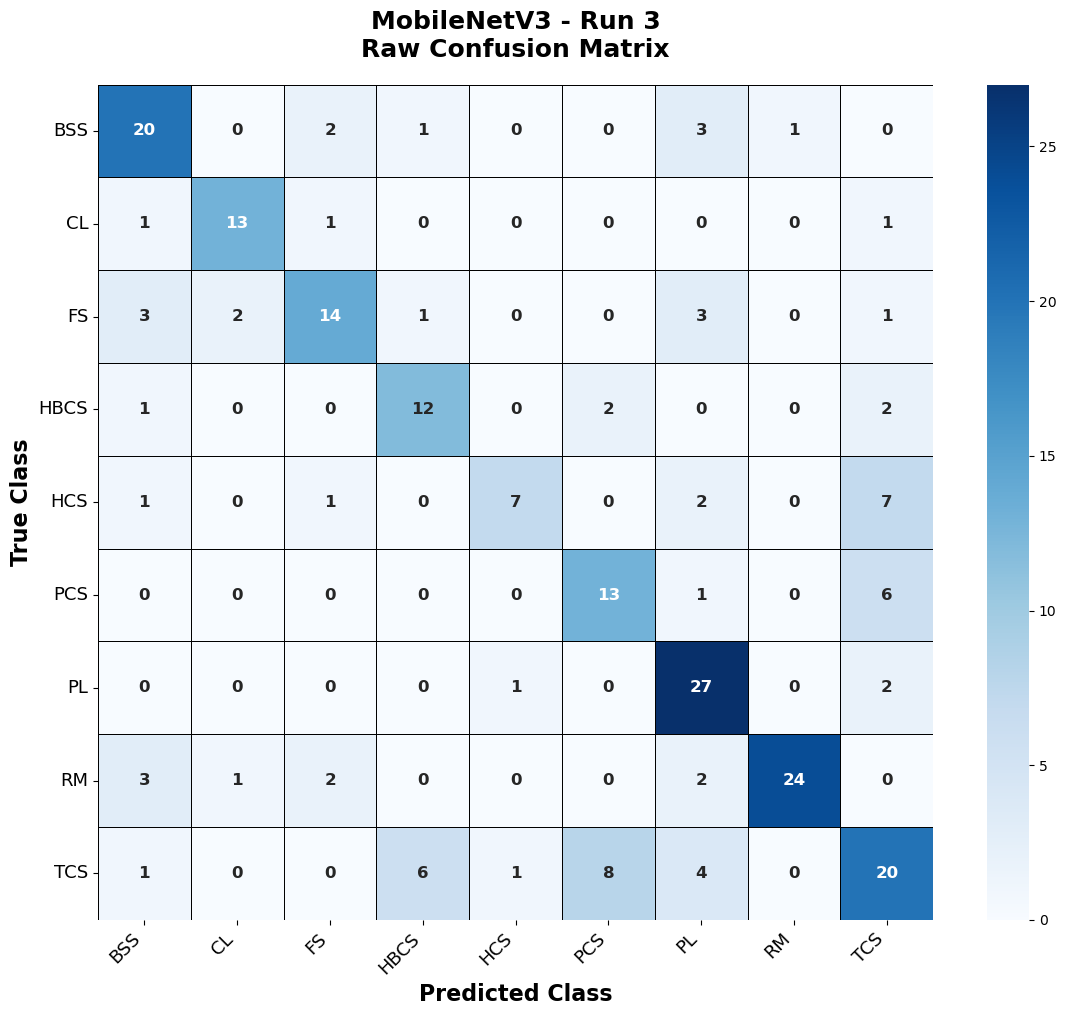

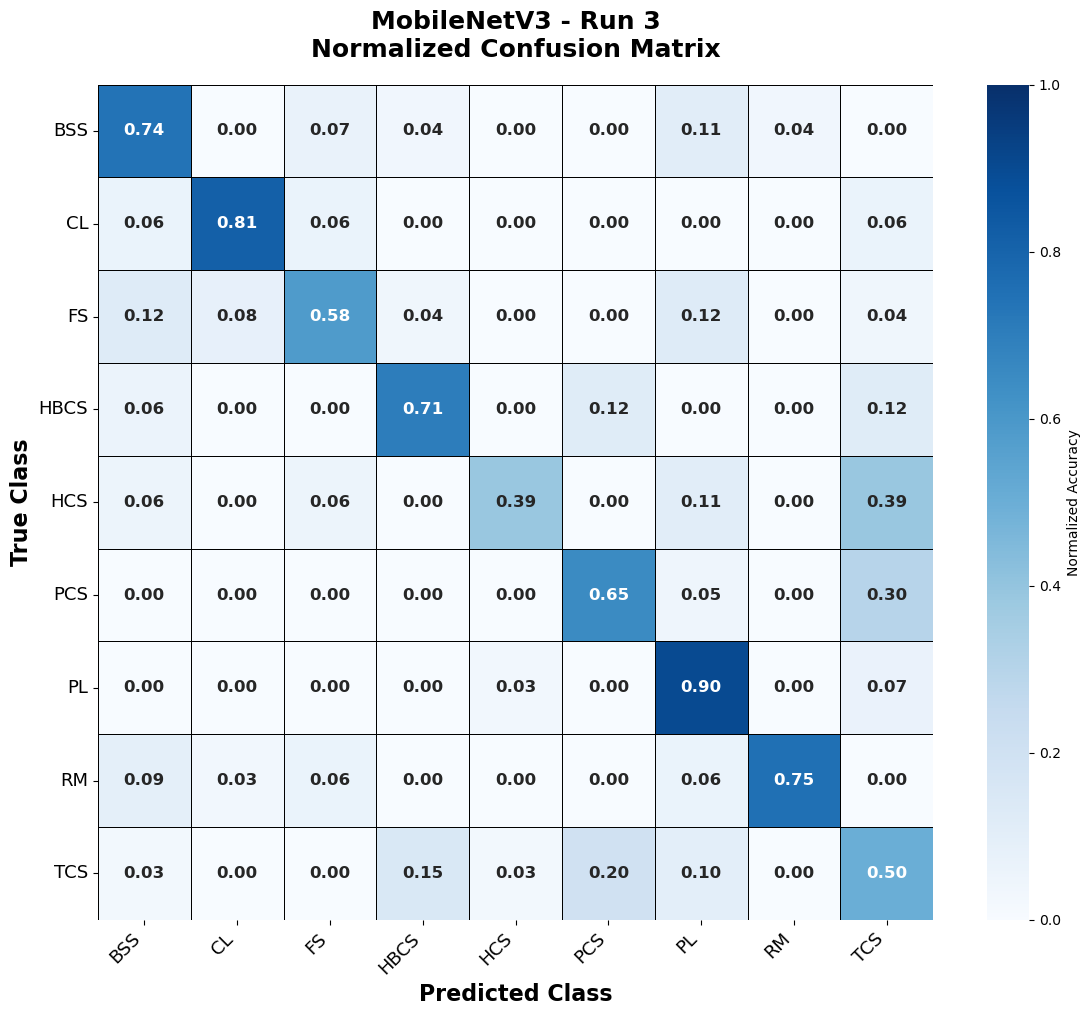


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run3_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run3_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run3_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run3_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN

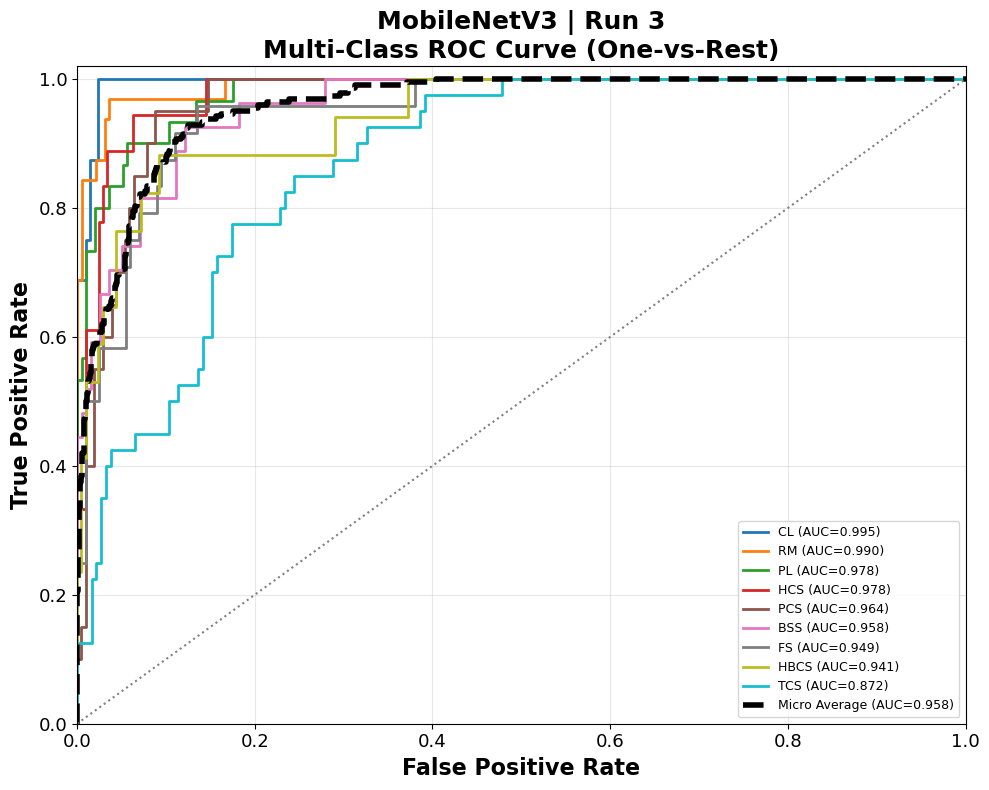


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 CL  0.994591  Outstanding
1                 RM  0.990234  Outstanding
2                 PL  0.978179    Excellent
3                HCS  0.978155    Excellent
4                PCS  0.964216    Excellent
5                BSS  0.958075    Excellent
6                 FS  0.949375    Excellent
7               HBCS  0.941176    Excellent
8                TCS  0.872283         Good
9      Micro Average  0.958247      Summary
10     Macro Average  0.958476      Summary
11  Weighted Average  0.952597      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 8/9

Best Class                  : CL (Outstanding)
Best AUC                    : 0.9946

Worst Class                 : TCS (Good)
Worst AUC                   : 0.8723

Micro Aver


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 3.327 sec
Time / Image     : 0.014854 sec
Computing Metrics : MobileNetV3 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.6786
Precision (Macro)     : 0.7098
Recall (Macro)        : 0.6669
F1 Score (Macro)      : 0.6699
Precision (Weighted)  : 0.6996
Recall (Weighted)     : 0.6786
F1 Score (Weighted)   : 0.6732
Balanced Accuracy     : 0.6669
Cohen Kappa           : 0.6328
MCC                   : 0.6366
Log Loss              : 0.9199

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\MobileNetV3_Run4_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\M

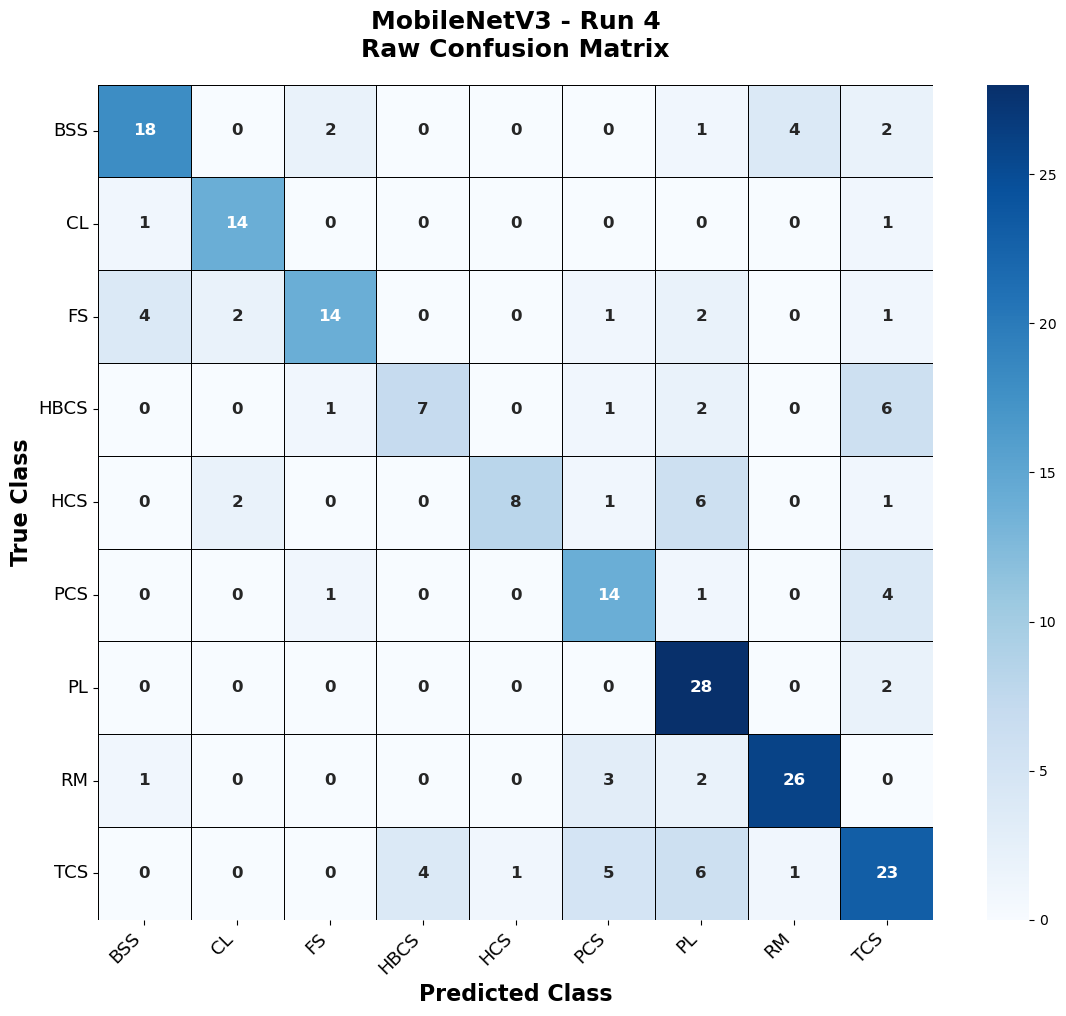

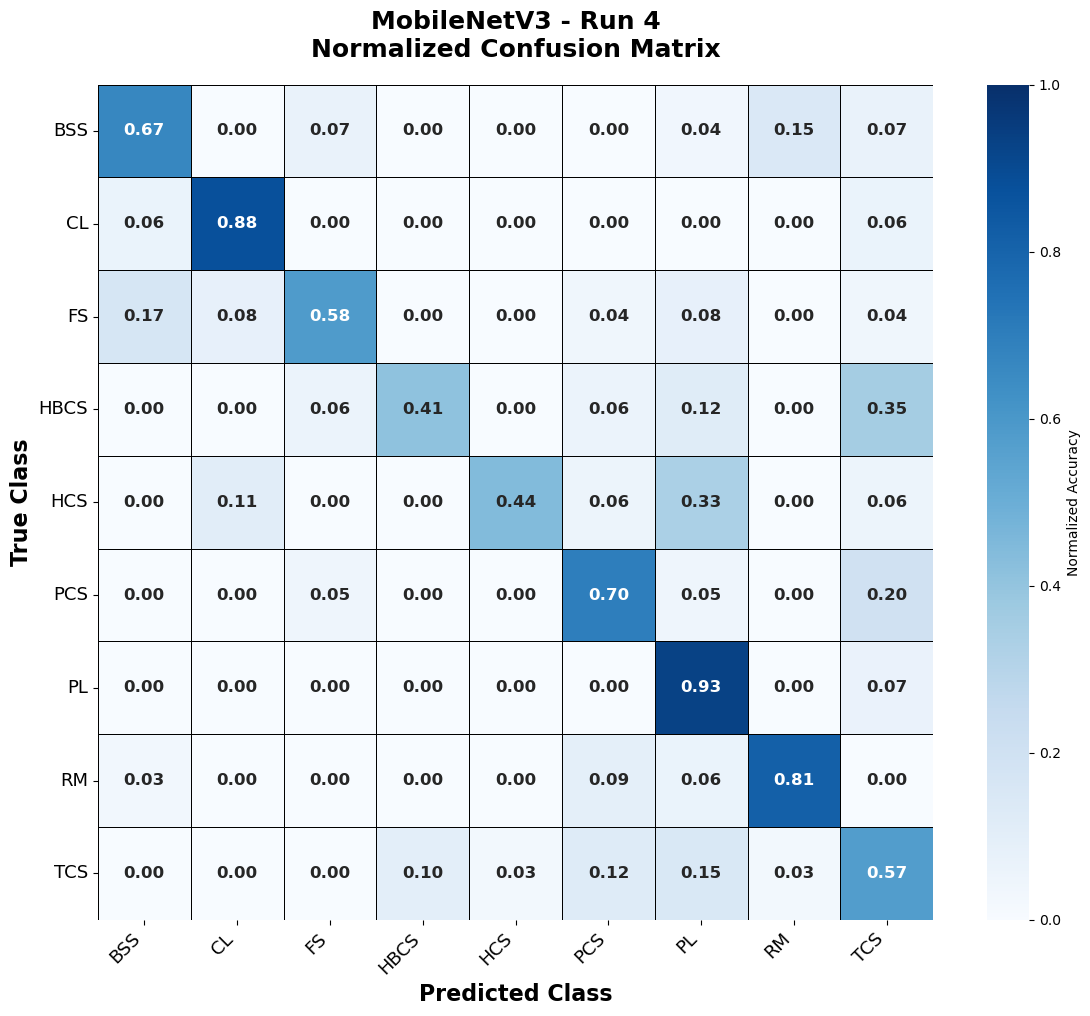


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run4_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run4_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run4_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run4_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN

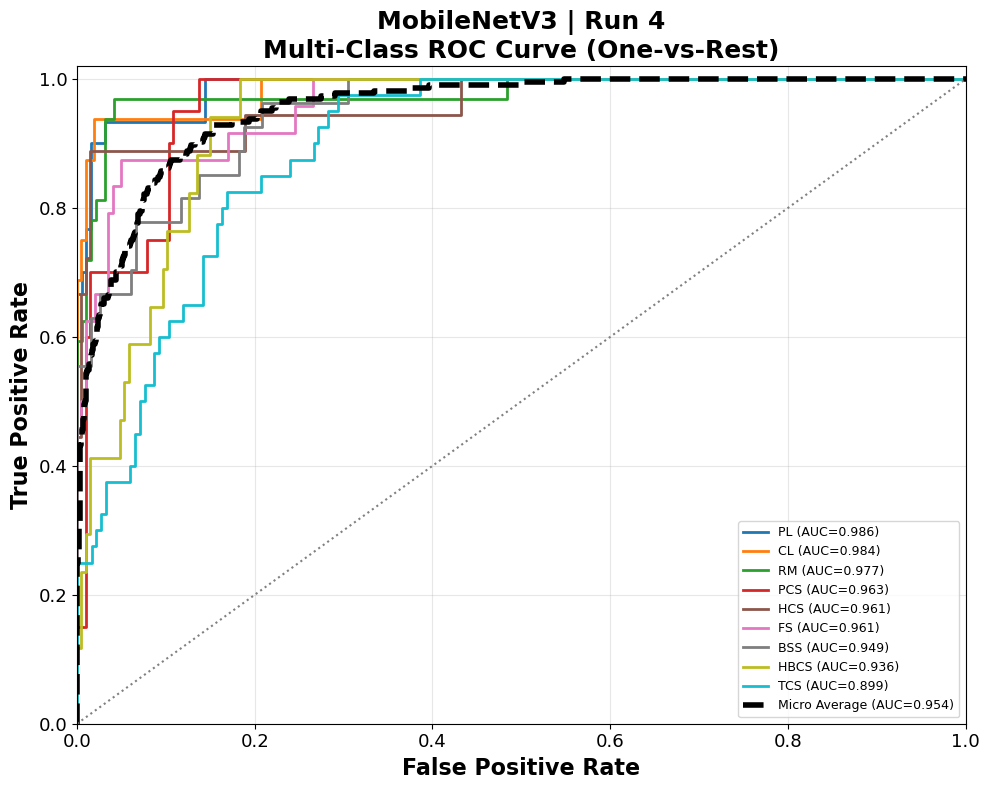


AUC Values
--------------------------------------------------------------------------------
               Class       AUC Performance
0                 PL  0.986426   Excellent
1                 CL  0.984375   Excellent
2                 RM  0.976888   Excellent
3                PCS  0.962500   Excellent
4                HCS  0.961435   Excellent
5                 FS  0.961250   Excellent
6                BSS  0.948675   Excellent
7               HBCS  0.936346   Excellent
8                TCS  0.898913        Good
9      Micro Average  0.954064     Summary
10     Macro Average  0.957423     Summary
11  Weighted Average  0.954097     Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 8/9

Best Class                  : PL (Excellent)
Best AUC                    : 0.9864

Worst Class                 : TCS (Good)
Worst AUC                   : 0.8989

Micro Average            


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 3.343 sec
Time / Image     : 0.014923 sec
Computing Metrics : MobileNetV3 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.6607
Precision (Macro)     : 0.7085
Recall (Macro)        : 0.6605
F1 Score (Macro)      : 0.6519
Precision (Weighted)  : 0.6979
Recall (Weighted)     : 0.6607
F1 Score (Weighted)   : 0.6516
Balanced Accuracy     : 0.6605
Cohen Kappa           : 0.6142
MCC                   : 0.6200
Log Loss              : 1.0778

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\MobileNetV3_Run5_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\M

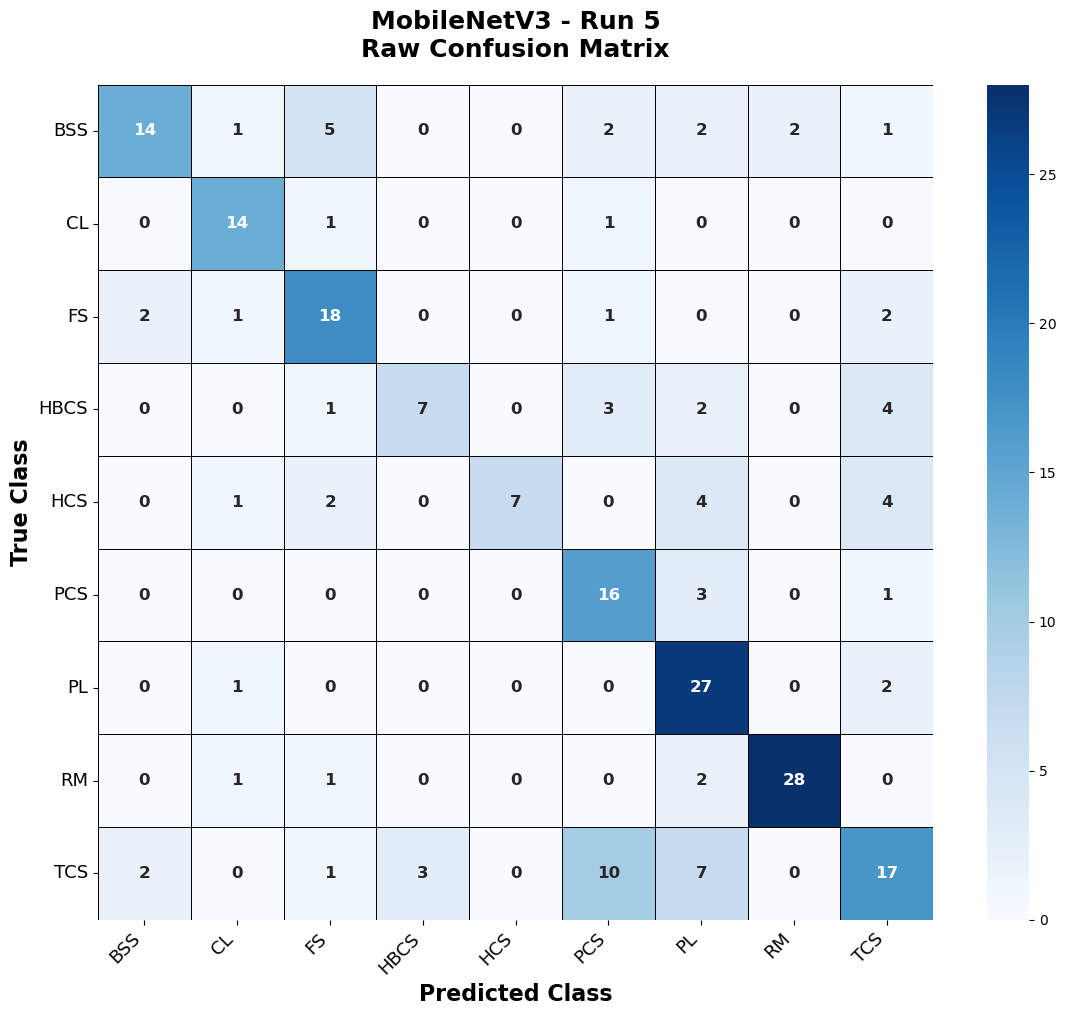

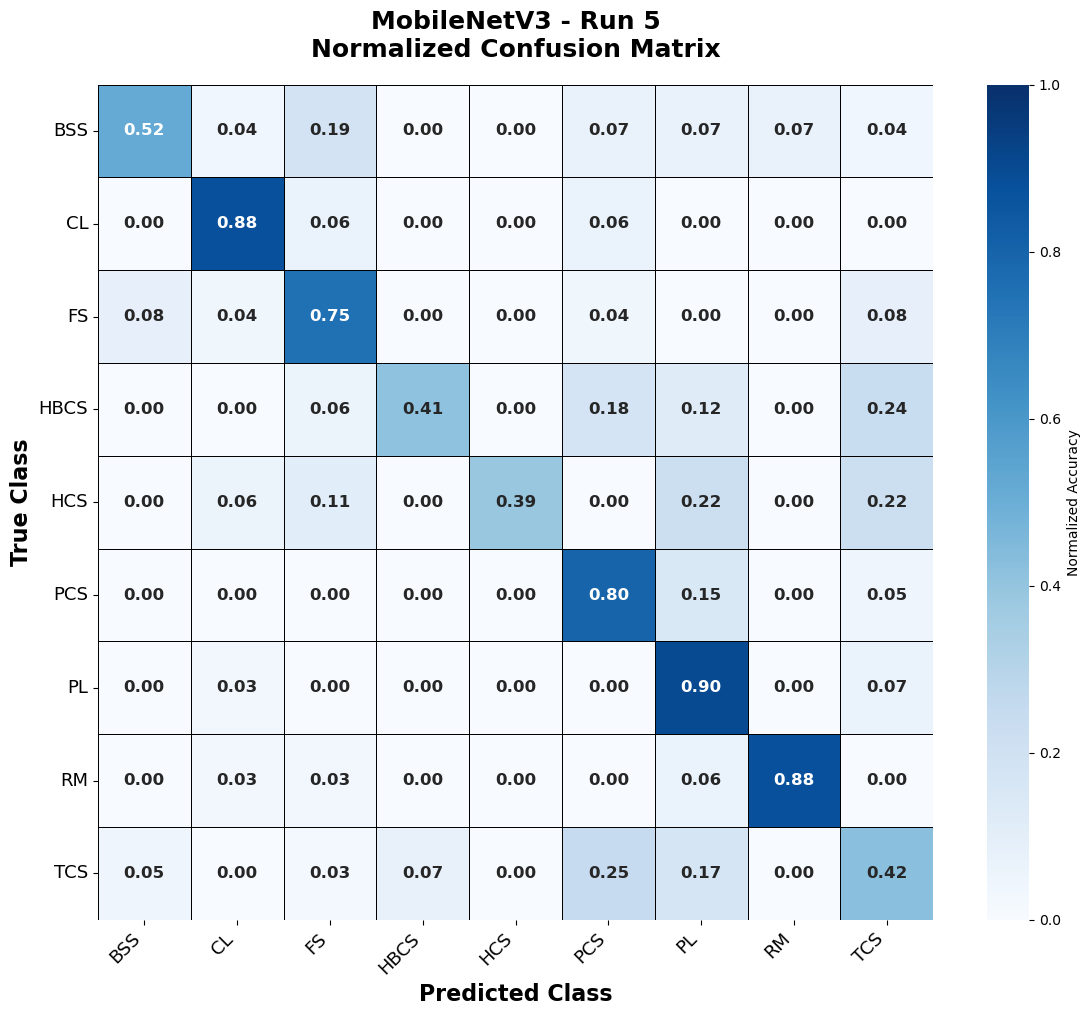


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run5_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run5_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run5_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\MobileNetV3_Run5_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN

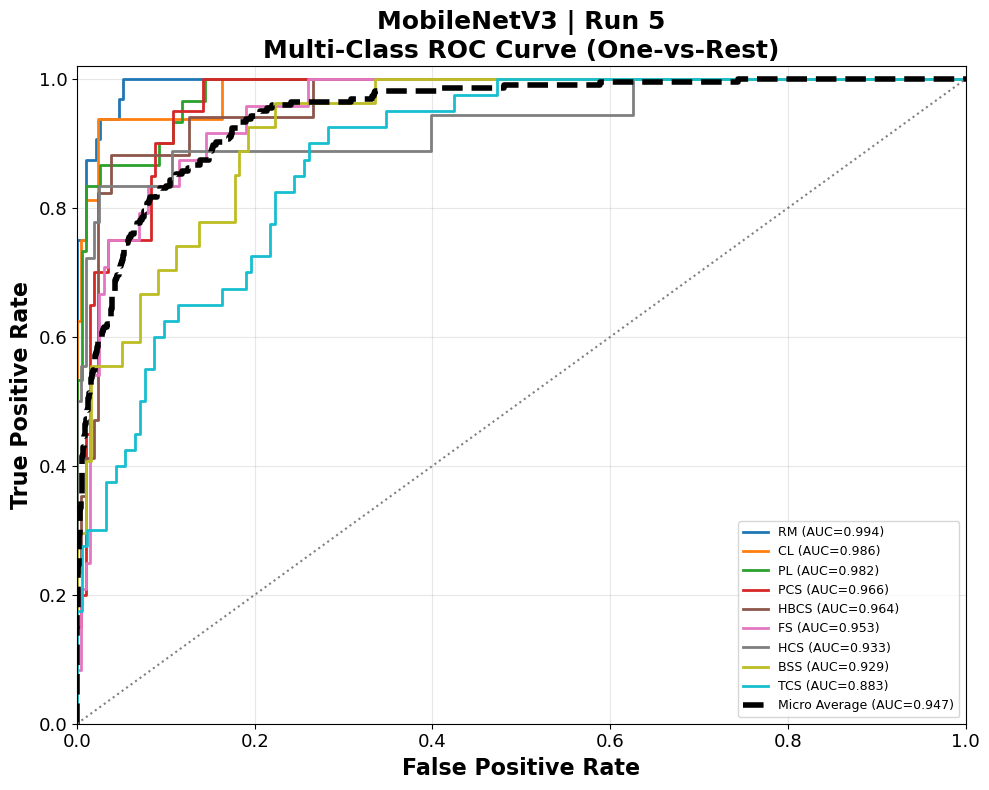


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.994141  Outstanding
1                 CL  0.985577    Excellent
2                 PL  0.981615    Excellent
3                PCS  0.966422    Excellent
4               HBCS  0.963910    Excellent
5                 FS  0.952917    Excellent
6                HCS  0.932848    Excellent
7                BSS  0.929122    Excellent
8                TCS  0.882745         Good
9      Micro Average  0.947007      Summary
10     Macro Average  0.954366      Summary
11  Weighted Average  0.950011      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 8/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9941

Worst Class                 : TCS (Good)
Worst AUC                   : 0.8827

Micro Aver


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 5.196 sec
Time / Image     : 0.023196 sec
Computing Metrics : EfficientNet_B0 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.7009
Precision (Macro)     : 0.6911
Recall (Macro)        : 0.6997
F1 Score (Macro)      : 0.6908
Precision (Weighted)  : 0.7024
Recall (Weighted)     : 0.7009
F1 Score (Weighted)   : 0.6953
Balanced Accuracy     : 0.6997
Cohen Kappa           : 0.6606
MCC                   : 0.6627
Log Loss              : 1.0760

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\EfficientNet_B0_Run1_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\M

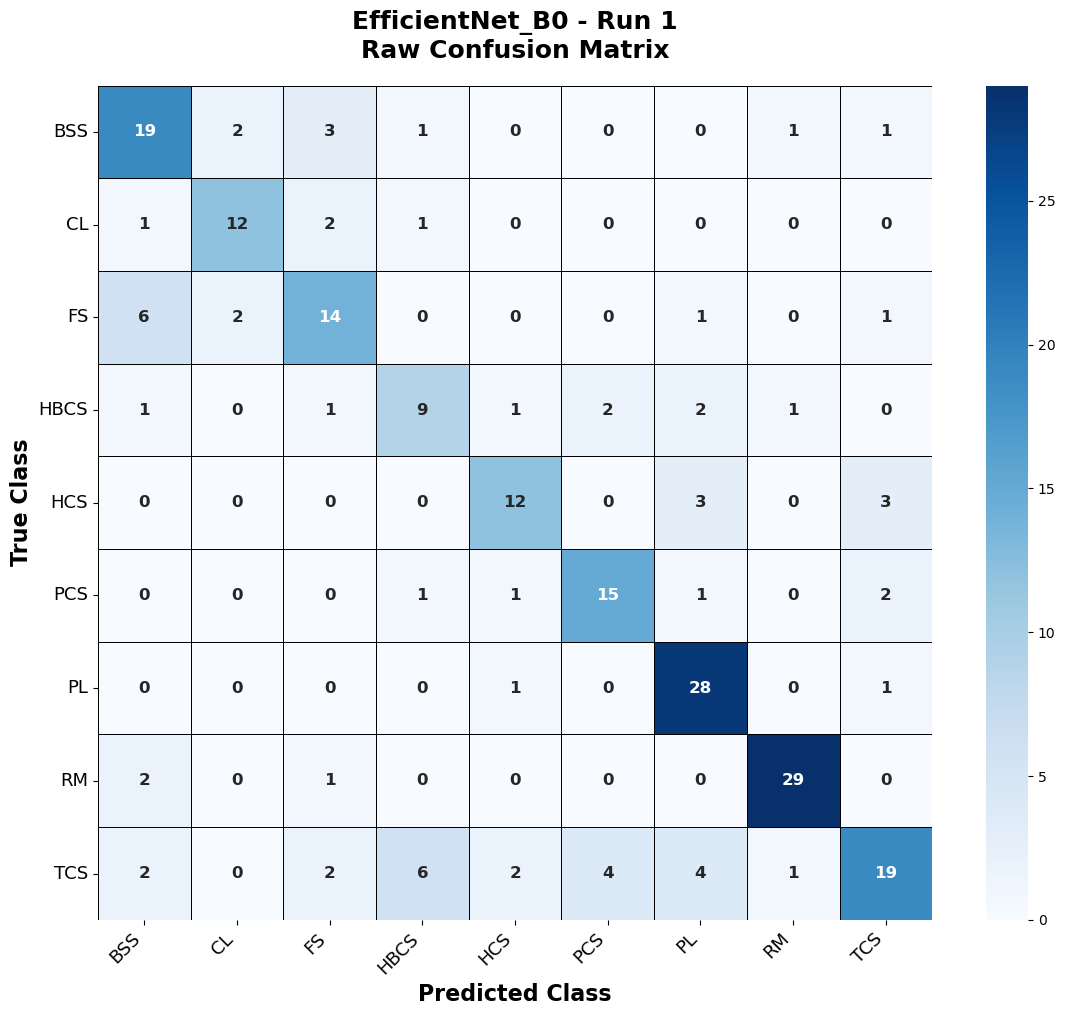

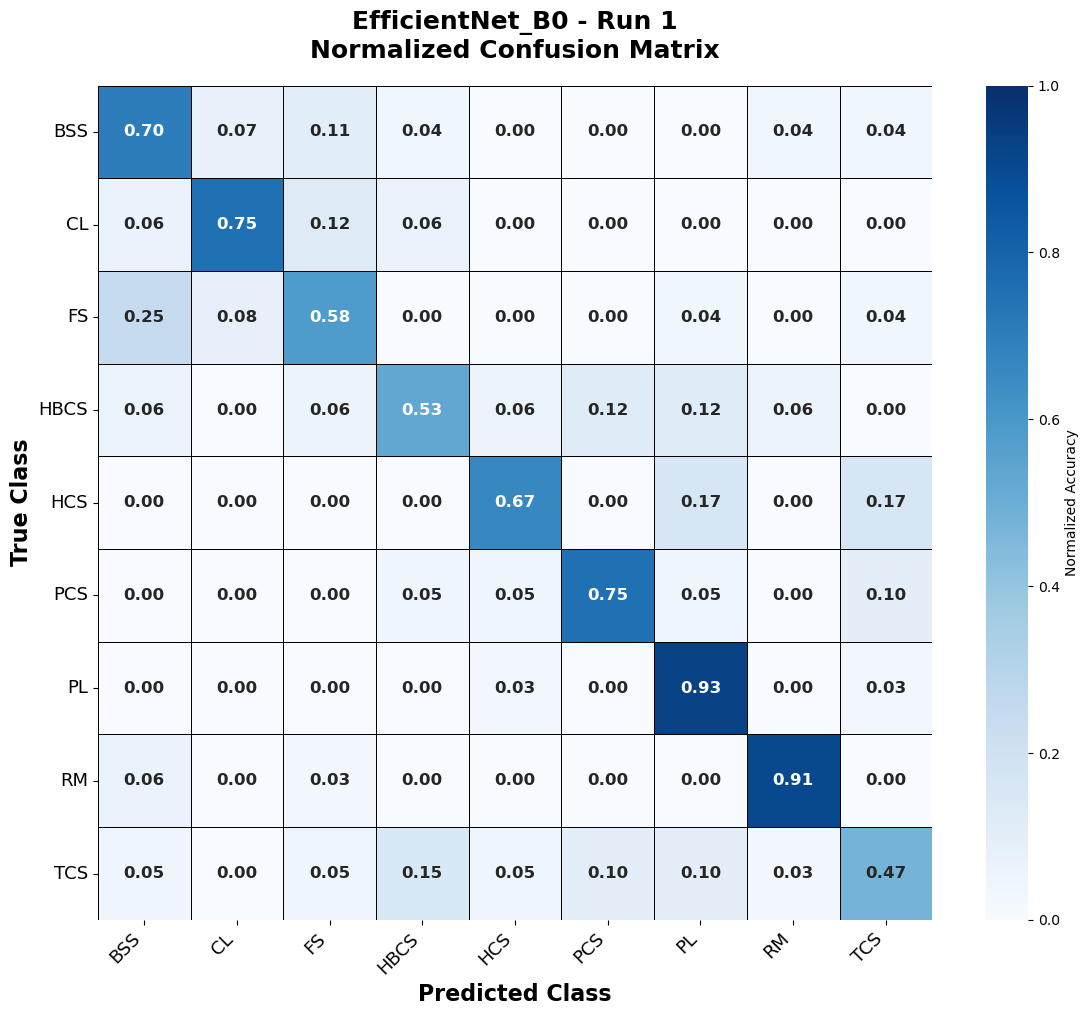


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run1_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run1_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run1_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run1_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Bench

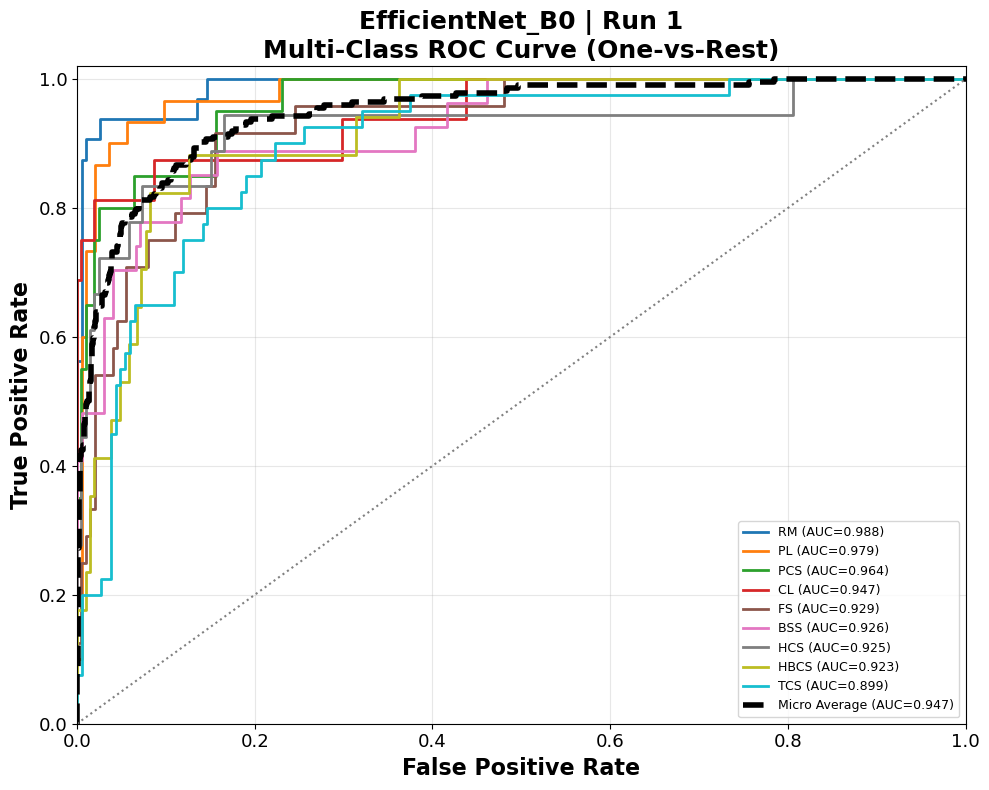


AUC Values
--------------------------------------------------------------------------------
               Class       AUC Performance
0                 RM  0.988444   Excellent
1                 PL  0.979381   Excellent
2                PCS  0.964461   Excellent
3                 CL  0.947115   Excellent
4                 FS  0.928958   Excellent
5                BSS  0.925550   Excellent
6                HCS  0.925027   Excellent
7               HBCS  0.923274   Excellent
8                TCS  0.898777        Good
9      Micro Average  0.946969     Summary
10     Macro Average  0.942332     Summary
11  Weighted Average  0.942129     Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 8/9

Best Class                  : RM (Excellent)
Best AUC                    : 0.9884

Worst Class                 : TCS (Good)
Worst AUC                   : 0.8988

Micro Average            


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 5.142 sec
Time / Image     : 0.022955 sec
Computing Metrics : EfficientNet_B0 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.6964
Precision (Macro)     : 0.6912
Recall (Macro)        : 0.6737
F1 Score (Macro)      : 0.6772
Precision (Weighted)  : 0.6969
Recall (Weighted)     : 0.6964
F1 Score (Weighted)   : 0.6920
Balanced Accuracy     : 0.6737
Cohen Kappa           : 0.6536
MCC                   : 0.6548
Log Loss              : 0.9525

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\EfficientNet_B0_Run2_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\M

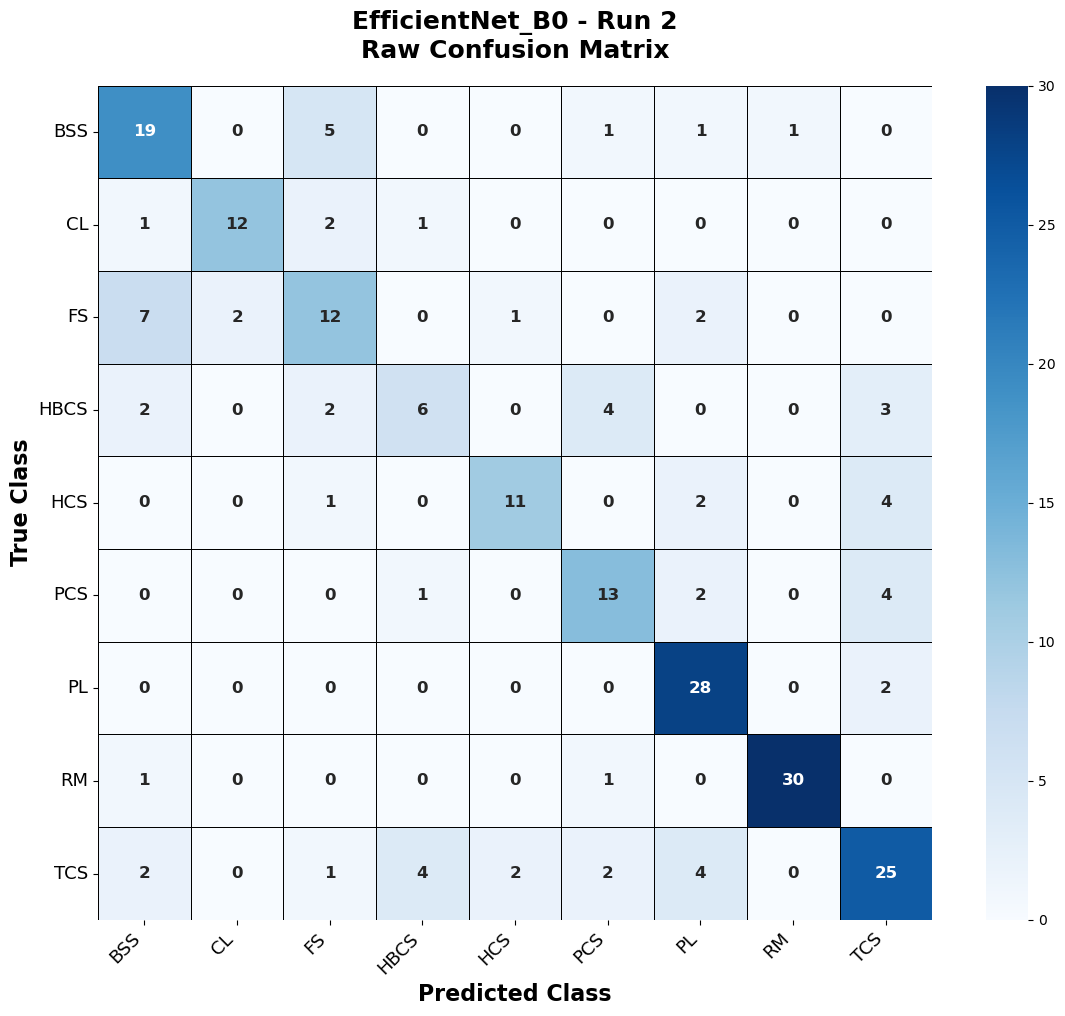

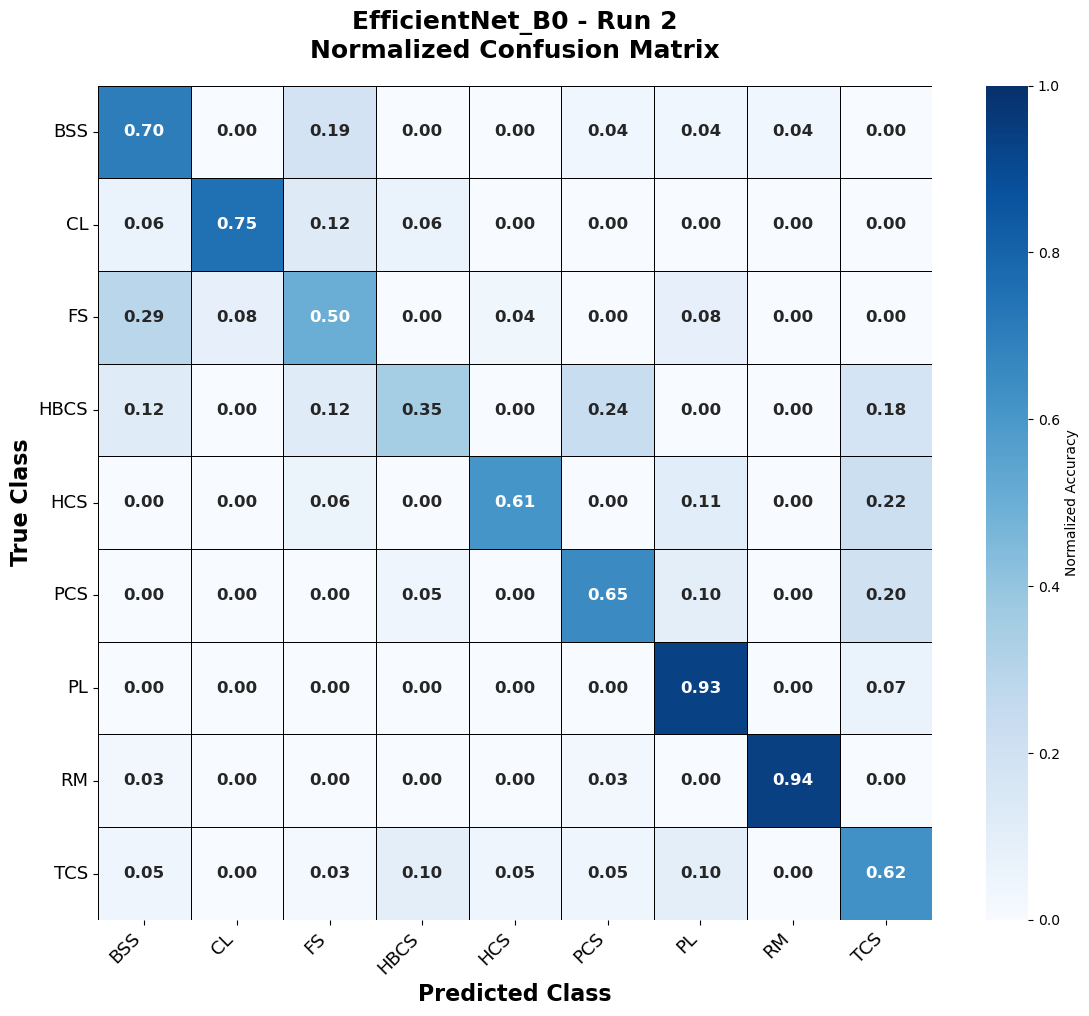


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run2_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run2_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run2_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run2_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Bench

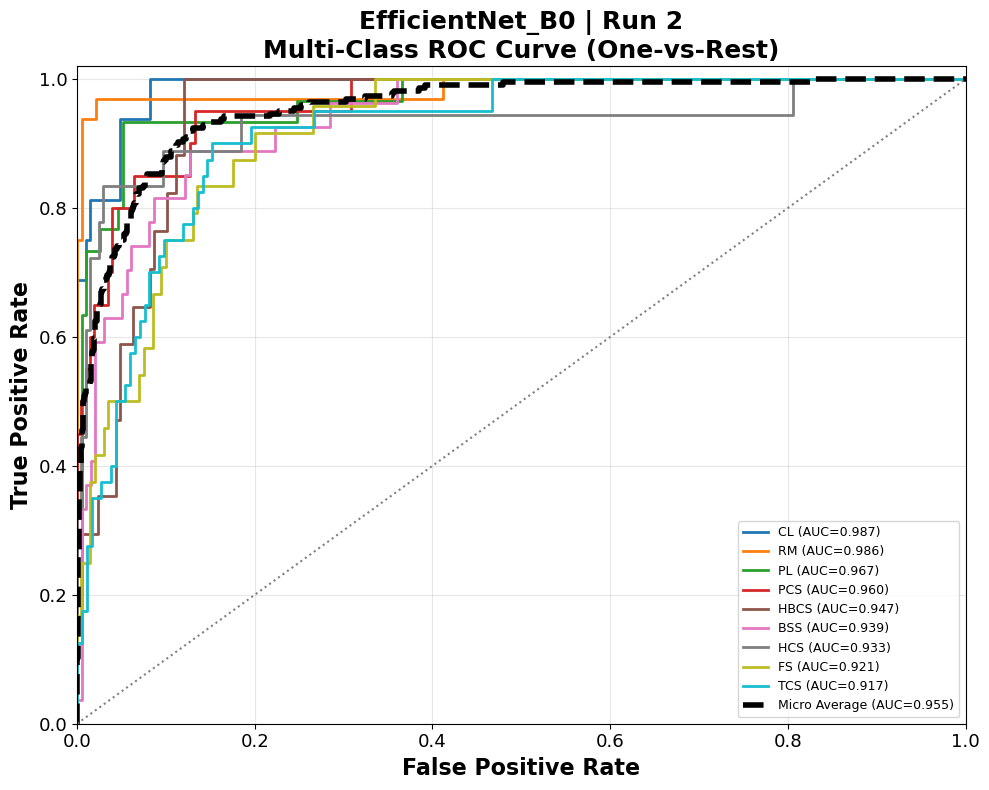


AUC Values
--------------------------------------------------------------------------------
               Class       AUC Performance
0                 CL  0.987380   Excellent
1                 RM  0.985514   Excellent
2                 PL  0.967010   Excellent
3                PCS  0.960294   Excellent
4               HBCS  0.947428   Excellent
5                BSS  0.938898   Excellent
6                HCS  0.932848   Excellent
7                 FS  0.921250   Excellent
8                TCS  0.917391   Excellent
9      Micro Average  0.954921     Summary
10     Macro Average  0.950890     Summary
11  Weighted Average  0.949126     Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : CL (Excellent)
Best AUC                    : 0.9874

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9174

Micro Average       


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 5.178 sec
Time / Image     : 0.023115 sec
Computing Metrics : EfficientNet_B0 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.7143
Precision (Macro)     : 0.7337
Recall (Macro)        : 0.6981
F1 Score (Macro)      : 0.7074
Precision (Weighted)  : 0.7214
Recall (Weighted)     : 0.7143
F1 Score (Weighted)   : 0.7106
Balanced Accuracy     : 0.6981
Cohen Kappa           : 0.6733
MCC                   : 0.6750
Log Loss              : 0.8554

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\EfficientNet_B0_Run3_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\M

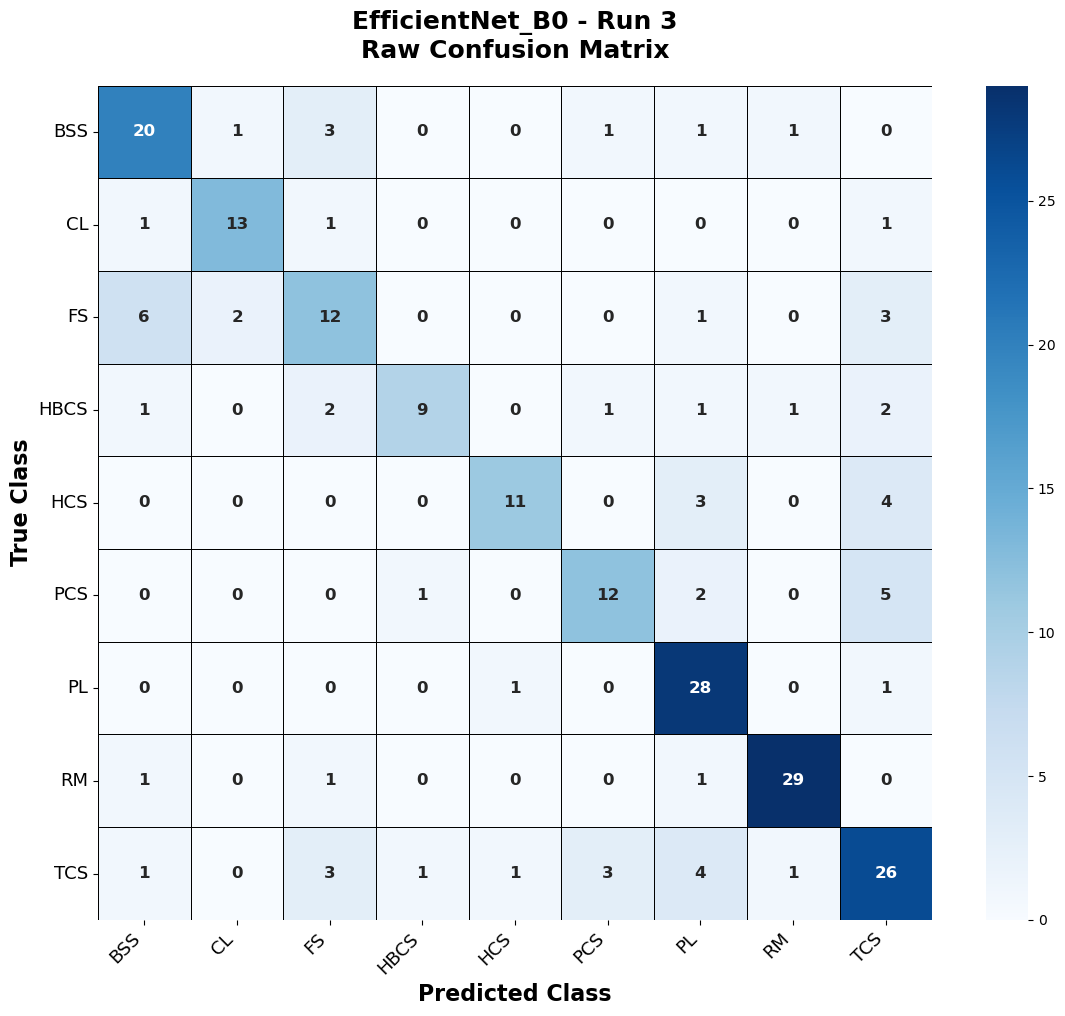

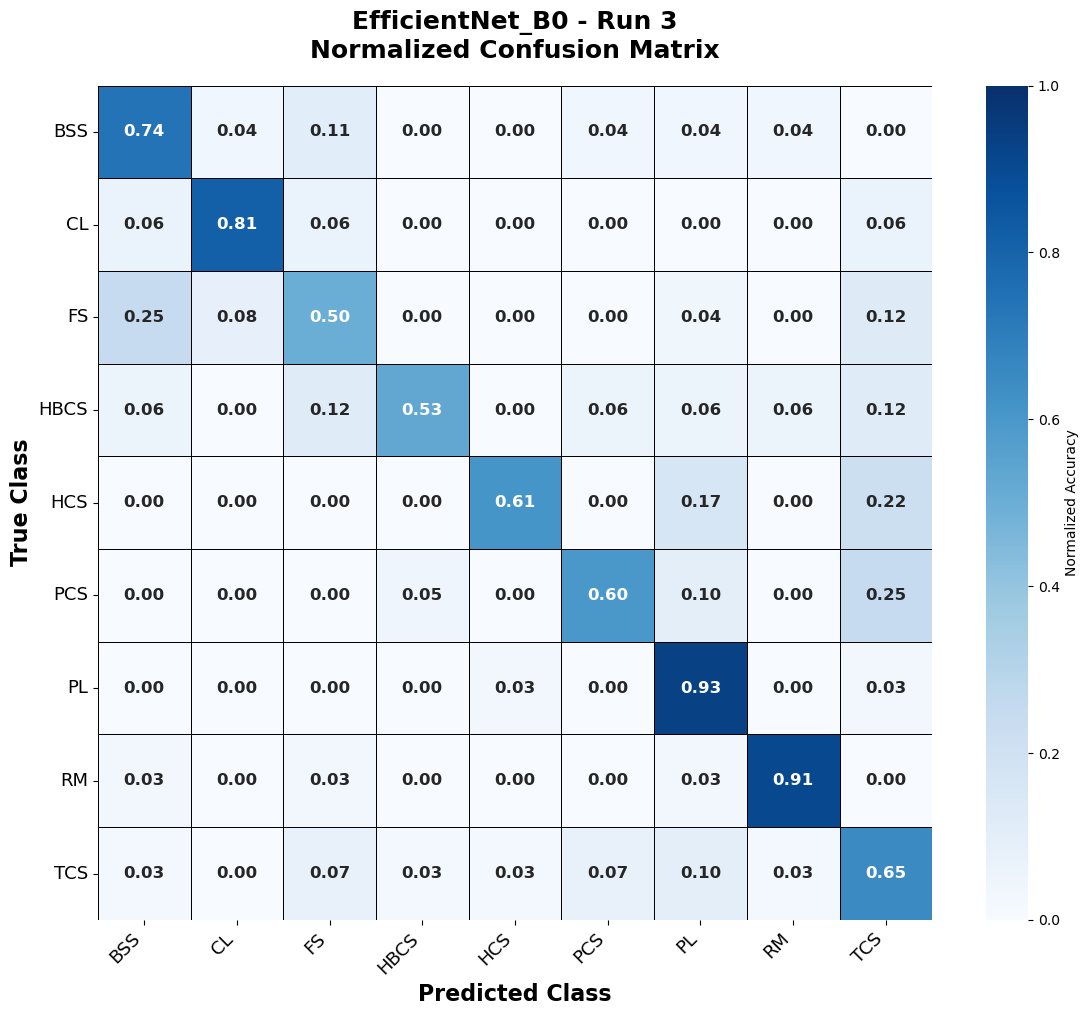


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run3_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run3_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run3_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run3_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Bench

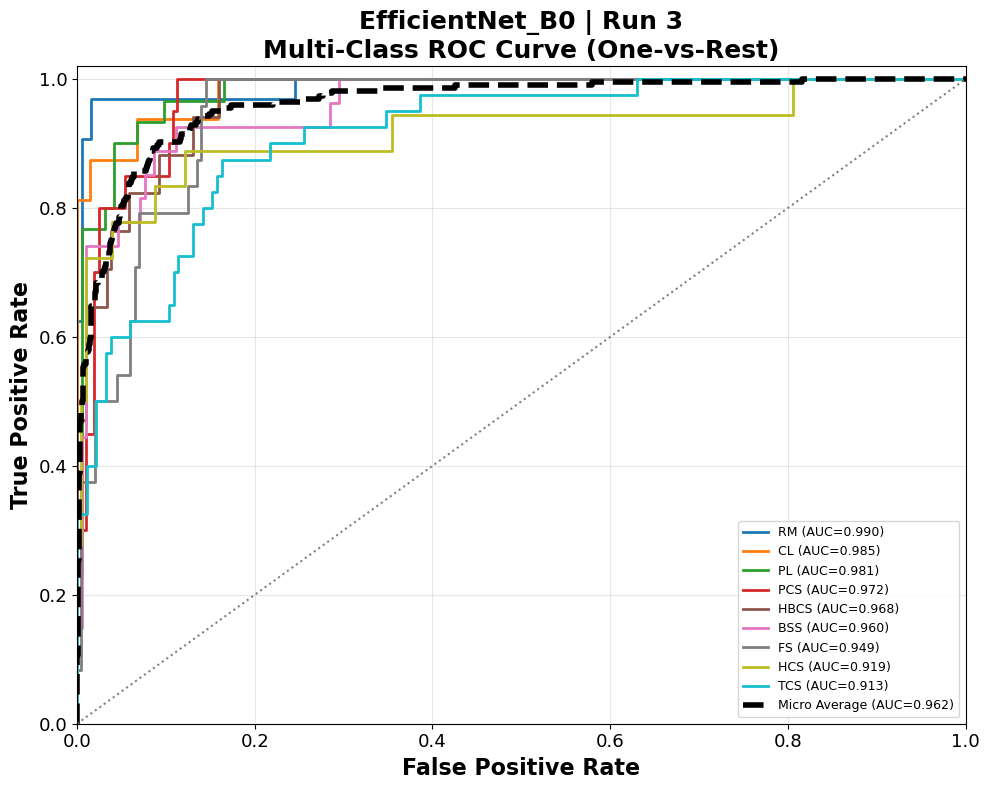


AUC Values
--------------------------------------------------------------------------------
               Class       AUC Performance
0                 RM  0.989909   Excellent
1                 CL  0.984976   Excellent
2                 PL  0.981100   Excellent
3                PCS  0.972059   Excellent
4               HBCS  0.968173   Excellent
5                BSS  0.959579   Excellent
6                 FS  0.949375   Excellent
7                HCS  0.918554   Excellent
8                TCS  0.913451   Excellent
9      Micro Average  0.961899     Summary
10     Macro Average  0.959686     Summary
11  Weighted Average  0.957748     Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 9/9

Best Class                  : RM (Excellent)
Best AUC                    : 0.9899

Worst Class                 : TCS (Excellent)
Worst AUC                   : 0.9135

Micro Average       


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 5.233 sec
Time / Image     : 0.023360 sec
Computing Metrics : EfficientNet_B0 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.7009
Precision (Macro)     : 0.6973
Recall (Macro)        : 0.6858
F1 Score (Macro)      : 0.6889
Precision (Weighted)  : 0.7042
Recall (Weighted)     : 0.7009
F1 Score (Weighted)   : 0.7002
Balanced Accuracy     : 0.6858
Cohen Kappa           : 0.6593
MCC                   : 0.6598
Log Loss              : 0.9158

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\EfficientNet_B0_Run4_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\M

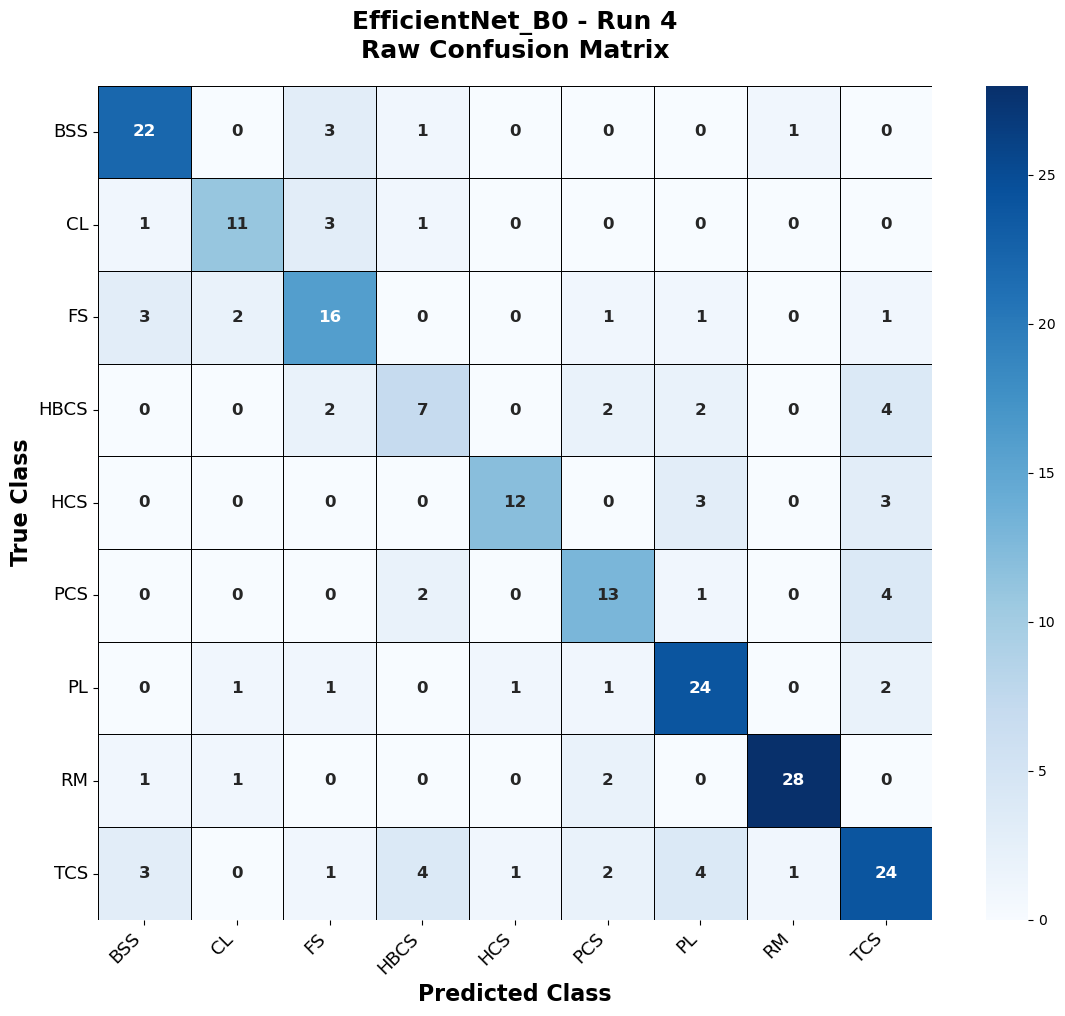

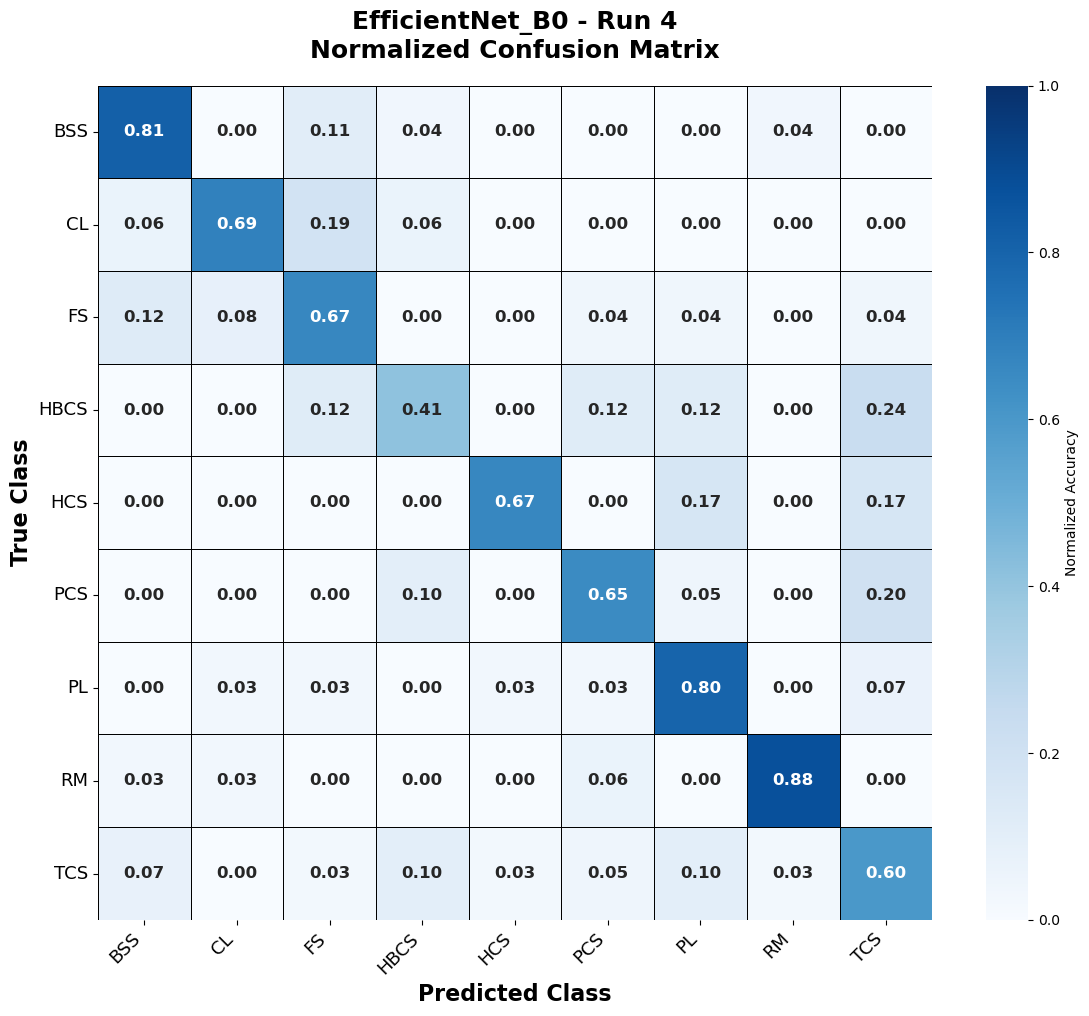


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run4_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run4_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run4_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run4_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Bench

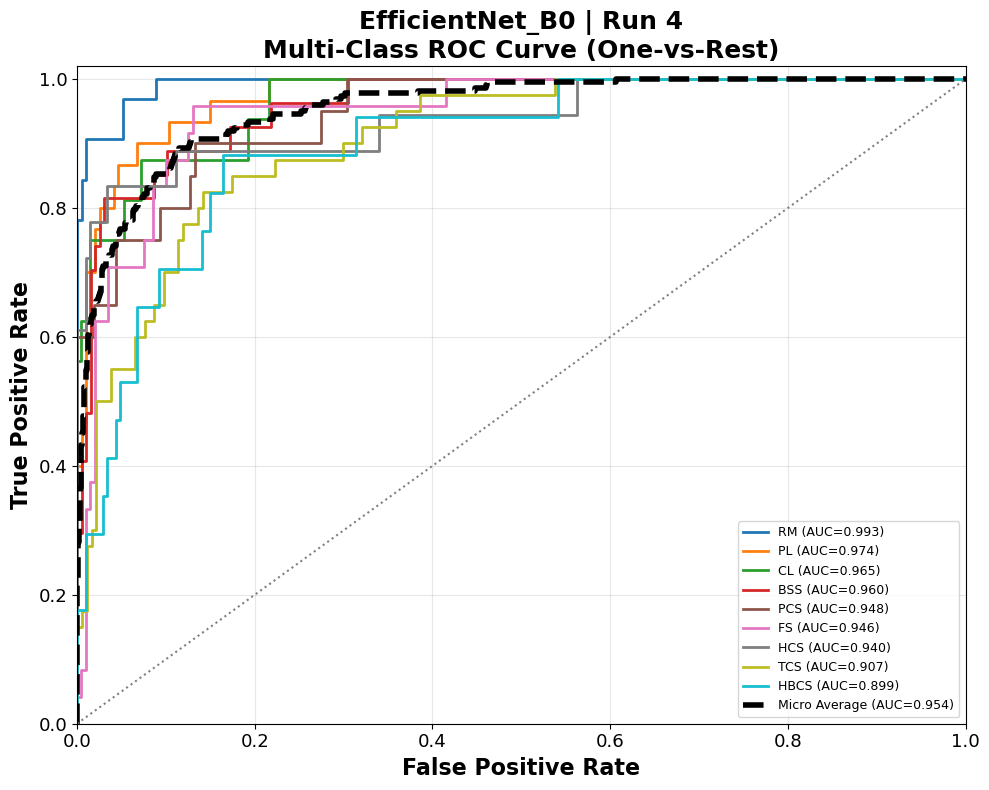


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.993001  Outstanding
1                 PL  0.974227    Excellent
2                 CL  0.964543    Excellent
3                BSS  0.959767    Excellent
4                PCS  0.948039    Excellent
5                 FS  0.946458    Excellent
6                HCS  0.939860    Excellent
7                TCS  0.906793    Excellent
8               HBCS  0.899403         Good
9      Micro Average  0.954196      Summary
10     Macro Average  0.948010      Summary
11  Weighted Average  0.948679      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 8/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9930

Worst Class                 : HBCS (Good)
Worst AUC                   : 0.8994

Micro Ave


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 5.125 sec
Time / Image     : 0.022881 sec
Computing Metrics : EfficientNet_B0 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.6920
Precision (Macro)     : 0.7148
Recall (Macro)        : 0.6738
F1 Score (Macro)      : 0.6835
Precision (Weighted)  : 0.7015
Recall (Weighted)     : 0.6920
F1 Score (Weighted)   : 0.6879
Balanced Accuracy     : 0.6738
Cohen Kappa           : 0.6480
MCC                   : 0.6497
Log Loss              : 1.0195

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\EfficientNet_B0_Run5_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\M

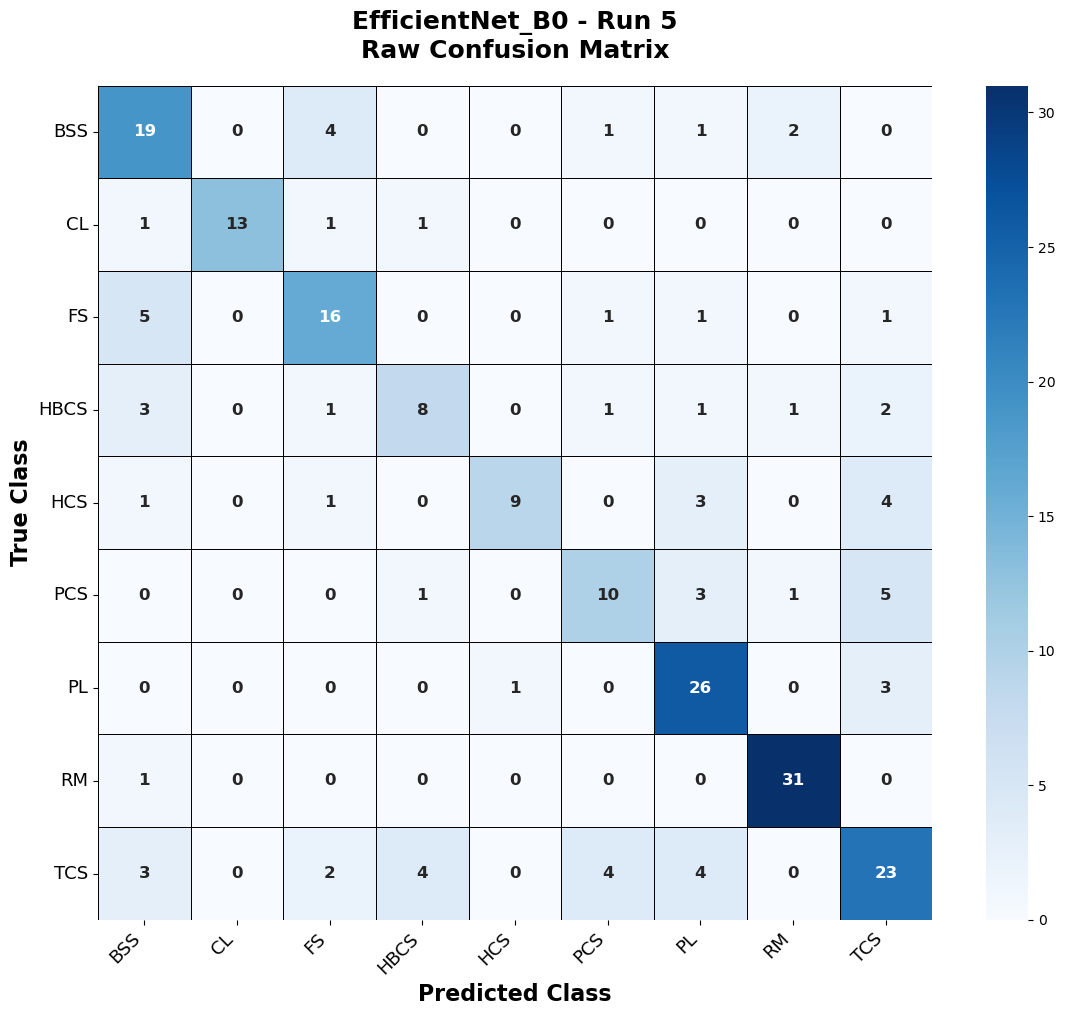

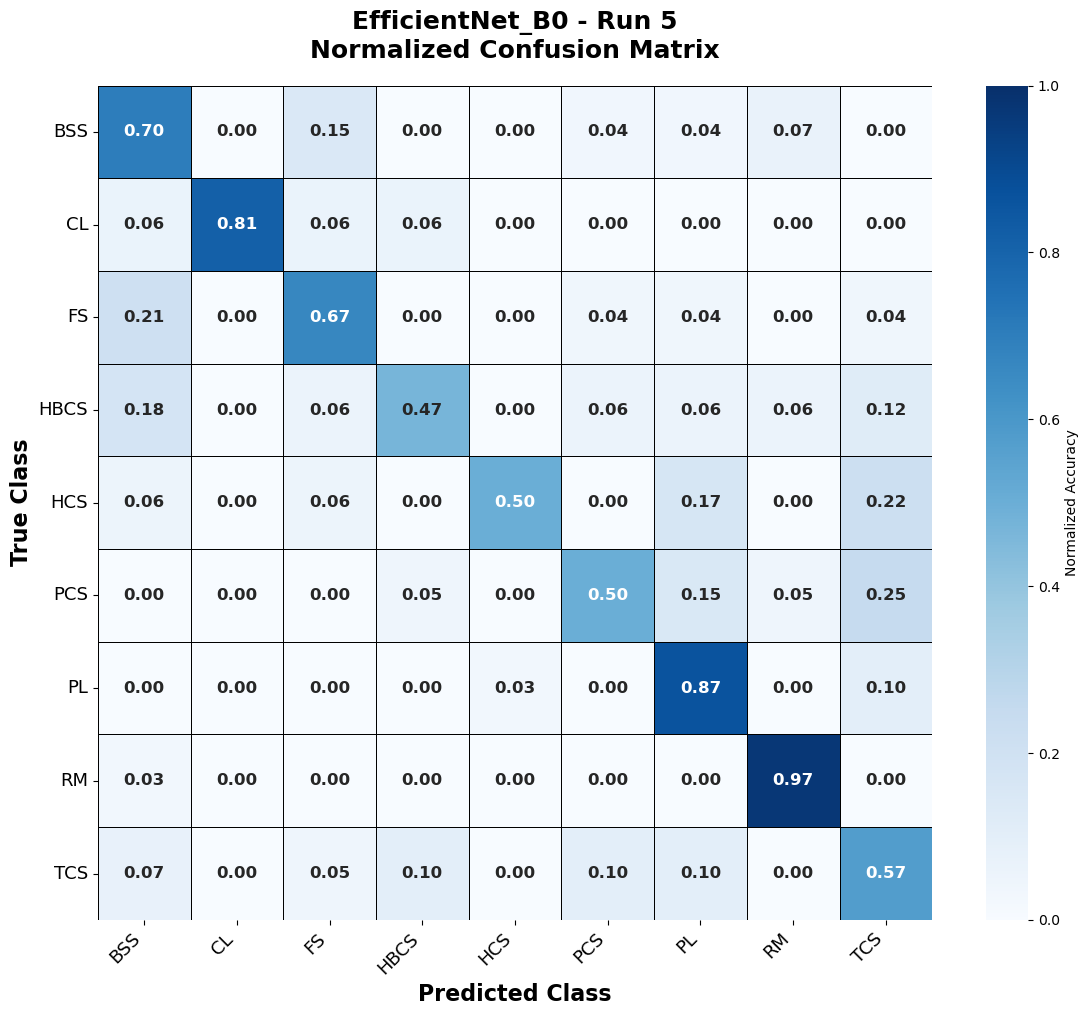


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run5_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run5_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run5_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B0_Run5_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Bench

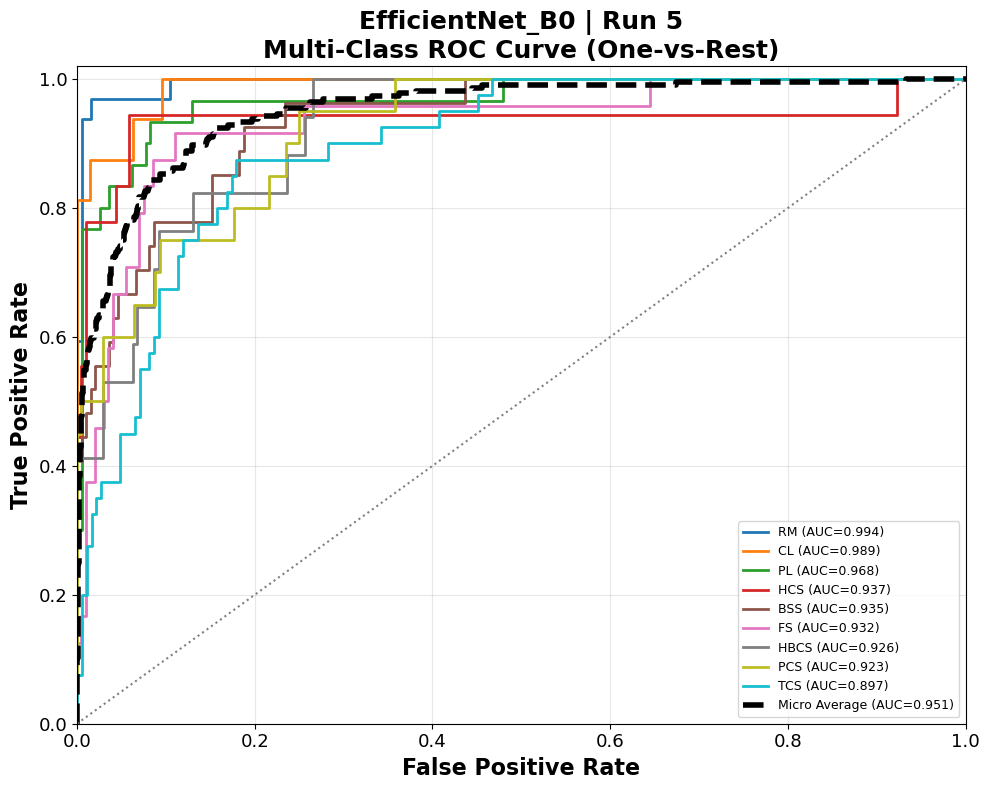


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.994466  Outstanding
1                 CL  0.989183    Excellent
2                 PL  0.967869    Excellent
3                HCS  0.937163    Excellent
4                BSS  0.935138    Excellent
5                 FS  0.931667    Excellent
6               HBCS  0.926115    Excellent
7                PCS  0.922794    Excellent
8                TCS  0.896875         Good
9      Micro Average  0.950544      Summary
10     Macro Average  0.944586      Summary
11  Weighted Average  0.943029      Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 8/9

Best Class                  : RM (Outstanding)
Best AUC                    : 0.9945

Worst Class                 : TCS (Good)
Worst AUC                   : 0.8969

Micro Aver


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 8.081 sec
Time / Image     : 0.036074 sec
Computing Metrics : EfficientNet_B1 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.6696
Precision (Macro)     : 0.6613
Recall (Macro)        : 0.6629
F1 Score (Macro)      : 0.6587
Precision (Weighted)  : 0.6744
Recall (Weighted)     : 0.6696
F1 Score (Weighted)   : 0.6694
Balanced Accuracy     : 0.6629
Cohen Kappa           : 0.6245
MCC                   : 0.6251
Log Loss              : 0.9877

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\EfficientNet_B1_Run1_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\M

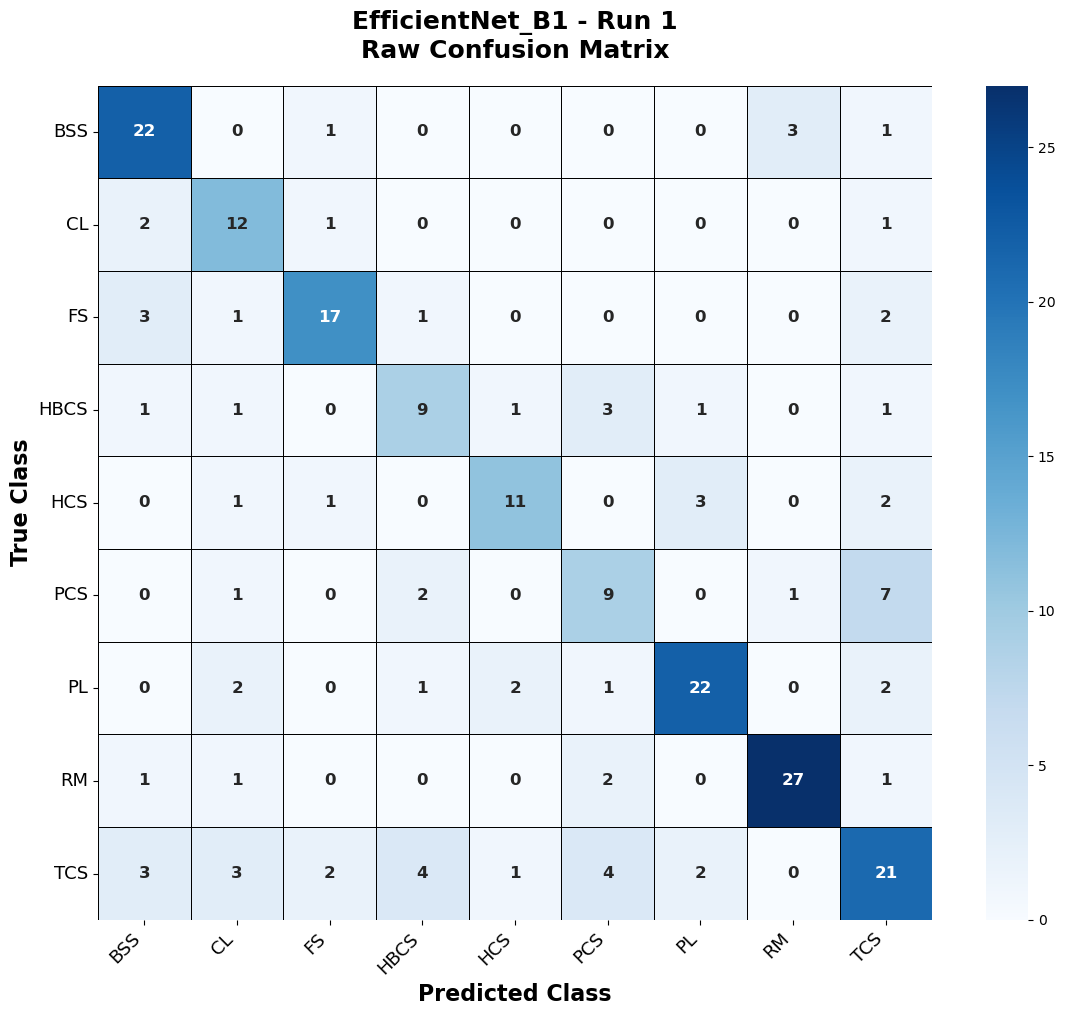

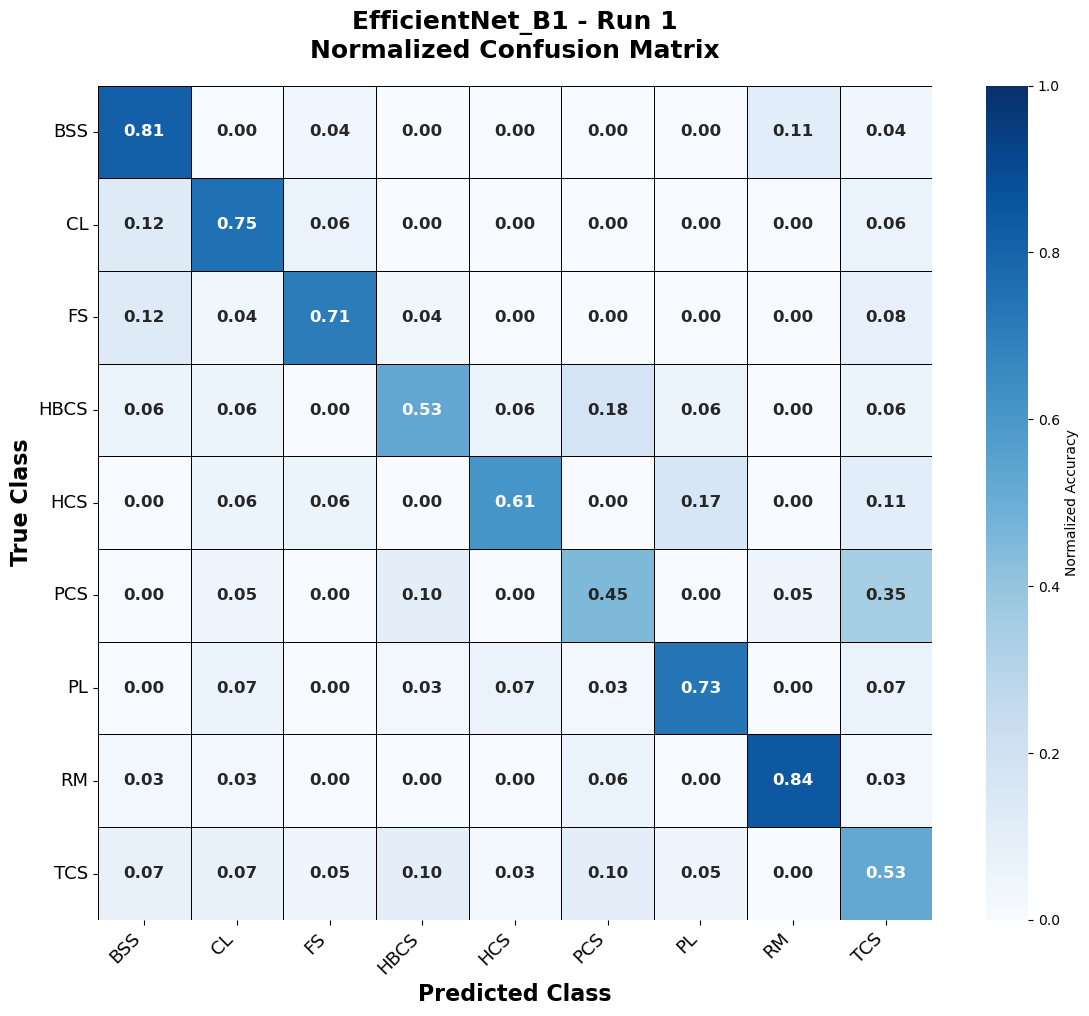


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run1_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run1_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run1_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run1_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Bench

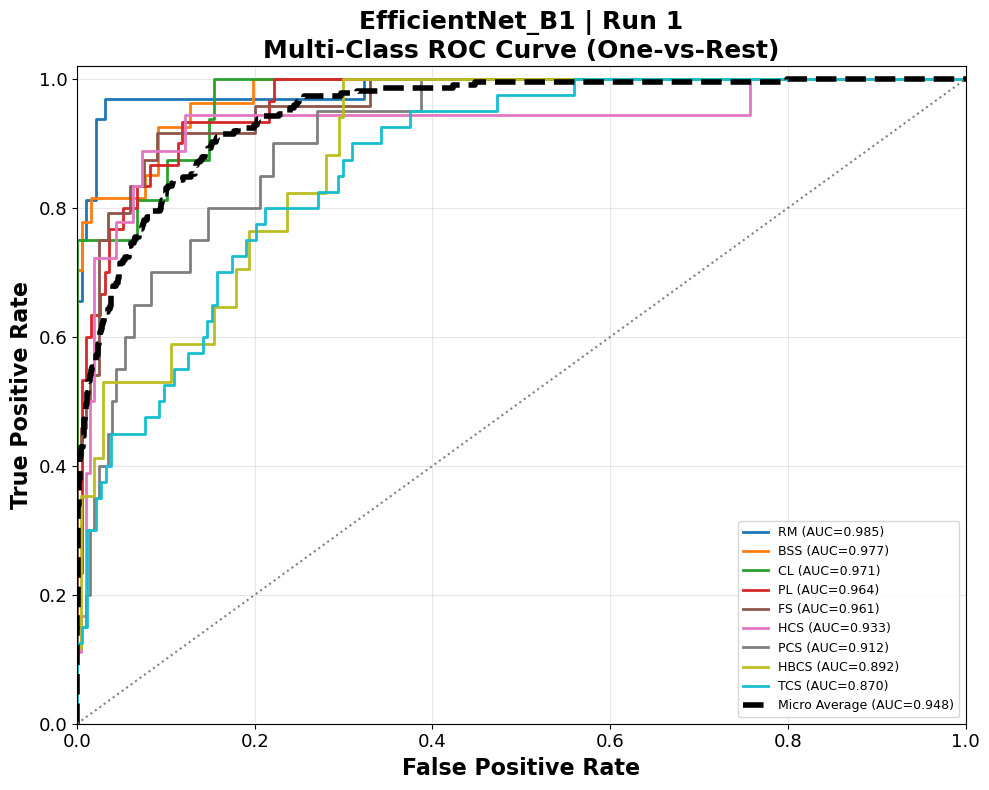


AUC Values
--------------------------------------------------------------------------------
               Class       AUC Performance
0                 RM  0.985189   Excellent
1                BSS  0.977439   Excellent
2                 CL  0.970553   Excellent
3                 PL  0.963918   Excellent
4                 FS  0.960625   Excellent
5                HCS  0.932848   Excellent
6                PCS  0.912010   Excellent
7               HBCS  0.891731        Good
8                TCS  0.869837        Good
9      Micro Average  0.947956     Summary
10     Macro Average  0.940461     Summary
11  Weighted Average  0.939297     Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 7/9

Best Class                  : RM (Excellent)
Best AUC                    : 0.9852

Worst Class                 : TCS (Good)
Worst AUC                   : 0.8698

Micro Average            


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 8.036 sec
Time / Image     : 0.035875 sec
Computing Metrics : EfficientNet_B1 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.7054
Precision (Macro)     : 0.7493
Recall (Macro)        : 0.6882
F1 Score (Macro)      : 0.7023
Precision (Weighted)  : 0.7363
Recall (Weighted)     : 0.7054
F1 Score (Weighted)   : 0.7081
Balanced Accuracy     : 0.6882
Cohen Kappa           : 0.6628
MCC                   : 0.6653
Log Loss              : 1.0213

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\EfficientNet_B1_Run2_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\M

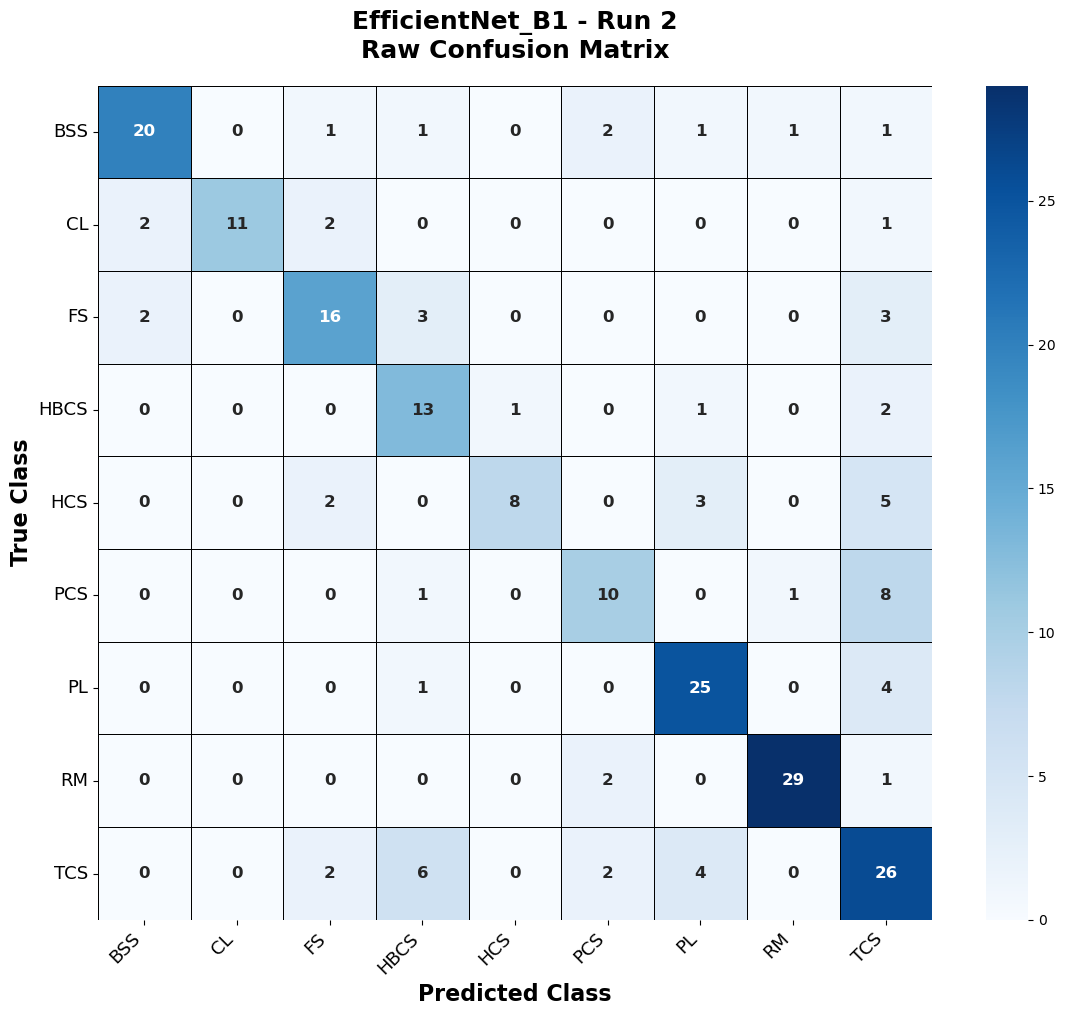

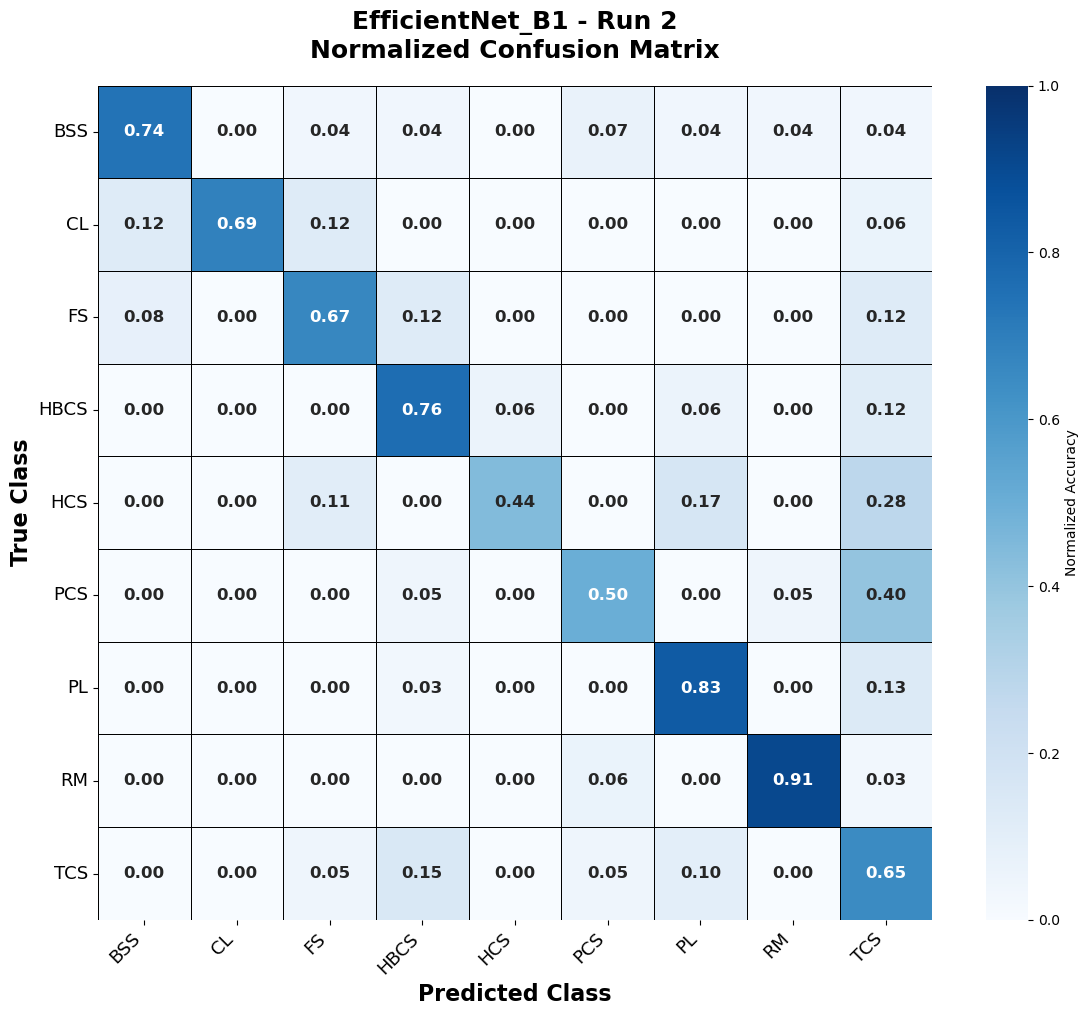


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run2_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run2_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run2_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run2_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Bench

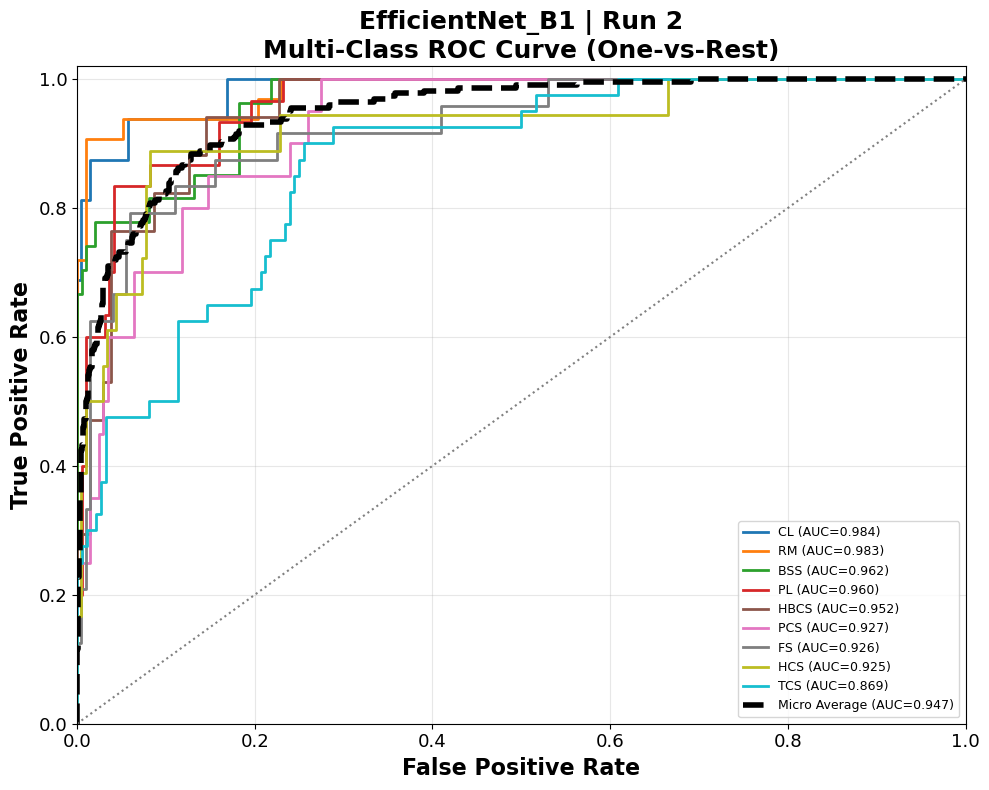


AUC Values
--------------------------------------------------------------------------------
               Class       AUC Performance
0                 CL  0.984375   Excellent
1                 RM  0.982910   Excellent
2                BSS  0.962399   Excellent
3                 PL  0.960309   Excellent
4               HBCS  0.952259   Excellent
5                PCS  0.926716   Excellent
6                 FS  0.925625   Excellent
7                HCS  0.925027   Excellent
8                TCS  0.869293        Good
9      Micro Average  0.946962     Summary
10     Macro Average  0.943213     Summary
11  Weighted Average  0.939094     Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 8/9

Best Class                  : CL (Excellent)
Best AUC                    : 0.9844

Worst Class                 : TCS (Good)
Worst AUC                   : 0.8693

Micro Average            


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 8.052 sec
Time / Image     : 0.035945 sec
Computing Metrics : EfficientNet_B1 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.6741
Precision (Macro)     : 0.6861
Recall (Macro)        : 0.6529
F1 Score (Macro)      : 0.6620
Precision (Weighted)  : 0.6855
Recall (Weighted)     : 0.6741
F1 Score (Weighted)   : 0.6724
Balanced Accuracy     : 0.6529
Cohen Kappa           : 0.6267
MCC                   : 0.6290
Log Loss              : 1.1530

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\EfficientNet_B1_Run3_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\M

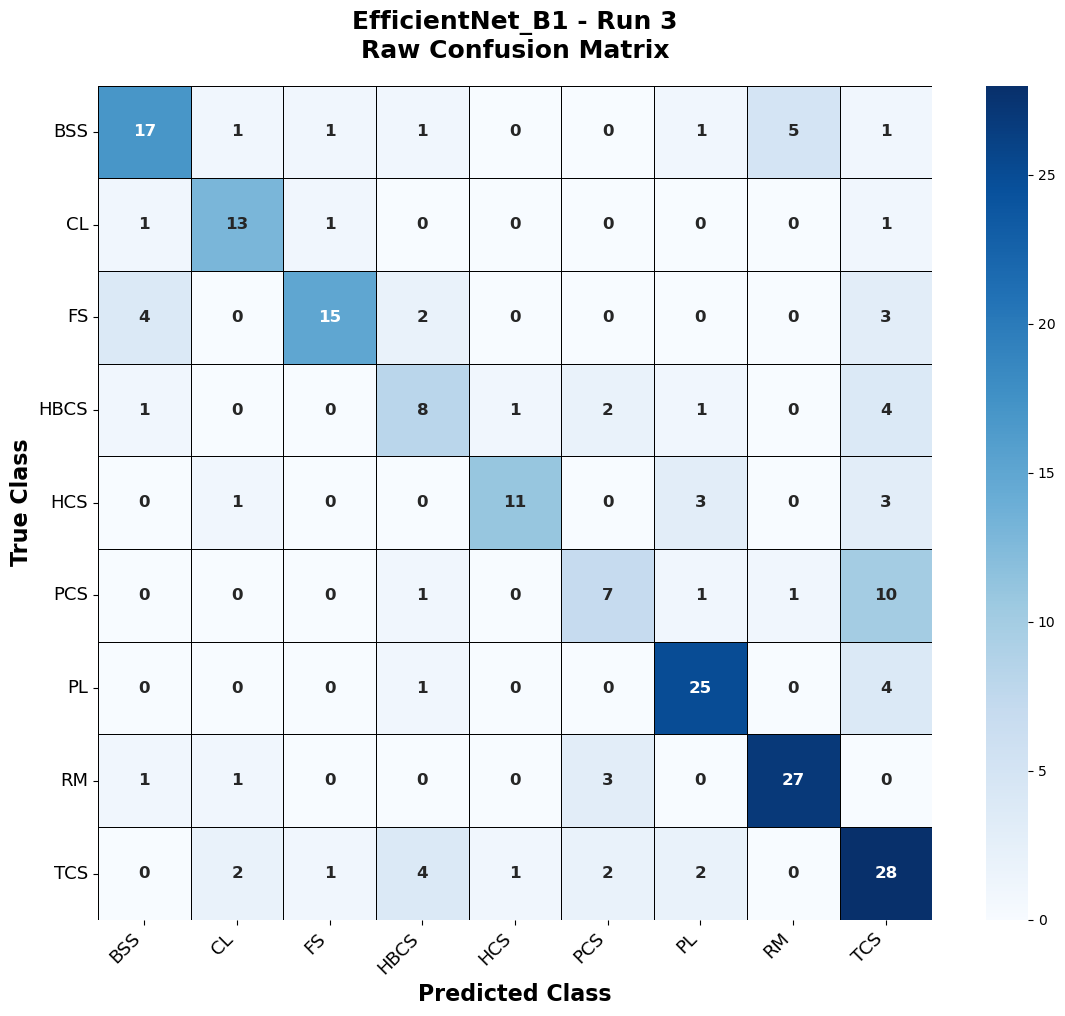

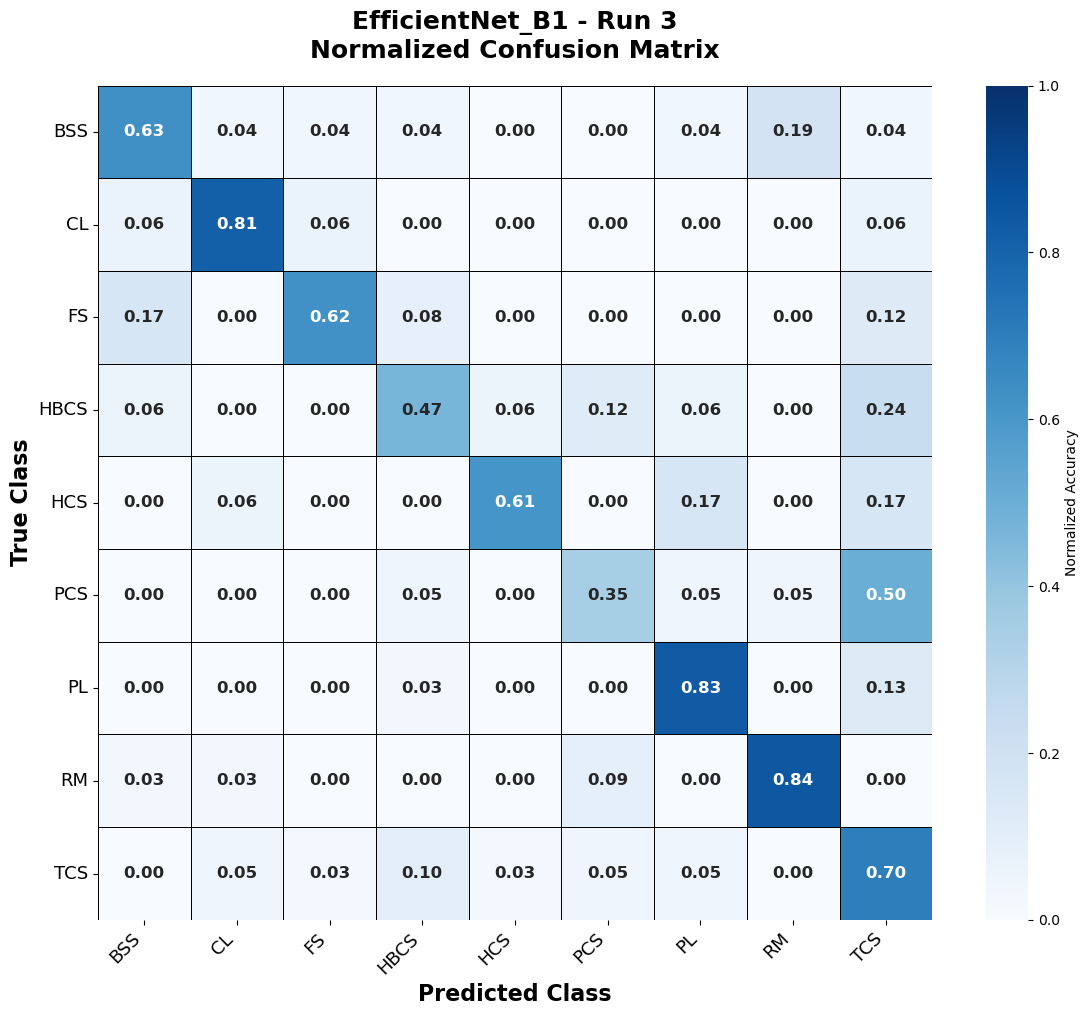


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run3_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run3_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run3_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run3_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Bench

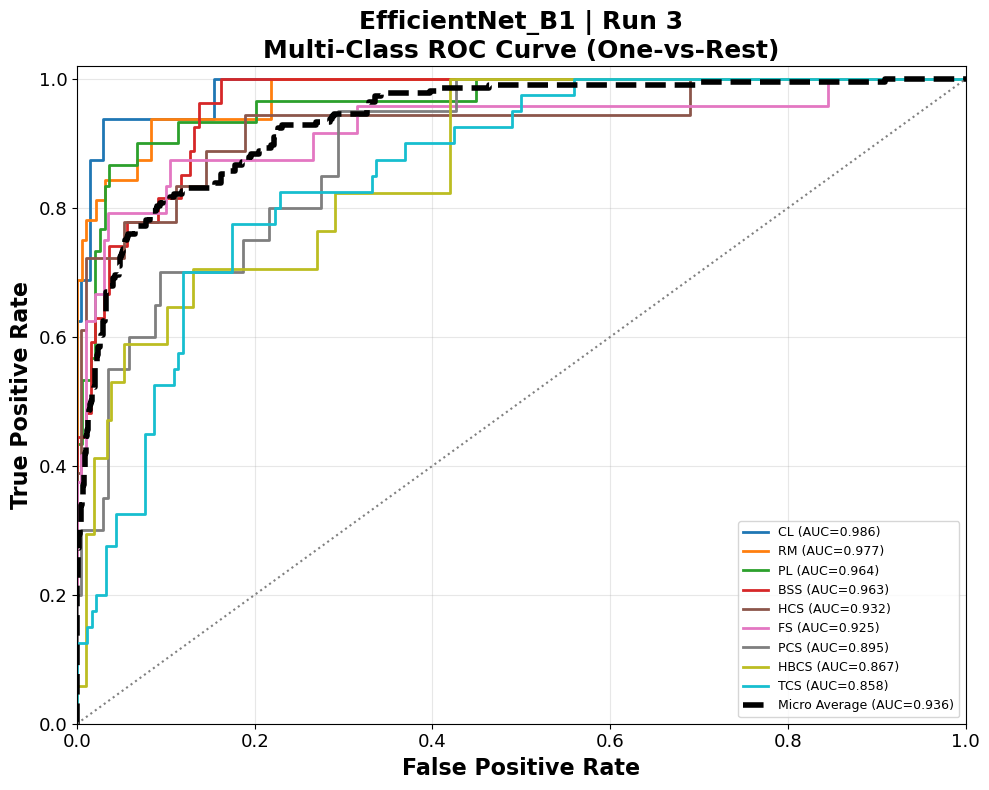


AUC Values
--------------------------------------------------------------------------------
               Class       AUC Performance
0                 CL  0.985577   Excellent
1                 RM  0.976725   Excellent
2                 PL  0.963746   Excellent
3                BSS  0.962963   Excellent
4                HCS  0.931769   Excellent
5                 FS  0.925000   Excellent
6                PCS  0.894608        Good
7               HBCS  0.867292        Good
8                TCS  0.858016        Good
9      Micro Average  0.935821     Summary
10     Macro Average  0.929522     Summary
11  Weighted Average  0.927971     Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 6/9

Best Class                  : CL (Excellent)
Best AUC                    : 0.9856

Worst Class                 : TCS (Good)
Worst AUC                   : 0.8580

Micro Average            


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 8.555 sec
Time / Image     : 0.038190 sec
Computing Metrics : EfficientNet_B1 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.6786
Precision (Macro)     : 0.6888
Recall (Macro)        : 0.6640
F1 Score (Macro)      : 0.6704
Precision (Weighted)  : 0.6916
Recall (Weighted)     : 0.6786
F1 Score (Weighted)   : 0.6806
Balanced Accuracy     : 0.6640
Cohen Kappa           : 0.6337
MCC                   : 0.6344
Log Loss              : 1.1104

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\EfficientNet_B1_Run4_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\M

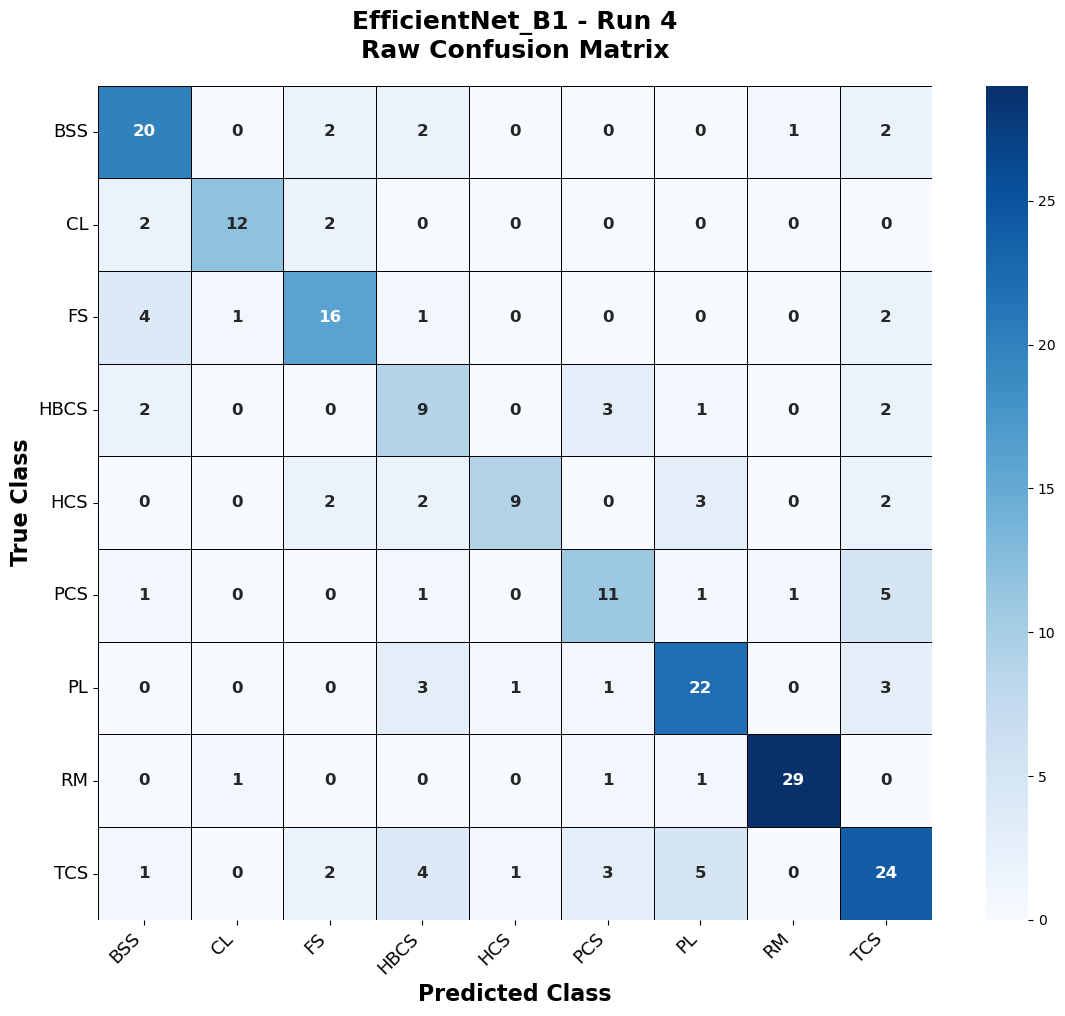

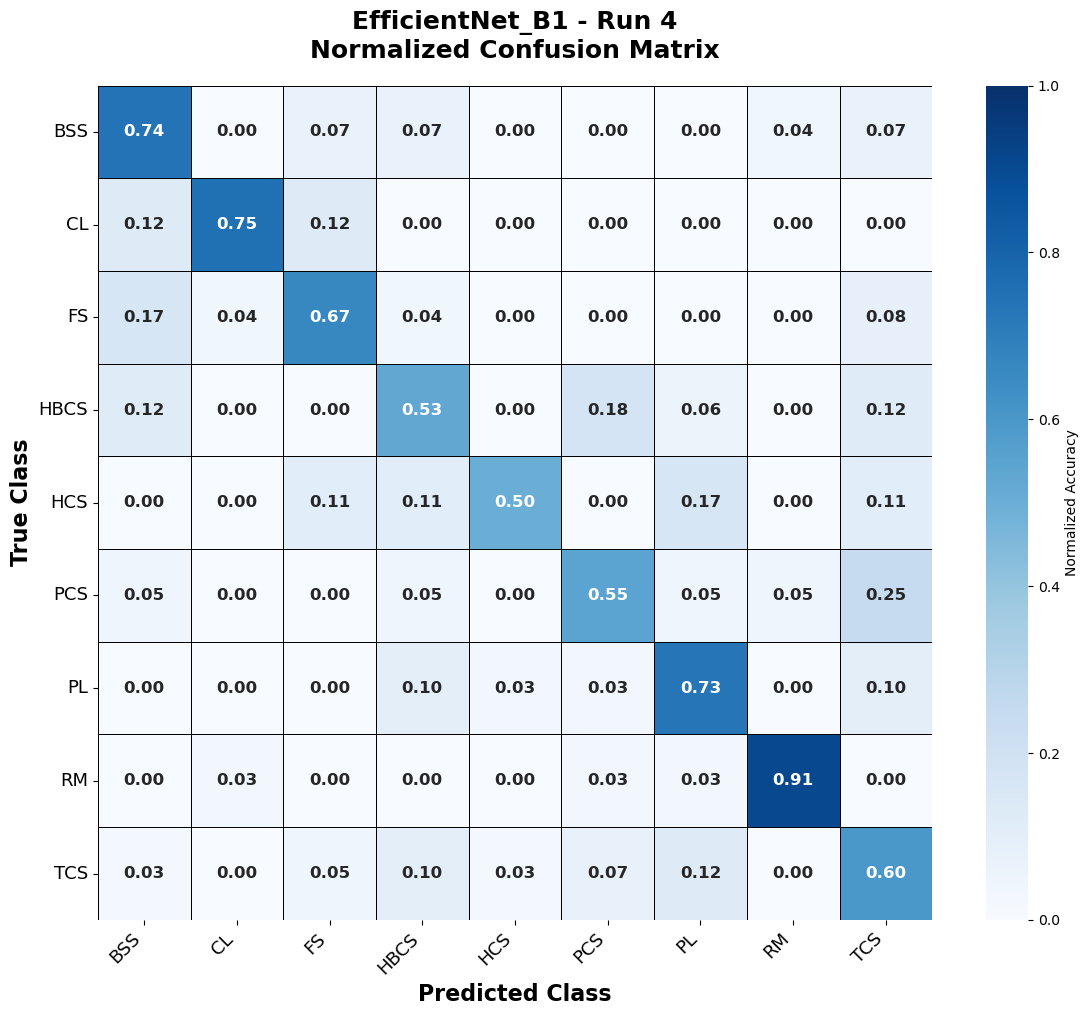


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run4_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run4_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run4_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run4_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Bench

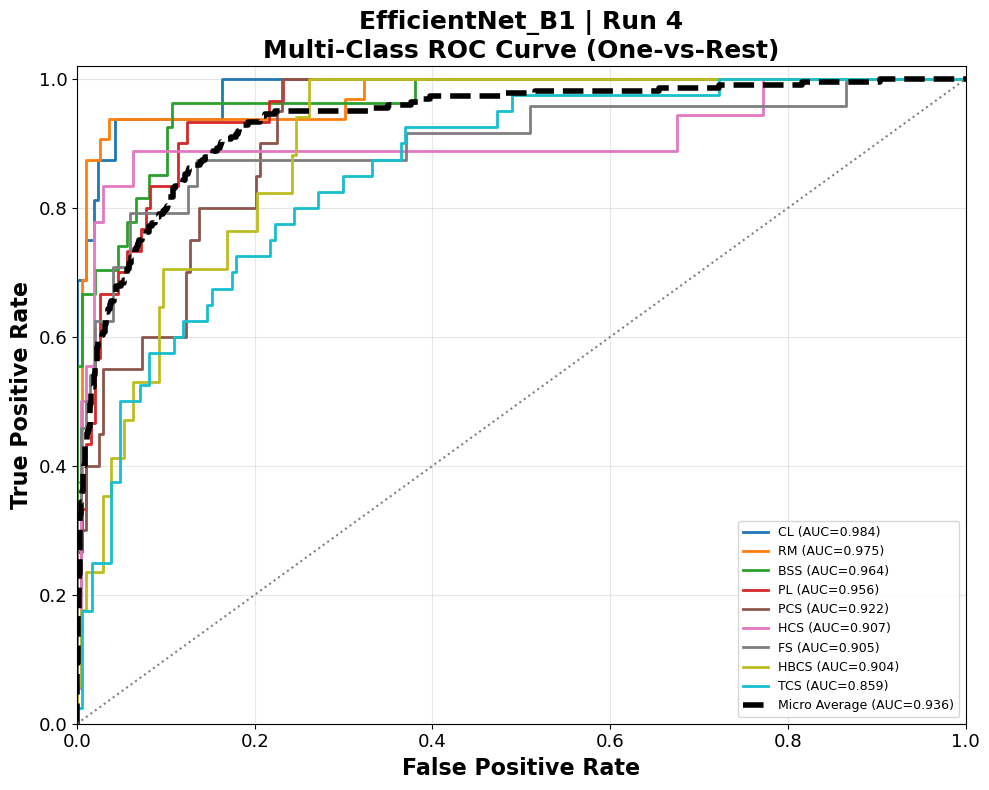


AUC Values
--------------------------------------------------------------------------------
               Class       AUC Performance
0                 CL  0.983774   Excellent
1                 RM  0.974935   Excellent
2                BSS  0.963903   Excellent
3                 PL  0.955670   Excellent
4                PCS  0.922059   Excellent
5                HCS  0.907497   Excellent
6                 FS  0.904792   Excellent
7               HBCS  0.903950   Excellent
8                TCS  0.859103        Good
9      Micro Average  0.935552     Summary
10     Macro Average  0.930631     Summary
11  Weighted Average  0.927929     Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 8/9

Best Class                  : CL (Excellent)
Best AUC                    : 0.9838

Worst Class                 : TCS (Good)
Worst AUC                   : 0.8591

Micro Average            


Inference Summary
----------------------------------------
Images Evaluated : 224
Total Time       : 8.136 sec
Time / Image     : 0.036323 sec
Computing Metrics : EfficientNet_B1 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.6116
Precision (Macro)     : 0.6096
Recall (Macro)        : 0.5892
F1 Score (Macro)      : 0.5914
Precision (Weighted)  : 0.6117
Recall (Weighted)     : 0.6116
F1 Score (Weighted)   : 0.6042
Balanced Accuracy     : 0.5892
Cohen Kappa           : 0.5552
MCC                   : 0.5571
Log Loss              : 1.1389

Files Saved Successfully
--------------------------------------------------
Metrics CSV              : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Metrics\EfficientNet_B1_Run5_Metrics.csv
Classification Report    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\M

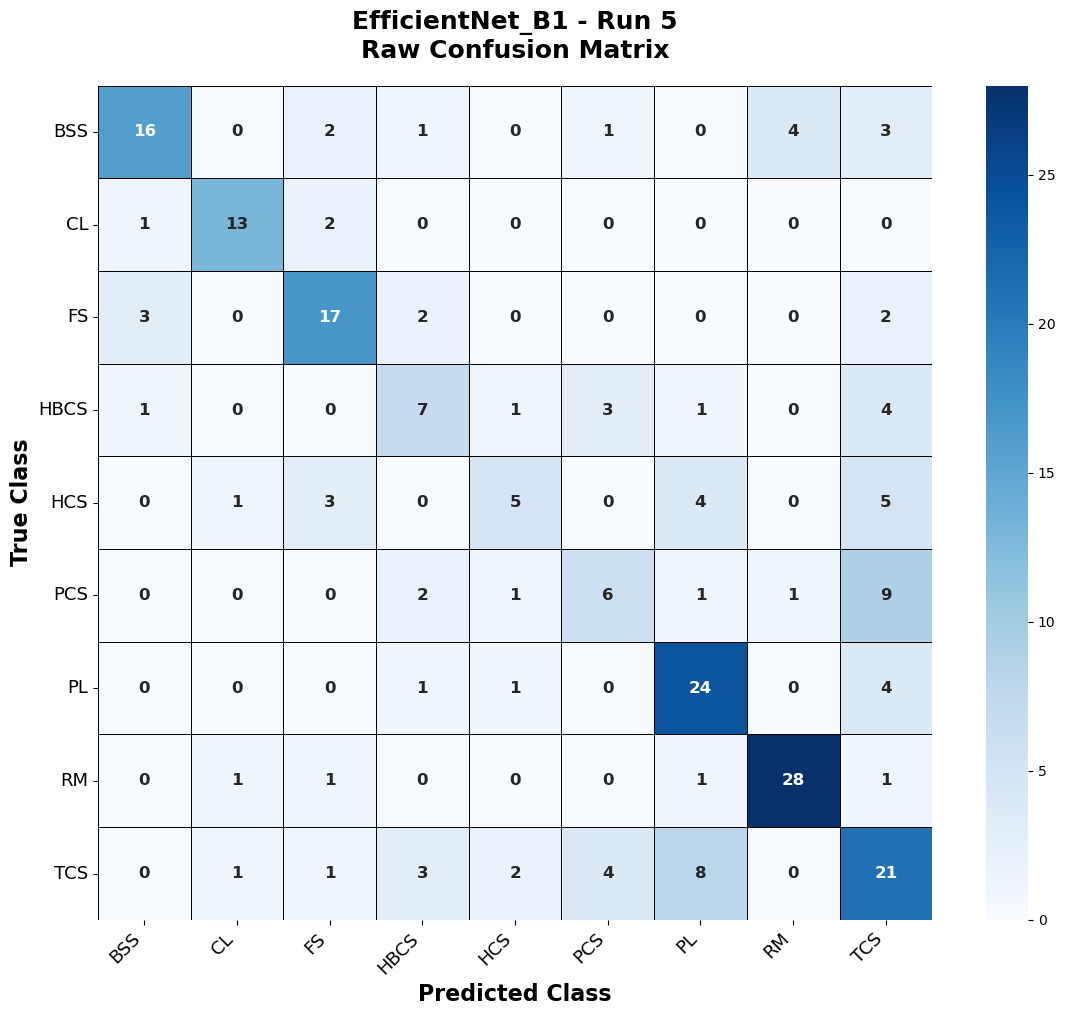

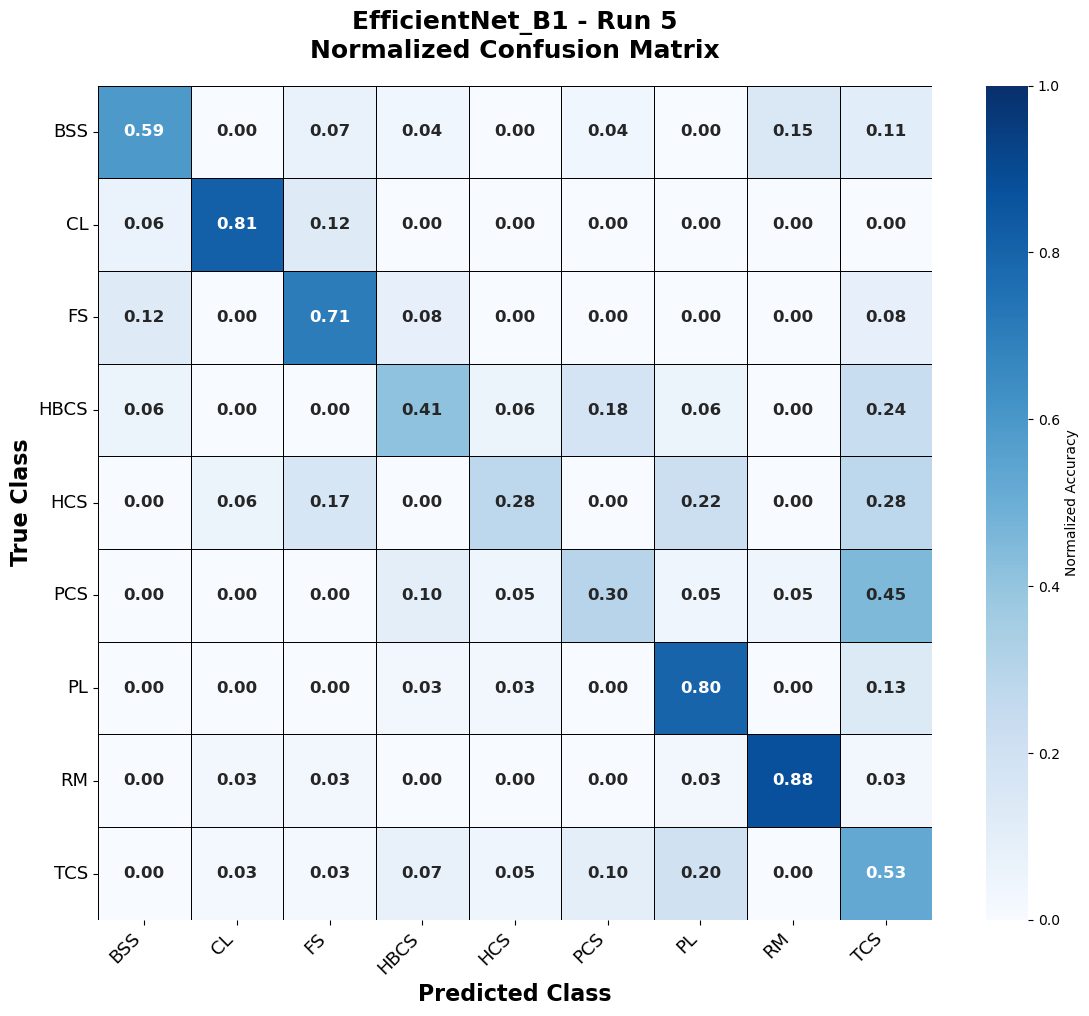


✓ Confusion matrices saved successfully

Files Saved Successfully
------------------------------------------------------------
Raw Confusion CSV          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run5_Raw.csv
Normalized Confusion CSV   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run5_Normalized.csv
Raw Confusion PNG          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run5_Raw.png
Normalized Confusion PNG   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Confusion_Matrix\EfficientNet_B1_Run5_Normalized.png
Most Confused Classes CSV  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Bench

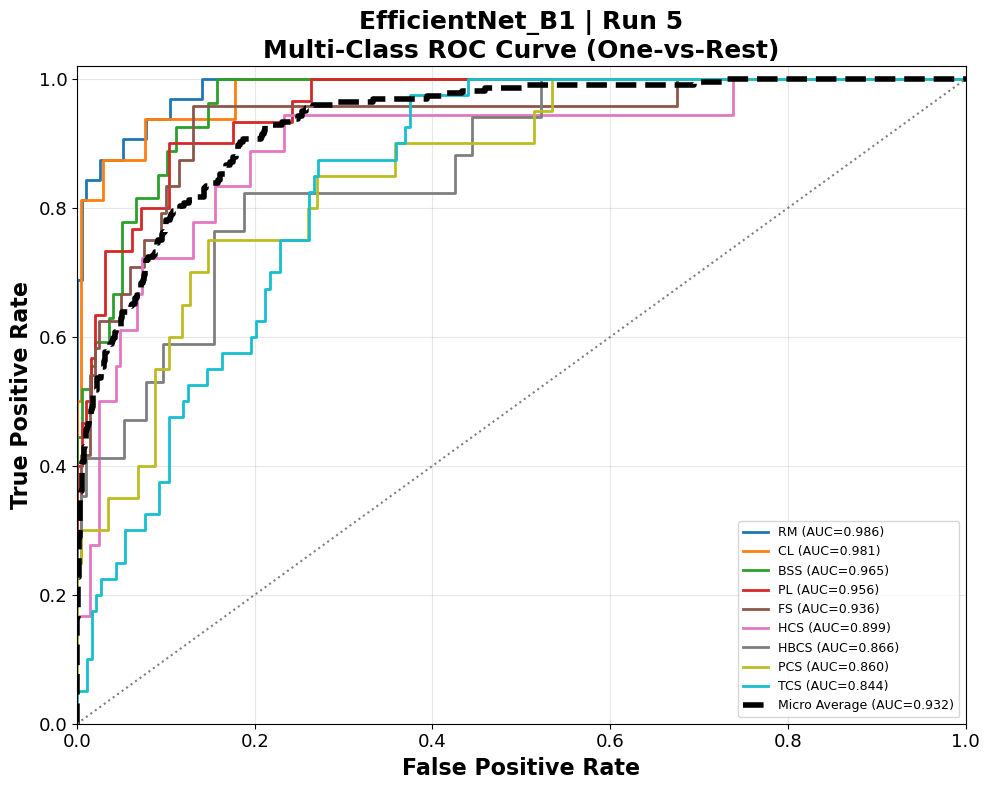


AUC Values
--------------------------------------------------------------------------------
               Class       AUC Performance
0                 RM  0.986491   Excellent
1                 CL  0.980769   Excellent
2                BSS  0.964843   Excellent
3                 PL  0.956357   Excellent
4                 FS  0.935833   Excellent
5                HCS  0.899407        Good
6               HBCS  0.865587        Good
7                PCS  0.859804        Good
8                TCS  0.844158        Good
9      Micro Average  0.931616     Summary
10     Macro Average  0.921472     Summary
11  Weighted Average  0.921108     Summary

ROC Summary
--------------------------------------------------------------------------------
Number of Classes           : 9
Excellent ROC (AUC ≥ 0.90)  : 5/9

Best Class                  : RM (Excellent)
Best AUC                    : 0.9865

Worst Class                 : TCS (Good)
Worst AUC                   : 0.8442

Micro Average            

In [75]:
# ============================================================
# SECTION 13 : BATCH EVALUATION OF ALL CNN MODELS
# ============================================================

import traceback

print("=" * 80)
print("SECTION 13 : BATCH EVALUATION OF ALL CNN MODELS")
print("=" * 80)

master_benchmark = []

failed_runs = []

total_jobs = TOTAL_EVALUATIONS

job = 1

for model_name in MODEL_LIST:

    print("\n" + "=" * 80)
    print(f"MODEL : {model_name}")
    print("=" * 80)

    for run, seed in enumerate(RUN_SEEDS, start=1):

        print("\n" + "-" * 80)
        print(f"[{job}/{total_jobs}] Evaluating {model_name} | Run {run}")
        print("-" * 80)

        current_step = "Initialization"

        try:

            # --------------------------------------------------------
            # Evaluate Model
            # --------------------------------------------------------

            current_step = "Evaluate Model"
            result = evaluate_model(model_name, run)

            # --------------------------------------------------------
            # Compute Metrics
            # --------------------------------------------------------

            current_step = "Compute Metrics"
            result = compute_metrics(result)

            # --------------------------------------------------------
            # Confusion Matrix
            # --------------------------------------------------------

            current_step = "Confusion Matrix"
            result = plot_confusion_matrix(result)

            # --------------------------------------------------------
            # Prediction Table
            # --------------------------------------------------------

            current_step = "Build Prediction Table"
            result = build_prediction_table(result)

            # --------------------------------------------------------
            # Prediction Summary
            # --------------------------------------------------------

            current_step = "Prediction Summary"
            result = prediction_summary(result)

            # --------------------------------------------------------
            # Prediction Analysis
            # --------------------------------------------------------

            current_step = "Prediction Analysis"
            result = analyze_predictions(result)

            # --------------------------------------------------------
            # Confidence Analysis
            # --------------------------------------------------------

            current_step = "Class-wise Confidence Analysis"
            result = classwise_confidence_analysis(result)

            # --------------------------------------------------------
            # ROC & AUC
            # --------------------------------------------------------

            current_step = "ROC Analysis"
            result = plot_multiclass_roc(result)

            # --------------------------------------------------------
            # Misclassification Analysis
            # --------------------------------------------------------

            current_step = "Misclassification Analysis"
            result = misclassification_analysis(result)

            # --------------------------------------------------------
            # Benchmark Summary
            # --------------------------------------------------------

            current_step = "Benchmark Summary"
            result = benchmark_summary(result)

            # --------------------------------------------------------
            # Evaluation Summary
            # --------------------------------------------------------

            current_step = "Evaluation Summary"
            result = evaluation_summary(result)

            # --------------------------------------------------------
            # Store Benchmark
            # --------------------------------------------------------

            current_step = "Store Benchmark"

            master_benchmark.append(result["benchmark_summary"])

            print("\n✓ Evaluation Completed Successfully")

        except Exception as e:

            print(f"\n✗ Evaluation Failed")
            print(f"Model : {model_name}")
            print(f"Run   : {run}")
            print(f"Step  : {current_step}")
            print(f"Error : {e}")

            traceback.print_exc()

            failed_runs.append({

                "Model": model_name,
                "Run": run,
                "Step": current_step,
                "Error": str(e)

            })

        job += 1

In [76]:
print(len(master_benchmark))
print(len(failed_runs))

25
0


In [77]:
# ============================================================
# CREATE MASTER BENCHMARK
# ============================================================

print("\n" + "=" * 80)
print("CREATING MASTER BENCHMARK")
print("=" * 80)

if len(master_benchmark) > 0:

    master_benchmark_df = pd.concat(
        master_benchmark,
        ignore_index=True
    )

    master_benchmark_file = (
        BENCHMARK_DIR /
        "CNN_Master_Benchmark.csv"
    )

    master_benchmark_df.to_csv(
        master_benchmark_file,
        index=False
    )

    print("\n✓ Master Benchmark Saved")

    print(master_benchmark_file.resolve())

    display(master_benchmark_df)

else:

    master_benchmark_df = pd.DataFrame()

    print("No benchmark data generated.")


CREATING MASTER BENCHMARK

✓ Master Benchmark Saved
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Benchmark\CNN_Master_Benchmark.csv


,Model,Run,Total Images,Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Weighted,Recall Weighted,F1 Weighted,...,Cohen Kappa,MCC,Log Loss,Parameters,Trainable Parameters,"Inference Time (Total, s)",Inference Time/Image (ms),Micro AUC,Macro AUC,Weighted AUC
0,ResNet50,1,224,0.8125,0.8368,0.7987,0.8139,0.8223,0.8125,0.8136,...,0.7854,0.7867,0.7394,25619008,25619008,11.0177,49.1862,0.9774,0.9756,0.9741
1,ResNet50,2,224,0.7589,0.7706,0.7387,0.7492,0.7654,0.7589,0.7565,...,0.7241,0.7257,0.8651,25619008,25619008,9.7671,43.6031,0.9708,0.9666,0.9672
2,ResNet50,3,224,0.7098,0.7030,0.6953,0.6964,0.7088,0.7098,0.7064,...,0.6690,0.6697,0.8547,25619008,25619008,10.5510,47.1026,0.9601,0.9556,0.9558
3,ResNet50,4,224,0.7679,0.7754,0.7420,0.7537,0.7712,0.7679,0.7652,...,0.7344,0.7355,0.8043,25619008,25619008,10.5550,47.1207,0.9691,0.9665,0.9665
4,ResNet50,5,224,0.7723,0.7731,0.7597,0.7626,0.7702,0.7723,0.7682,...,0.7403,0.7408,0.8158,25619008,25619008,9.6431,43.0495,0.9690,0.9655,0.9640
5,DenseNet121,1,224,0.8080,0.8194,0.7841,0.7928,0.8132,0.8080,0.8036,...,0.7803,0.7819,0.7734,8012160,8012160,10.5452,47.0768,0.9741,0.9712,0.9697
6,DenseNet121,2,224,0.7500,0.7569,0.7325,0.7400,0.7519,0.7500,0.7473,...,0.7146,0.7153,0.8288,8012160,8012160,10.3111,46.0315,0.9635,0.9597,0.9600
7,DenseNet121,3,224,0.7991,0.7969,0.7850,0.7885,0.7978,0.7991,0.7965,...,0.7710,0.7715,0.7030,8012160,8012160,10.3917,46.3914,0.9768,0.9724,0.9706
8,DenseNet121,4,224,0.7589,0.8197,0.7201,0.7378,0.7922,0.7589,0.7515,...,0.7228,0.7267,0.8994,8012160,8012160,11.3301,50.5807,0.9710,0.9683,0.9679
9,DenseNet121,5,224,0.7411,0.7362,0.7258,0.7276,0.7415,0.7411,0.7386,...,0.7048,0.7053,0.7467,8012160,8012160,11.1564,49.8053,0.9708,0.9656,0.9647


In [78]:
# ============================================================
# FAILED RUNS
# ============================================================

if len(failed_runs) > 0:

    failed_df = pd.DataFrame(failed_runs)

    failed_file = (
        BENCHMARK_DIR /
        "CNN_Failed_Runs.csv"
    )

    failed_df.to_csv(
        failed_file,
        index=False
    )

    print("\nSome evaluations failed.")

    print(failed_file.resolve())

    display(failed_df)

else:

    print("\n✓ All models evaluated successfully.")


✓ All models evaluated successfully.


In [79]:
# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("CNN BATCH EVALUATION COMPLETED")
print("=" * 80)

print(f"Total Jobs          : {total_jobs}")
print(f"Successful Jobs     : {len(master_benchmark)}")
print(f"Failed Jobs         : {len(failed_runs)}")

print("=" * 80)


CNN BATCH EVALUATION COMPLETED
Total Jobs          : 25
Successful Jobs     : 25
Failed Jobs         : 0


In [ ]:
print(master_benchmark[0].columns.tolist())

In [83]:
# ============================================================
# SECTION 14 : CNN BENCHMARK AGGREGATION
# ============================================================

print("=" * 80)
print("SECTION 14 : CNN BENCHMARK AGGREGATION")
print("=" * 80)

# ------------------------------------------------------------
# Create Master DataFrame
# ------------------------------------------------------------

master_df = pd.concat(master_benchmark, ignore_index=True)

print(f"\nTotal Evaluations : {len(master_df)}")
print(f"Models            : {master_df['Model'].nunique()}")

# ------------------------------------------------------------
# Metrics to Aggregate
# ------------------------------------------------------------

metric_columns = [

    "Accuracy",

    "Precision Macro",
    "Recall Macro",
    "F1 Macro",

    "Precision Weighted",
    "Recall Weighted",
    "F1 Weighted",

    "Balanced Accuracy",

    "Cohen Kappa",

    "MCC",

    "Log Loss",

    "Micro AUC",
    "Macro AUC",
    "Weighted AUC",

    "Inference Time (Total, s)",
    "Inference Time/Image (ms)"

]

# ------------------------------------------------------------
# Aggregate Statistics
# ------------------------------------------------------------

summary_rows = []

for model in MODEL_LIST:

    df_model = master_df[master_df["Model"] == model]

    row = {
        "Model": model,
        "Runs": len(df_model)
    }

    for metric in metric_columns:

        row[f"{metric} Mean"]  = df_model[metric].mean()
        row[f"{metric} Std"]   = df_model[metric].std()
        row[f"{metric} Best"]  = df_model[metric].max()
        row[f"{metric} Worst"] = df_model[metric].min()

    summary_rows.append(row)

cnn_summary = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# Round Numeric Columns
# ------------------------------------------------------------

numeric_cols = cnn_summary.select_dtypes(include="number").columns

cnn_summary[numeric_cols] = cnn_summary[numeric_cols].round(4)

# ------------------------------------------------------------
# Store Result
# ------------------------------------------------------------

CNN_BENCHMARK_SUMMARY = cnn_summary

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nCNN Benchmark Summary")
display(CNN_BENCHMARK_SUMMARY)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

summary_file = BENCHMARK_DIR / "CNN_Benchmark_Summary.csv"

CNN_BENCHMARK_SUMMARY.to_csv(
    summary_file,
    index=False
)

print("\n✓ CNN Benchmark Summary Saved Successfully")
print(summary_file.resolve())

SECTION 14 : CNN BENCHMARK AGGREGATION

Total Evaluations : 25
Models            : 5

CNN Benchmark Summary


,Model,Runs,Accuracy Mean,Accuracy Std,Accuracy Best,Accuracy Worst,Precision Macro Mean,Precision Macro Std,Precision Macro Best,Precision Macro Worst,...,Weighted AUC Best,Weighted AUC Worst,"Inference Time (Total, s) Mean","Inference Time (Total, s) Std","Inference Time (Total, s) Best","Inference Time (Total, s) Worst",Inference Time/Image (ms) Mean,Inference Time/Image (ms) Std,Inference Time/Image (ms) Best,Inference Time/Image (ms) Worst
0,ResNet50,5,0.7643,0.0367,0.8125,0.7098,0.7718,0.0474,0.8368,0.7030,...,0.9741,0.9558,10.3068,0.5827,11.0177,9.6431,46.0124,2.6016,49.1862,43.0495
1,DenseNet121,5,0.7714,0.0302,0.8080,0.7411,0.7858,0.0377,0.8197,0.7362,...,0.9706,0.9600,10.7469,0.4649,11.3301,10.3111,47.9771,2.0755,50.5807,46.0315
2,MobileNetV3,5,0.6830,0.0200,0.7098,0.6607,0.7136,0.0163,0.7376,0.6931,...,0.9645,0.9500,3.4097,0.1367,3.6425,3.3144,15.2220,0.6101,16.2612,14.7964
3,EfficientNet_B0,5,0.7009,0.0084,0.7143,0.6920,0.7056,0.0184,0.7337,0.6911,...,0.9577,0.9421,5.1747,0.0428,5.2327,5.1253,23.1012,0.1911,23.3601,22.8807
4,EfficientNet_B1,5,0.6679,0.0344,0.7054,0.6116,0.6790,0.0505,0.7493,0.6096,...,0.9393,0.9211,8.1719,0.2173,8.5546,8.0361,36.4815,0.9704,38.1903,35.8753



✓ CNN Benchmark Summary Saved Successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Benchmark\CNN_Benchmark_Summary.csv


In [84]:
# ============================================================
# SECTION 15 : CNN MEAN ± STD BENCHMARK TABLE
# ============================================================

print("=" * 80)
print("SECTION 15 : CNN MEAN ± STD BENCHMARK TABLE")
print("=" * 80)

# ------------------------------------------------------------
# Create Publication Table
# ------------------------------------------------------------

publication_rows = []

for _, row in CNN_BENCHMARK_SUMMARY.iterrows():

    publication_rows.append({

        "Model": row["Model"],

        "Runs": int(row["Runs"]),

        "Accuracy":
            f"{row['Accuracy Mean']:.4f} ± {row['Accuracy Std']:.4f}",

        "Precision (Macro)":
            f"{row['Precision Macro Mean']:.4f} ± {row['Precision Macro Std']:.4f}",

        "Recall (Macro)":
            f"{row['Recall Macro Mean']:.4f} ± {row['Recall Macro Std']:.4f}",

        "F1 Score (Macro)":
            f"{row['F1 Macro Mean']:.4f} ± {row['F1 Macro Std']:.4f}",

        "Precision (Weighted)":
            f"{row['Precision Weighted Mean']:.4f} ± {row['Precision Weighted Std']:.4f}",

        "Recall (Weighted)":
            f"{row['Recall Weighted Mean']:.4f} ± {row['Recall Weighted Std']:.4f}",

        "F1 Score (Weighted)":
            f"{row['F1 Weighted Mean']:.4f} ± {row['F1 Weighted Std']:.4f}",

        "Balanced Accuracy":
            f"{row['Balanced Accuracy Mean']:.4f} ± {row['Balanced Accuracy Std']:.4f}",

        "Cohen Kappa":
            f"{row['Cohen Kappa Mean']:.4f} ± {row['Cohen Kappa Std']:.4f}",

        "MCC":
            f"{row['MCC Mean']:.4f} ± {row['MCC Std']:.4f}",

        "Log Loss":
            f"{row['Log Loss Mean']:.4f} ± {row['Log Loss Std']:.4f}",

        "Micro AUC":
            f"{row['Micro AUC Mean']:.4f} ± {row['Micro AUC Std']:.4f}",

        "Macro AUC":
            f"{row['Macro AUC Mean']:.4f} ± {row['Macro AUC Std']:.4f}",

        "Weighted AUC":
            f"{row['Weighted AUC Mean']:.4f} ± {row['Weighted AUC Std']:.4f}",

        "Inference Time/Image (ms)":
            f"{row['Inference Time/Image (ms) Mean']:.2f} ± {row['Inference Time/Image (ms) Std']:.2f}"

    })

# ------------------------------------------------------------
# Create DataFrame
# ------------------------------------------------------------

CNN_PUBLICATION_TABLE = pd.DataFrame(publication_rows)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nPublication Ready CNN Benchmark Table\n")

display(CNN_PUBLICATION_TABLE)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

publication_file = BENCHMARK_DIR / "CNN_Publication_Benchmark_Table.csv"

CNN_PUBLICATION_TABLE.to_csv(
    publication_file,
    index=False
)

print("\n✓ Publication Benchmark Table Saved Successfully")
print(publication_file.resolve())

SECTION 15 : CNN MEAN ± STD BENCHMARK TABLE

Publication Ready CNN Benchmark Table



,Model,Runs,Accuracy,Precision (Macro),Recall (Macro),F1 Score (Macro),Precision (Weighted),Recall (Weighted),F1 Score (Weighted),Balanced Accuracy,Cohen Kappa,MCC,Log Loss,Micro AUC,Macro AUC,Weighted AUC,Inference Time/Image (ms)
0,ResNet50,5,0.7643 ± 0.0367,0.7718 ± 0.0474,0.7469 ± 0.0374,0.7552 ± 0.0418,0.7676 ± 0.0402,0.7643 ± 0.0367,0.7620 ± 0.0382,0.7469 ± 0.0374,0.7306 ± 0.0417,0.7317 ± 0.0418,0.8159 ± 0.0498,0.9693 ± 0.0062,0.9660 ± 0.0071,0.9655 ± 0.0066,46.01 ± 2.60
1,DenseNet121,5,0.7714 ± 0.0302,0.7858 ± 0.0377,0.7495 ± 0.0323,0.7573 ± 0.0308,0.7793 ± 0.0310,0.7714 ± 0.0302,0.7675 ± 0.0302,0.7495 ± 0.0323,0.7387 ± 0.0345,0.7401 ± 0.0344,0.7903 ± 0.0761,0.9712 ± 0.0050,0.9674 ± 0.0051,0.9666 ± 0.0043,47.98 ± 2.08
2,MobileNetV3,5,0.6830 ± 0.0200,0.7136 ± 0.0163,0.6786 ± 0.0187,0.6746 ± 0.0189,0.7087 ± 0.0204,0.6830 ± 0.0200,0.6770 ± 0.0214,0.6786 ± 0.0187,0.6392 ± 0.0231,0.6437 ± 0.0231,0.9501 ± 0.0739,0.9551 ± 0.0048,0.9594 ± 0.0051,0.9551 ± 0.0055,15.22 ± 0.61
3,EfficientNet_B0,5,0.7009 ± 0.0084,0.7056 ± 0.0184,0.6862 ± 0.0126,0.6896 ± 0.0113,0.7053 ± 0.0094,0.7009 ± 0.0084,0.6972 ± 0.0087,0.6862 ± 0.0126,0.6590 ± 0.0095,0.6604 ± 0.0095,0.9638 ± 0.0864,0.9537 ± 0.0056,0.9491 ± 0.0068,0.9481 ± 0.0062,23.10 ± 0.19
4,EfficientNet_B1,5,0.6679 ± 0.0344,0.6790 ± 0.0505,0.6514 ± 0.0371,0.6570 ± 0.0405,0.6799 ± 0.0448,0.6679 ± 0.0344,0.6669 ± 0.0383,0.6514 ± 0.0371,0.6206 ± 0.0396,0.6222 ± 0.0397,1.0823 ± 0.0736,0.9396 ± 0.0074,0.9331 ± 0.0088,0.9311 ± 0.0079,36.48 ± 0.97



✓ Publication Benchmark Table Saved Successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Benchmark\CNN_Publication_Benchmark_Table.csv


In [85]:
# ============================================================
# SECTION 16 : CNN MODEL RANKING
# ============================================================

print("=" * 80)
print("SECTION 16 : CNN MODEL RANKING")
print("=" * 80)

# ------------------------------------------------------------
# Use Benchmark Summary
# ------------------------------------------------------------

ranking_df = CNN_BENCHMARK_SUMMARY.copy()

# ------------------------------------------------------------
# Metrics used for Ranking
# ------------------------------------------------------------

higher_better = [

    "Accuracy Mean",

    "Precision Macro Mean",

    "Recall Macro Mean",

    "F1 Macro Mean",

    "Precision Weighted Mean",

    "Recall Weighted Mean",

    "F1 Weighted Mean",

    "Balanced Accuracy Mean",

    "Cohen Kappa Mean",

    "MCC Mean",

    "Micro AUC Mean",

    "Macro AUC Mean",

    "Weighted AUC Mean"

]

lower_better = [

    "Log Loss Mean",

    "Inference Time/Image (ms) Mean"

]

# ------------------------------------------------------------
# Ranking
# ------------------------------------------------------------

for metric in higher_better:

    ranking_df[f"{metric} Rank"] = ranking_df[metric].rank(
        ascending=False,
        method="min"
    )

for metric in lower_better:

    ranking_df[f"{metric} Rank"] = ranking_df[metric].rank(
        ascending=True,
        method="min"
    )

# ------------------------------------------------------------
# Overall Rank Score
# ------------------------------------------------------------

rank_columns = [

    col for col in ranking_df.columns

    if col.endswith(" Rank")

]

ranking_df["Overall Rank Score"] = ranking_df[rank_columns].mean(axis=1)

ranking_df["Overall Rank"] = ranking_df["Overall Rank Score"].rank(
    ascending=True,
    method="min"
).astype(int)

# ------------------------------------------------------------
# Sort
# ------------------------------------------------------------

ranking_df = ranking_df.sort_values(
    "Overall Rank"
).reset_index(drop=True)

# ------------------------------------------------------------
# Store
# ------------------------------------------------------------

CNN_MODEL_RANKING = ranking_df

# ------------------------------------------------------------
# Display Summary
# ------------------------------------------------------------

display(

    CNN_MODEL_RANKING[

        [

            "Overall Rank",

            "Model",

            "Overall Rank Score",

            "Accuracy Mean",

            "F1 Macro Mean",

            "MCC Mean",

            "Macro AUC Mean",

            "Inference Time/Image (ms) Mean"

        ]

    ]

)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

ranking_file = BENCHMARK_DIR / "CNN_Model_Ranking.csv"

CNN_MODEL_RANKING.to_csv(
    ranking_file,
    index=False
)

print("\n✓ CNN Model Ranking Saved Successfully")
print(ranking_file.resolve())

SECTION 16 : CNN MODEL RANKING


,Overall Rank,Model,Overall Rank Score,Accuracy Mean,F1 Macro Mean,MCC Mean,Macro AUC Mean,Inference Time/Image (ms) Mean
0,1,DenseNet121,1.266667,0.7714,0.7573,0.7401,0.9674,47.9771
1,2,ResNet50,2.133333,0.7643,0.7552,0.7317,0.9660,46.0124
2,3,EfficientNet_B0,3.333333,0.7009,0.6896,0.6604,0.9491,23.1012
3,4,MobileNetV3,3.400000,0.6830,0.6746,0.6437,0.9594,15.2220
4,5,EfficientNet_B1,4.866667,0.6679,0.6570,0.6222,0.9331,36.4815



✓ CNN Model Ranking Saved Successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Benchmark\CNN_Model_Ranking.csv


In [88]:
print(CNN_BENCHMARK_SUMMARY.columns.tolist())

['Model', 'Runs', 'Accuracy Mean', 'Accuracy Std', 'Accuracy Best', 'Accuracy Worst', 'Precision Macro Mean', 'Precision Macro Std', 'Precision Macro Best', 'Precision Macro Worst', 'Recall Macro Mean', 'Recall Macro Std', 'Recall Macro Best', 'Recall Macro Worst', 'F1 Macro Mean', 'F1 Macro Std', 'F1 Macro Best', 'F1 Macro Worst', 'Precision Weighted Mean', 'Precision Weighted Std', 'Precision Weighted Best', 'Precision Weighted Worst', 'Recall Weighted Mean', 'Recall Weighted Std', 'Recall Weighted Best', 'Recall Weighted Worst', 'F1 Weighted Mean', 'F1 Weighted Std', 'F1 Weighted Best', 'F1 Weighted Worst', 'Balanced Accuracy Mean', 'Balanced Accuracy Std', 'Balanced Accuracy Best', 'Balanced Accuracy Worst', 'Cohen Kappa Mean', 'Cohen Kappa Std', 'Cohen Kappa Best', 'Cohen Kappa Worst', 'MCC Mean', 'MCC Std', 'MCC Best', 'MCC Worst', 'Log Loss Mean', 'Log Loss Std', 'Log Loss Best', 'Log Loss Worst', 'Micro AUC Mean', 'Micro AUC Std', 'Micro AUC Best', 'Micro AUC Worst', 'Macro AUC

In [89]:
# ============================================================
# SECTION 17 : FINAL CNN BENCHMARK REPORT
# ============================================================

print("=" * 80)
print("SECTION 17 : FINAL CNN BENCHMARK REPORT")
print("=" * 80)

# ------------------------------------------------------------
# Best Overall Model
# ------------------------------------------------------------

best_model = CNN_MODEL_RANKING.iloc[0]

# ------------------------------------------------------------
# Best Models by Metric
# ------------------------------------------------------------

best_accuracy = CNN_BENCHMARK_SUMMARY.loc[
    CNN_BENCHMARK_SUMMARY["Accuracy Mean"].idxmax()
]
best_f1 = CNN_BENCHMARK_SUMMARY.loc[
    CNN_BENCHMARK_SUMMARY["F1 Macro Mean"].idxmax()
]

best_mcc = CNN_BENCHMARK_SUMMARY.loc[
    CNN_BENCHMARK_SUMMARY["MCC Mean"].idxmax()
]

best_auc = CNN_BENCHMARK_SUMMARY.loc[
    CNN_BENCHMARK_SUMMARY["Macro AUC Mean"].idxmax()
]

fastest_model = CNN_BENCHMARK_SUMMARY.loc[
    CNN_BENCHMARK_SUMMARY["Inference Time/Image (ms) Mean"].idxmin()
]

# ------------------------------------------------------------
# Executive Summary
# ------------------------------------------------------------

print("\nFINAL CNN BENCHMARK SUMMARY")
print("-" * 80)

print(f"Best Overall CNN           : {best_model['Model']}")
print(f"Overall Rank               : {best_model['Overall Rank']}")

print()

print(f"Highest Accuracy           : {best_accuracy['Model']} "
      f"({best_accuracy['Accuracy Mean']:.4f})")

print(f"Highest F1 Macro           : {best_f1['Model']} "
      f"({best_f1['F1 Macro Mean']:.4f})")

print(f"Highest MCC                : {best_mcc['Model']} "
      f"({best_mcc['MCC Mean']:.4f})")

print(f"Highest Macro AUC          : {best_auc['Model']} "
      f"({best_auc['Macro AUC Mean']:.4f})")

print(f"Fastest Inference          : {fastest_model['Model']} "
      f"({fastest_model['Inference Time/Image (ms) Mean']:.2f} ms/image)")

print("-" * 80)

# ------------------------------------------------------------
# Save Complete Benchmark Workbook
# ------------------------------------------------------------

excel_file = BENCHMARK_DIR / "CNN_Final_Benchmark_Report.xlsx"

with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:

    master_df.to_excel(
        writer,
        sheet_name="Master Benchmark",
        index=False
    )

    CNN_BENCHMARK_SUMMARY.to_excel(
        writer,
        sheet_name="Benchmark Summary",
        index=False
    )

    CNN_PUBLICATION_TABLE.to_excel(
        writer,
        sheet_name="Publication Table",
        index=False
    )

    CNN_MODEL_RANKING.to_excel(
        writer,
        sheet_name="Model Ranking",
        index=False
    )

print("\n✓ Final Benchmark Workbook Saved Successfully")
print(excel_file.resolve())

# ------------------------------------------------------------
# Store Results
# ------------------------------------------------------------

CNN_FINAL_REPORT = {

    "Master Benchmark": master_df,

    "Benchmark Summary": CNN_BENCHMARK_SUMMARY,

    "Publication Table": CNN_PUBLICATION_TABLE,

    "Model Ranking": CNN_MODEL_RANKING,

    "Best Overall Model": best_model["Model"]

}

print("\n✓ CNN Benchmark Pipeline Completed Successfully")
print("=" * 80)

SECTION 17 : FINAL CNN BENCHMARK REPORT

FINAL CNN BENCHMARK SUMMARY
--------------------------------------------------------------------------------
Best Overall CNN           : DenseNet121
Overall Rank               : 1

Highest Accuracy           : DenseNet121 (0.7714)
Highest F1 Macro           : DenseNet121 (0.7573)
Highest MCC                : DenseNet121 (0.7401)
Highest Macro AUC          : DenseNet121 (0.9674)
Fastest Inference          : MobileNetV3 (15.22 ms/image)
--------------------------------------------------------------------------------

✓ Final Benchmark Workbook Saved Successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Benchmark\CNN_Final_Benchmark_Report.xlsx

✓ CNN Benchmark Pipeline Completed Successfully


In [ ]:
len(result["y_true"])
result["y_prob"].shape

import numpy as np

np.allclose(result["y_prob"].sum(axis=1), 1.0)